## Understand dataset structure

In [1]:
%pip install scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display
import seaborn as sns

In [3]:
import pandas as pd
df = pd.read_csv("../data/energydata_complete.csv")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Dataset shape: (19735, 29)
Columns: ['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']


In [4]:
print(df.dtypes) # feature data type
df.dtypes.value_counts()

date               str
Appliances       int64
lights           int64
T1             float64
RH_1           float64
T2             float64
RH_2           float64
T3             float64
RH_3           float64
T4             float64
RH_4           float64
T5             float64
RH_5           float64
T6             float64
RH_6           float64
T7             float64
RH_7           float64
T8             float64
RH_8           float64
T9             float64
RH_9           float64
T_out          float64
Press_mm_hg    float64
RH_out         float64
Windspeed      float64
Visibility     float64
Tdewpoint      float64
rv1            float64
rv2            float64
dtype: object


float64    26
int64       2
str         1
Name: count, dtype: int64

In [5]:
# Column information
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 29 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   date         19735 non-null  str    
 1   Appliances   19735 non-null  int64  
 2   lights       19735 non-null  int64  
 3   T1           19735 non-null  float64
 4   RH_1         19735 non-null  float64
 5   T2           19735 non-null  float64
 6   RH_2         19735 non-null  float64
 7   T3           19735 non-null  float64
 8   RH_3         19735 non-null  float64
 9   T4           19735 non-null  float64
 10  RH_4         19735 non-null  float64
 11  T5           19735 non-null  float64
 12  RH_5         19735 non-null  float64
 13  T6           19735 non-null  float64
 14  RH_6         19735 non-null  float64
 15  T7           19735 non-null  float64
 16  RH_7         19735 non-null  float64
 17  T8           19735 non-null  float64
 18  RH_8         19735 non-null  float64
 19  T9           19

## Data Quality

In [6]:
# Count missing values in each column
missing_count = df.isnull().sum()

print(missing_count)

date           0
Appliances     0
lights         0
T1             0
RH_1           0
T2             0
RH_2           0
T3             0
RH_3           0
T4             0
RH_4           0
T5             0
RH_5           0
T6             0
RH_6           0
T7             0
RH_7           0
T8             0
RH_8           0
T9             0
RH_9           0
T_out          0
Press_mm_hg    0
RH_out         0
Windspeed      0
Visibility     0
Tdewpoint      0
rv1            0
rv2            0
dtype: int64


**Missing Value Analysis**

The Appliances Energy Prediction dataset contains 19,735 observations and 29 columns. Missing-value analysis was performed using the Pandas `isnull()` function. The results indicate that all columns contain zero missing values, corresponding to a missing-value percentage of 0%.

Therefore, no missing-value imputation or row deletion is required based on this analysis.

In [7]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [8]:
duplicate_dates = df["date"].duplicated().sum()

print("Duplicate timestamps:", duplicate_dates)

Duplicate timestamps: 0


### Duplicate Row Analysis

Duplicate row analysis was performed using the Pandas `duplicated()` function. The results indicate that the dataset contains zero completely duplicated observations, representing a duplicate percentage of 0%.

Therefore, no removal of completely duplicated rows is required. Duplicate timestamps will be checked separately to verify the consistency of the time-series observations.

## Invalid Value Detection

In [9]:
# Minimum values
print(df.min(numeric_only=True))

# Maximum values
print(df.max(numeric_only=True))

Appliances      10.000000
lights           0.000000
T1              16.790000
RH_1            27.023333
T2              16.100000
RH_2            20.463333
T3              17.200000
RH_3            28.766667
T4              15.100000
RH_4            27.660000
T5              15.330000
RH_5            29.815000
T6              -6.065000
RH_6             1.000000
T7              15.390000
RH_7            23.200000
T8              16.306667
RH_8            29.600000
T9              14.890000
RH_9            29.166667
T_out           -5.000000
Press_mm_hg    729.300000
RH_out          24.000000
Windspeed        0.000000
Visibility       1.000000
Tdewpoint       -6.600000
rv1              0.005322
rv2              0.005322
dtype: float64
Appliances     1080.000000
lights           70.000000
T1               26.260000
RH_1             63.360000
T2               29.856667
RH_2             56.026667
T3               29.236000
RH_3             50.163333
T4               26.200000
RH_4          

In [10]:
# Check negative energy values
print("Negative appliance values:",
      (df["Appliances"] < 0).sum())

print("Negative lighting values:",
      (df["lights"] < 0).sum())

# Check invalid humidity values
humidity_cols = [f"RH_{i}" for i in range(1, 10)] + ["RH_out"]

invalid_humidity = (
    (df[humidity_cols] < 0) |
    (df[humidity_cols] > 100)
).sum()

print("\nInvalid humidity counts:")
print(invalid_humidity)

Negative appliance values: 0
Negative lighting values: 0

Invalid humidity counts:
RH_1      0
RH_2      0
RH_3      0
RH_4      0
RH_5      0
RH_6      0
RH_7      0
RH_8      0
RH_9      0
RH_out    0
dtype: int64


## Descriptive Statistics

In [11]:
# Create new target variable
df["Total_Energy"] = df["Appliances"] + df["lights"]

# Calculate descriptive statistics
total_energy = df["Total_Energy"]

mean_energy = total_energy.mean()
median_energy = total_energy.median()
variance_energy = total_energy.var()
std_energy = total_energy.std()
skewness_energy = total_energy.skew()

# Display results
print("Mean:", mean_energy, "Wh")
print("Median:", median_energy, "Wh")
print("Variance:", variance_energy, "Wh²")
print("Standard Deviation:", std_energy, "Wh")
print("Skewness:", skewness_energy)
print("Minimum:", total_energy.min(), "Wh")
print("Maximum:", total_energy.max(), "Wh")

Mean: 101.49683303775019 Wh
Median: 60.0 Wh
Variance: 10895.357431441413 Wh²
Standard Deviation: 104.38082885013614 Wh
Skewness: 3.302997576032951
Minimum: 10 Wh
Maximum: 1110 Wh


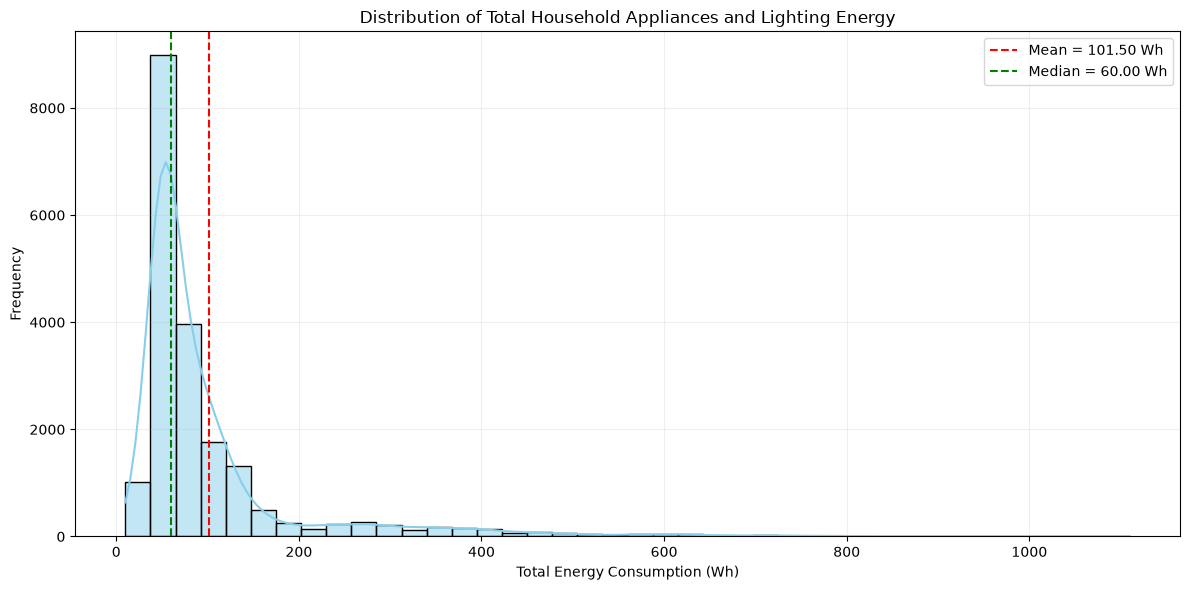

In [12]:


os.makedirs("EDA_graph", exist_ok=True)

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Total_Energy",
    bins=40,
    kde=True,
    color="skyblue",
    edgecolor="black"
)

plt.axvline(
    mean_energy,
    color="red",
    linestyle="--",
    label=f"Mean = {mean_energy:.2f} Wh"
)

plt.axvline(
    median_energy,
    color="green",
    linestyle="--",
    label=f"Median = {median_energy:.2f} Wh"
)

plt.title("Distribution of Total Household Appliances and Lighting Energy")
plt.xlabel("Total Energy Consumption (Wh)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.2)

plt.tight_layout()

plt.savefig(
    "../EDA_graph/total_energy_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Calculate skewness mathematically

In [13]:
skewness = df["Total_Energy"].skew()

print("Skewness:", skewness)

Skewness: 3.302997576032951


how many observations are below 100 Wh

In [14]:
# Count observations at or below 100 Wh
low_energy_count = (df["Appliances"] <= 100).sum()

# Calculate percentage
low_energy_percentage = (
    low_energy_count / len(df)
) * 100

print("Observations <= 100 Wh:", low_energy_count)
print("Percentage:", low_energy_percentage)

Observations <= 100 Wh: 15502
Percentage: 78.55079807448695


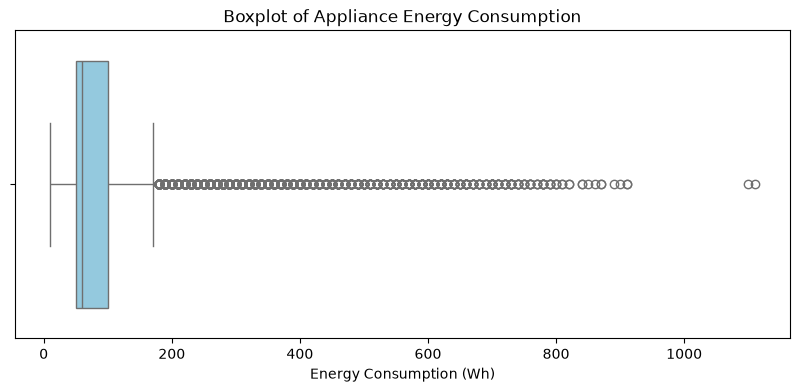

In [15]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["Total_Energy"],
    color="skyblue"
)

plt.title("Boxplot of Appliance Energy Consumption")
plt.xlabel("Energy Consumption (Wh)")
plt.show()

In [16]:
Q1 = df["Total_Energy"].quantile(0.25)
Q3 = df["Total_Energy"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 50.0
Q3: 100.0
IQR: 50.0
Lower Bound: -25.0
Upper Bound: 175.0


In [17]:
# Identify potential outliers
outlier_mask = (
    (df["Total_Energy"] < lower_bound) |
    (df["Total_Energy"] > upper_bound)
)

# Count them
outlier_count = outlier_mask.sum()

# Calculate percentage
outlier_percentage = (outlier_count / len(df)) * 100

print("Outlier Count:", outlier_count)
print("Outlier Percentage:", outlier_percentage)

Outlier Count: 2210
Outlier Percentage: 11.198378515328097


In [18]:
# Physical validity check
negative_energy = (df["Total_Energy"] < 0).sum()

# Statistical lower outliers
lower_outliers = (df["Total_Energy"] < lower_bound).sum()

# Statistical upper outliers
upper_outliers = (df["Total_Energy"] > upper_bound).sum()

print("Negative energy values:", negative_energy)
print("Lower outliers:", lower_outliers)
print("Upper outliers:", upper_outliers)

Negative energy values: 0
Lower outliers: 0
Upper outliers: 2210


Is lighting consumption low during high appliance consumption?

In [19]:
# Flag high appliance energy
df["High_Appliances"] = df["Appliances"] > 175

# Compare lighting consumption by group
lighting_analysis = df.groupby("High_Appliances")["lights"].agg(
    count="count",
    mean="mean",
    median="median",
    std="std",
    zero_percentage=lambda x: (x == 0).mean() * 100
)

display(lighting_analysis.round(2))

,count,mean,median,std,zero_percentage
High_Appliances,,,,,
False,17597,3.43,0.0,7.53,79.30
True,2138,6.89,0.0,10.21,60.66


In [20]:
# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

# Extract hour
df["hour"] = df["date"].dt.hour

display(df[["date", "hour", "Total_Energy"]].head())

,date,hour,Total_Energy
0,2016-01-11 17:00:00,17,90
1,2016-01-11 17:10:00,17,90
2,2016-01-11 17:20:00,17,80
3,2016-01-11 17:30:00,17,90
4,2016-01-11 17:40:00,17,100


In [21]:
df["High_Energy"] = df["Appliances"] > 175

In [22]:
hourly_stats = df.groupby("hour").agg(
    total=("Total_Energy", "size"),
    high_count=("High_Energy", "sum")
)

hourly_stats["high_percentage"] = (
    hourly_stats["high_count"] /
    hourly_stats["total"]
) * 100

display(hourly_stats)

,total,high_count,high_percentage
hour,,,
0,822,5,0.608273
1,822,2,0.243309
2,822,0,0.000000
3,822,0,0.000000
4,822,0,0.000000
5,822,7,0.851582
6,822,16,1.946472
7,822,59,7.177616
8,822,130,15.815085


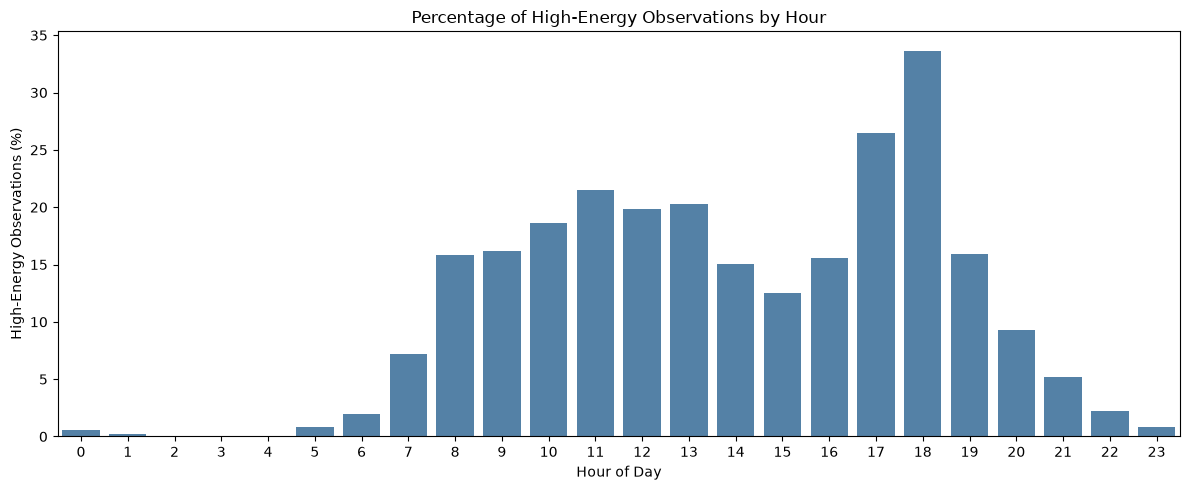

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_stats.index,
    y=hourly_stats["high_percentage"],
    color="steelblue"
)

plt.title("Percentage of High-Energy Observations by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("High-Energy Observations (%)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

Weekend vs Weekday

In [24]:
# Convert date column into datetime
df["date"] = pd.to_datetime(df["date"])

# Extract day name
df["day_name"] = df["date"].dt.day_name()

# Extract day number (Monday = 0, Sunday = 6)
df["day_of_week"] = df["date"].dt.dayofweek

# Identify weekend
df["is_weekend"] = df["day_of_week"] >= 5

# Verify first observations
display(df[["date", "day_name", "day_of_week", "is_weekend"]].head())

C:\Users\Admin\AppData\Local\Temp\ipykernel_10472\705788990.py:8: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["day_of_week"] = df["date"].dt.dayofweek


,date,day_name,day_of_week,is_weekend
0,2016-01-11 17:00:00,Monday,0,False
1,2016-01-11 17:10:00,Monday,0,False
2,2016-01-11 17:20:00,Monday,0,False
3,2016-01-11 17:30:00,Monday,0,False
4,2016-01-11 17:40:00,Monday,0,False


In [25]:
weekend_analysis = df.groupby("is_weekend")["Total_Energy"].agg(
    ["count", "mean", "median", "std"]
)

display(weekend_analysis)

,count,mean,median,std
is_weekend,,,,
False,14263,100.642221,60.0,104.867218
True,5472,103.724415,70.0,103.078458


In [26]:
# Flag high-energy observations during weekends
df["Weekend_High_Energy"] = (
    (df["is_weekend"] == True) &
    (df["Total_Energy"] > 175)
)

# Count flagged observations
print("Weekend High-Energy Count:",
      df["Weekend_High_Energy"].sum())

# Display flagged observations
display(
    df.loc[
        df["Weekend_High_Energy"],
        ["date", "Appliances", "is_weekend"]
    ].head(10)
)

Weekend High-Energy Count: 613


,date,Appliances,is_weekend
662,2016-01-16 07:20:00,220,True
663,2016-01-16 07:30:00,390,True
664,2016-01-16 07:40:00,380,True
665,2016-01-16 07:50:00,390,True
666,2016-01-16 08:00:00,390,True
667,2016-01-16 08:10:00,240,True
711,2016-01-16 15:30:00,370,True
712,2016-01-16 15:40:00,410,True
713,2016-01-16 15:50:00,250,True
722,2016-01-16 17:20:00,380,True


Weekend vs Weekday High-Energy Graph

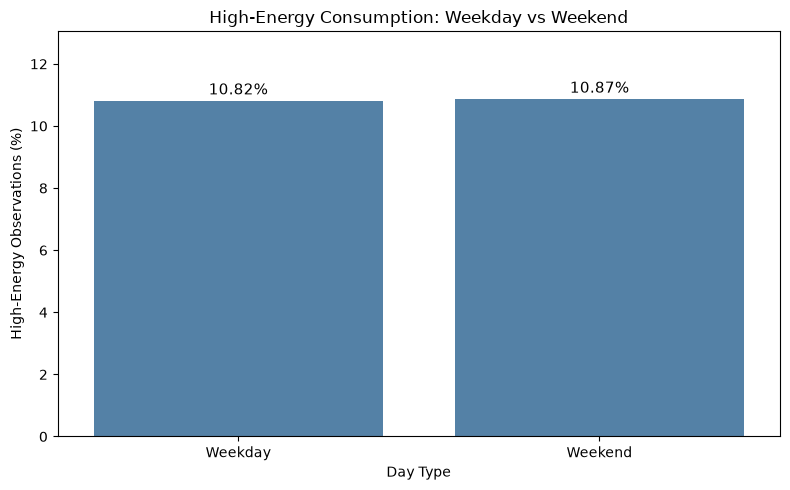

In [27]:
# Create folder
os.makedirs("../EDA_graph", exist_ok=True)

# Calculate percentage of high-energy observations
weekend_high = df.groupby("is_weekend")["High_Energy"].mean() * 100

# Rename groups
weekend_high.index = ["Weekday", "Weekend"]

# Create graph
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=weekend_high.index,
    y=weekend_high.values,
    color="steelblue"
)

# Add percentage labels
for i, value in enumerate(weekend_high.values):
    ax.text(i, value + 0.2, f"{value:.2f}%",
            ha="center", fontsize=11)

plt.title("High-Energy Consumption: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("High-Energy Observations (%)")
plt.ylim(0, max(weekend_high.values) * 1.2)

plt.tight_layout()

# Save graph
plt.savefig(
    "../EDA_graph/weekend_high_energy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [28]:
df["High_Energy"] = df["Appliances"] > 175

Does the hourly energy-consumption pattern differ between weekdays and weekends?

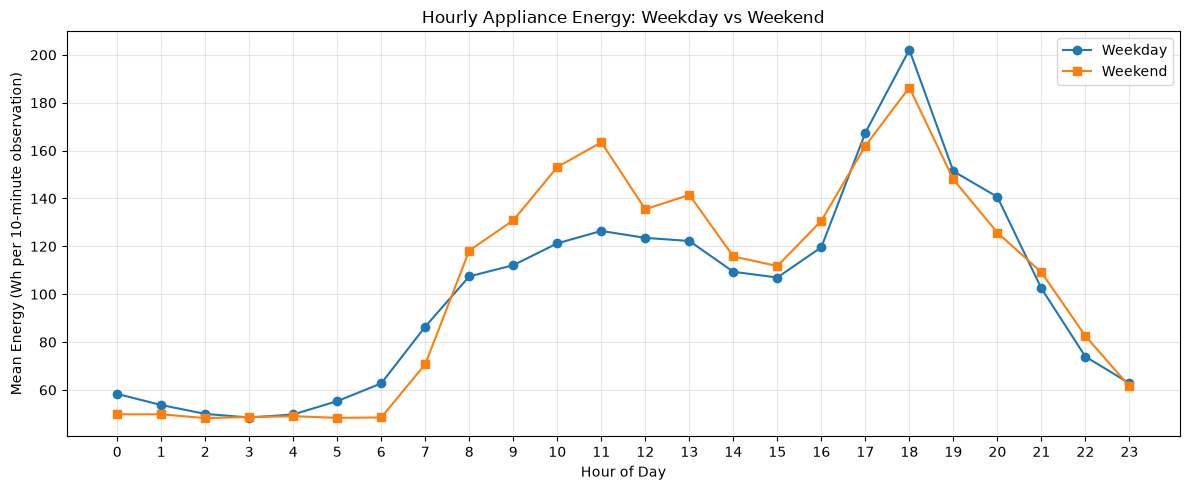

In [29]:
# Calculate mean energy for each hour and day type
hourly_weekend = df.groupby(
    ["hour", "is_weekend"]
)["Total_Energy"].mean().unstack()

# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    hourly_weekend.index,
    hourly_weekend[False],
    marker="o",
    label="Weekday"
)

plt.plot(
    hourly_weekend.index,
    hourly_weekend[True],
    marker="s",
    label="Weekend"
)

plt.title("Hourly Appliance Energy: Weekday vs Weekend")
plt.xlabel("Hour of Day")
plt.ylabel("Mean Energy (Wh per 10-minute observation)")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../EDA_graph/hourly_weekday_weekend.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

Calculate daily energy consumption

In [30]:
# Extract calendar date
df["day"] = df["date"].dt.date

# Group observations by day
daily_energy = df.groupby("day")["Total_Energy"].agg(
    total_Wh="sum",
    observations="count"
)

# Convert Wh to kWh
daily_energy["total_kWh"] = daily_energy["total_Wh"] / 1000

# Display results
display(daily_energy.head(10))

,total_Wh,observations,total_kWh
day,,,
2016-01-11,7000,42,7.00
2016-01-12,12950,144,12.95
2016-01-13,14750,144,14.75
2016-01-14,22520,144,22.52
2016-01-15,18910,144,18.91
2016-01-16,19190,144,19.19
2016-01-17,21260,144,21.26
2016-01-18,14020,144,14.02
2016-01-19,12380,144,12.38


Outlier_Flag
0    17525
1     2210
Name: count, dtype: int64


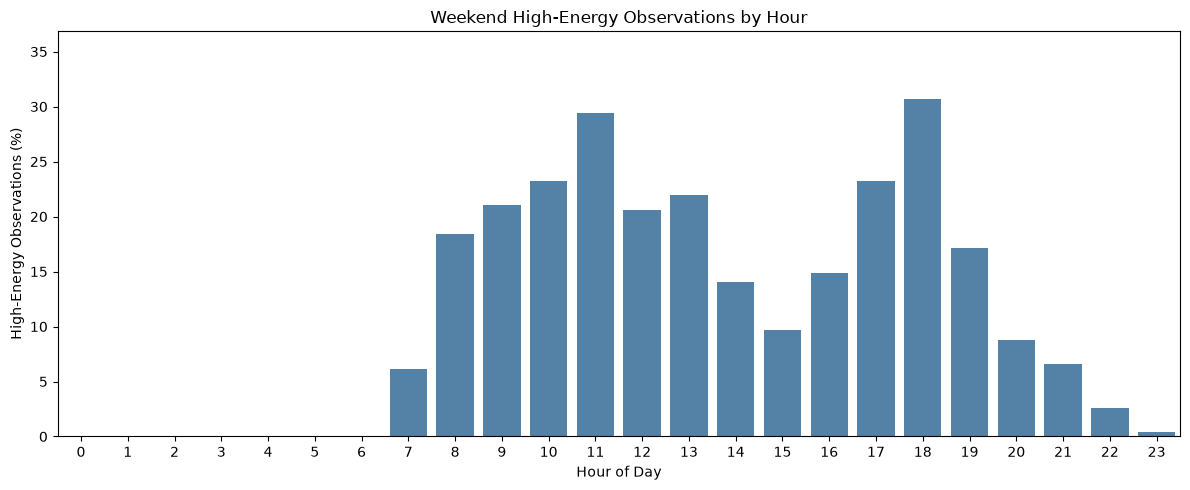

In [31]:
# Create binary target outlier flag
df["Outlier_Flag"] = (df["Total_Energy"] > 175).astype(int)

# Verify flags
print(df["Outlier_Flag"].value_counts())

# Extract only weekend observations
weekend_df = df[df["is_weekend"] == True]

# Calculate hourly high-energy percentage
weekend_hourly = (
    weekend_df.groupby("hour")["Outlier_Flag"]
    .mean() * 100
)

# Plot
plt.figure(figsize=(12, 5))

ax = sns.barplot(
    x=weekend_hourly.index,
    y=weekend_hourly.values,
    color="steelblue"
)

plt.title("Weekend High-Energy Observations by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("High-Energy Observations (%)")
plt.xticks(range(24))
plt.ylim(0, max(weekend_hourly.values) * 1.2)

plt.tight_layout()

# Save in EDA_graph folder
os.makedirs("EDA_graph", exist_ok=True)

plt.savefig(
    "../EDA_graph/weekend_hourly_outlier_percentage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [32]:
# Select weekend observations
weekend_df = df[df["is_weekend"]].copy()

# Group by hour
weekend_hourly = weekend_df.groupby("hour").agg(
    Total_Observations=("Outlier_Flag", "size"),
    Outlier_Count=("Outlier_Flag", "sum")
)

# Percentage within each hour
weekend_hourly["Hourly_Percentage"] = (
    weekend_hourly["Outlier_Count"] /
    weekend_hourly["Total_Observations"]
) * 100

# Cumulative count
weekend_hourly["Cumulative_Count"] = (
    weekend_hourly["Outlier_Count"].cumsum()
)

# Cumulative percentage of weekend outliers
weekend_hourly["Cumulative_Percentage"] = (
    weekend_hourly["Cumulative_Count"] /
    weekend_hourly["Outlier_Count"].sum()
) * 100

display(weekend_hourly.round(2))

,Total_Observations,Outlier_Count,Hourly_Percentage,Cumulative_Count,Cumulative_Percentage
hour,,,,,
0,228,0,0.00,0,0.00
1,228,0,0.00,0,0.00
2,228,0,0.00,0,0.00
3,228,0,0.00,0,0.00
4,228,0,0.00,0,0.00
5,228,0,0.00,0,0.00
6,228,0,0.00,0,0.00
7,228,14,6.14,14,2.28
8,228,42,18.42,56,9.14


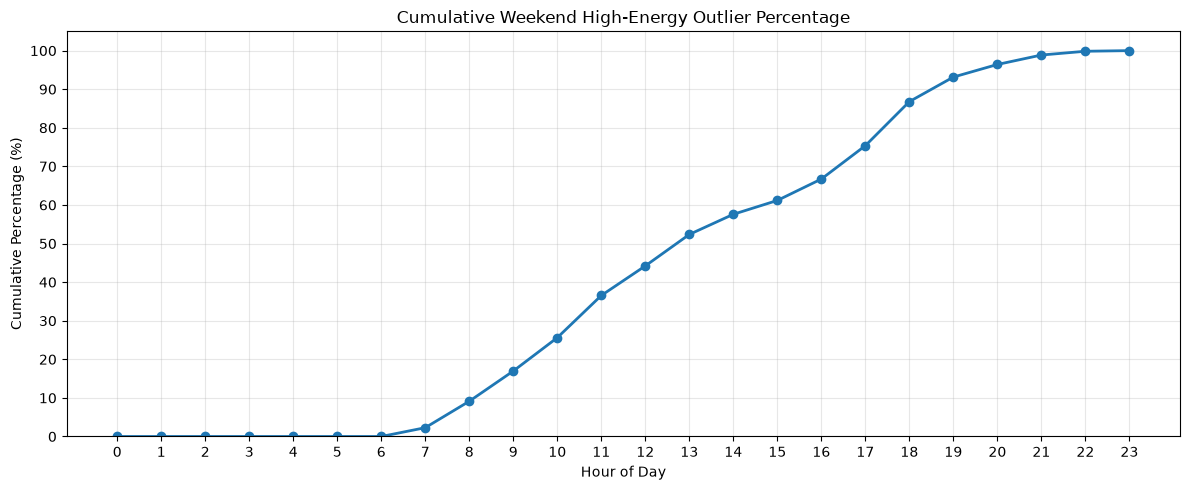

In [33]:


os.makedirs("EDA_graph", exist_ok=True)

plt.figure(figsize=(12, 5))

plt.plot(
    weekend_hourly.index,
    weekend_hourly["Cumulative_Percentage"],
    marker="o",
    linewidth=2
)

plt.title("Cumulative Weekend High-Energy Outlier Percentage")
plt.xlabel("Hour of Day")
plt.ylabel("Cumulative Percentage (%)")

plt.xticks(range(24))
plt.yticks(range(0, 101, 10))
plt.ylim(0, 105)
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../EDA_graph/weekend_cumulative_outliers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [34]:
# Recalculate IQR for Total_Energy
Q1 = df["Total_Energy"].quantile(0.25)
Q3 = df["Total_Energy"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create binary outlier flag
df["Total_Energy_Outlier"] = (
    (df["Total_Energy"] < lower_bound) |
    (df["Total_Energy"] > upper_bound)
).astype(int)

# Extract hour
df["date"] = pd.to_datetime(df["date"])
df["hour"] = df["date"].dt.hour

# Verify results
print(df["Total_Energy_Outlier"].value_counts())

display(
    df[["date", "hour", "Total_Energy", "Total_Energy_Outlier"]].head(10)
)

Total_Energy_Outlier
0    17525
1     2210
Name: count, dtype: int64


,date,hour,Total_Energy,Total_Energy_Outlier
0,2016-01-11 17:00:00,17,90,0
1,2016-01-11 17:10:00,17,90,0
2,2016-01-11 17:20:00,17,80,0
3,2016-01-11 17:30:00,17,90,0
4,2016-01-11 17:40:00,17,100,0
5,2016-01-11 17:50:00,17,90,0
6,2016-01-11 18:00:00,18,110,0
7,2016-01-11 18:10:00,18,110,0
8,2016-01-11 18:20:00,18,100,0
9,2016-01-11 18:30:00,18,110,0


In [35]:
print(df.head())
print(df.info())

                 date  Appliances  lights     T1       RH_1    T2       RH_2  \
0 2016-01-11 17:00:00          60      30  19.89  47.596667  19.2  44.790000   
1 2016-01-11 17:10:00          60      30  19.89  46.693333  19.2  44.722500   
2 2016-01-11 17:20:00          50      30  19.89  46.300000  19.2  44.626667   
3 2016-01-11 17:30:00          50      40  19.89  46.066667  19.2  44.590000   
4 2016-01-11 17:40:00          60      40  19.89  46.333333  19.2  44.530000   

      T3       RH_3         T4  ...  High_Appliances  hour  High_Energy  \
0  19.79  44.730000  19.000000  ...            False    17        False   
1  19.79  44.790000  19.000000  ...            False    17        False   
2  19.79  44.933333  18.926667  ...            False    17        False   
3  19.79  45.000000  18.890000  ...            False    17        False   
4  19.79  45.000000  18.890000  ...            False    17        False   

   day_name  day_of_week  is_weekend  Weekend_High_Energy         da

# our proble base on the time. how to idenfy?
- because are energy consumation change on the house , day - night, one day, one week, one month
- main goal make data frame file for multiple time series

- first will make base one hour make data frame

In [36]:
df_10min = df.copy()

In [37]:
# Copy the complete dataframe
df_10min = df.copy()

# Convert date column
df_10min["date"] = pd.to_datetime(df_10min["date"])

# Set datetime index
df_10min = df_10min.set_index("date").sort_index()

# Energy columns: SUM
energy_cols = ["Appliances", "lights", "Total_Energy"]

# Outlier and boolean flags: MAX
flag_cols = [
    "High_Appliances",
    "High_Energy",
    "Weekend_High_Energy",
    "Outlier_Flag",
    "Total_Energy_Outlier"
]

# Time-derived columns that will be recreated
time_cols = ["hour", "day", "day_name", "day_of_week", "is_weekend"]

# Environmental columns: MEAN
environment_cols = [
    col for col in df_10min.columns
    if col not in energy_cols + flag_cols + time_cols
]

# Aggregation rules
agg_rules = {
    **{col: "sum" for col in energy_cols},
    **{col: "mean" for col in environment_cols},
    **{col: "max" for col in flag_cols}
}

# Aggregate to 1-hour intervals
df_1h = df_10min.resample("1h").agg(agg_rules)

# Count number of 10-minute observations per hour
df_1h["record_count"] = df_10min.resample("1h").size()

# Recreate time features
df_1h["hour"] = df_1h.index.hour
df_1h["day"] = df_1h.index.date
df_1h["day_name"] = df_1h.index.day_name()
df_1h["day_of_week"] = df_1h.index.dayofweek
df_1h["is_weekend"] = df_1h["day_of_week"] >= 5

# Restore date as column
df_1h = df_1h.reset_index()

# Display all columns
pd.set_option("display.max_columns", None)

display(df_1h.head(10))
print("Hourly DataFrame shape:", df_1h.shape)

C:\Users\Admin\AppData\Local\Temp\ipykernel_10472\1323279236.py:48: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  df_1h["day_of_week"] = df_1h.index.dayofweek


,date,Appliances,lights,Total_Energy,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,High_Appliances,High_Energy,Weekend_High_Energy,Outlier_Flag,Total_Energy_Outlier,record_count,hour,day,day_name,day_of_week,is_weekend
0,2016-01-11 17:00:00,330,210,540,19.890000,46.502778,19.200000,44.626528,19.790000,44.897778,18.932778,45.738750,17.166667,55.116667,6.586667,84.260000,17.177778,41.400000,18.150000,48.710556,17.016667,45.446667,6.308333,733.750000,92.000000,6.166667,53.416667,5.050000,26.823044,26.823044,False,False,False,0,0,6,17,2016-01-11,Monday,0,False
1,2016-01-11 18:00:00,1060,310,1370,19.897778,45.879028,19.268889,44.438889,19.770000,44.863333,18.908333,46.066667,17.111111,54.977778,6.180000,87.204444,17.229583,42.046806,18.094444,48.597222,16.981667,45.290000,5.941667,734.266667,91.583333,5.416667,40.000000,4.658333,22.324206,22.324206,True,True,False,1,1,6,18,2016-01-11,Monday,0,False
2,2016-01-11 19:00:00,1040,150,1190,20.495556,52.805556,19.925556,46.061667,20.052222,47.227361,18.969444,47.815556,17.136111,55.869861,5.857361,88.131389,17.850000,45.017778,18.156111,49.213333,16.902222,45.311389,6.000000,734.791667,89.750000,6.000000,40.000000,4.391667,33.734932,33.734932,True,True,False,1,1,6,19,2016-01-11,Monday,0,False
3,2016-01-11 20:00:00,750,210,960,20.961111,48.453333,20.251111,45.632639,20.213889,47.268889,19.190833,49.227917,17.615556,74.027778,5.469444,86.933889,17.632222,42.920000,18.773333,50.195556,16.890000,45.118889,6.000000,735.283333,87.583333,6.000000,40.000000,4.016667,25.679642,25.679642,True,True,False,1,1,6,20,2016-01-11,Monday,0,False
4,2016-01-11 21:00:00,620,140,760,21.311667,45.768333,20.587778,44.961111,20.373333,46.164444,19.425556,47.918889,18.427222,69.037778,5.578889,86.129444,17.863611,43.618333,19.153333,49.542222,16.890000,44.807778,5.833333,735.566667,87.416667,6.000000,40.000000,3.816667,18.826274,18.826274,False,False,False,0,0,6,21,2016-01-11,Monday,0,False
5,2016-01-11 22:00:00,1600,130,1730,21.572222,44.663333,20.905556,44.118889,20.469444,45.829444,20.108889,47.506667,19.112917,53.129306,5.830000,85.256389,17.775000,42.944444,19.342778,49.016667,16.856667,44.527639,5.725000,736.008333,87.583333,6.416667,40.000000,3.741667,27.143708,27.143708,True,True,False,1,1,6,22,2016-01-11,Monday,0,False
6,2016-01-11 23:00:00,340,110,450,21.531667,44.271111,20.934444,43.712500,20.317917,45.695833,20.909722,46.551250,19.275000,50.923333,5.738889,86.438889,17.700000,43.241111,19.384444,50.272222,16.890000,45.241111,5.650000,736.550000,89.083333,6.583333,32.500000,3.925000,29.209795,29.209795,False,False,False,0,0,6,23,2016-01-11,Monday,0,False
7,2016-01-12 00:00:00,850,100,950,21.266111,44.960556,20.637222,44.018333,20.144444,45.542222,20.514444,47.112778,19.155556,50.396111,5.463333,89.107222,17.755000,44.590000,19.396667,51.695556,16.890000,45.875000,5.216667,737.150000,92.000000,6.000000,29.500000,4.016667,26.296718,26.296718,True,True,False,1,1,6,0,2016-01-12,Tuesday,1,False
8,2016-01-12 01:00:00,1010,50,1060,20.963611,45.613194,20.333333,44.273333,20.133333,45.540000,21.505556,46.946667,18.969444,50.076111,4.810000,91.045000,17.790000,45.728611,19.280000,53.247778,16.890000,46.307778,5.141667,737.833333,92.000000,5.583333,40.000000,3.941667,28.723073,28.723073,True,True,False,1,1,6,1,2016-01-12,Tuesday,1,False
9,2016-01-12 02:00:00,270,0,270,20.696667,46.197778,20.066667,44.503333,20.170833,45.454167,21.143056,45.905556,18.813333,50.122083,4.250556,92.690000,17.845556,46.018889,19.192639,54.868194,16.975556,47.263333,5.033333,738.550000,92.000000,4.583333,40.000000,3.833333,17.282387,17.282387,False,False,False,0,0,6,2,2016-01-12,Tuesday,1,False


Hourly DataFrame shape: (3290, 41)


In [38]:
# Copy the 10-minute DataFrame
df_daily = df_10min.copy()

# Ensure datetime index
if "date" in df_daily.columns:
    df_daily["date"] = pd.to_datetime(df_daily["date"])
    df_daily = df_daily.set_index("date")

df_daily = df_daily.sort_index()

# Energy columns → SUM
energy_cols = ["Appliances", "lights", "Total_Energy"]

# Outlier and event flags → MAX
flag_cols = [
    "High_Appliances",
    "High_Energy",
    "Weekend_High_Energy",
    "Outlier_Flag",
    "Total_Energy_Outlier"
]

# Time columns → Recalculate
time_cols = [
    "hour", "day", "day_name",
    "day_of_week", "is_weekend"
]

# Aggregation rules for ALL columns
agg_rules = {}

for col in df_daily.columns:
    if col in time_cols:
        continue
    elif col in energy_cols:
        agg_rules[col] = "sum"
    elif col in flag_cols:
        agg_rules[col] = "max"
    elif pd.api.types.is_numeric_dtype(df_daily[col]):
        agg_rules[col] = "mean"
    else:
        agg_rules[col] = "first"

# Create 1-day DataFrame
df_1day = df_daily.resample("1D").agg(agg_rules)

# Count observations
df_1day["record_count"] = df_daily.resample("1D").size()

# Recalculate time features
df_1day["hour"] = 0
df_1day["day"] = df_1day.index.date
df_1day["day_name"] = df_1day.index.day_name()
df_1day["day_of_week"] = df_1day.index.day_of_week
df_1day["is_weekend"] = df_1day["day_of_week"] >= 5

# Identify complete days
df_1day["complete_day"] = df_1day["record_count"] == 144

# Restore date column
df_1day = df_1day.reset_index()

# Show all columns
pd.set_option("display.max_columns", None)

display(df_1day.head(10))

print("Original shape:", df_10min.shape)
print("Daily shape:", df_1day.shape)

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Total_Energy,High_Appliances,High_Energy,Weekend_High_Energy,Outlier_Flag,Total_Energy_Outlier,record_count,hour,day,day_name,day_of_week,is_weekend,complete_day
0,2016-01-11,5740,1260,20.808571,46.906210,20.153333,44.793175,20.140972,45.992440,19.492222,47.260813,17.977798,59.011786,5.891607,86.336349,17.604028,43.026925,18.722063,49.363968,16.918175,45.106210,5.922619,735.173810,89.285714,6.083333,40.845238,4.228571,26.248800,26.248800,7000,True,True,False,1,1,42,0,2016-01-11,Monday,0,False,False
1,2016-01-12,12340,610,20.092326,45.142014,19.307655,43.779733,19.993646,44.933171,19.772778,44.556840,18.011939,50.569078,5.350388,89.505330,17.909869,41.944178,18.753033,49.909097,17.032847,45.680127,5.566319,742.628125,87.500000,5.784722,37.229167,3.596528,25.505072,25.505072,12950,True,True,False,1,1,144,0,2016-01-12,Tuesday,1,False,True
2,2016-01-13,13970,780,19.197824,42.867772,18.568513,42.119669,19.609213,43.720891,19.009803,42.315174,17.755966,58.006348,4.979861,75.684838,18.024485,40.436875,18.788722,48.619546,16.953576,44.691476,4.856944,754.790625,83.406250,5.614583,31.559028,2.169792,23.464726,23.464726,14750,True,True,False,1,1,144,0,2016-01-13,Wednesday,2,False,True
3,2016-01-14,21800,720,20.372078,42.435191,19.743131,40.699172,20.837581,43.399740,18.694271,43.231053,17.610995,58.117014,3.492367,86.199664,17.946759,40.125689,18.769959,47.299497,16.884815,45.428229,3.431944,749.767361,86.420139,6.277778,35.149306,1.316667,25.264569,25.264569,22520,True,True,False,1,1,144,0,2016-01-14,Thursday,3,False,True
4,2016-01-15,18050,860,22.280949,39.099294,21.528172,38.193897,20.959074,41.409884,19.615127,41.961036,19.026125,52.490274,2.662419,88.423698,18.247612,39.424901,19.225237,46.037401,17.345694,44.534329,2.665278,754.579861,88.385417,7.770833,40.208333,0.849653,26.289515,26.289515,18910,True,True,False,1,1,144,0,2016-01-15,Friday,4,False,True
5,2016-01-16,18040,1150,22.119063,39.925671,21.235583,39.083364,21.022170,42.027425,20.533663,41.797853,19.454545,53.138712,1.722344,95.611869,19.347296,40.131796,20.334724,46.781565,17.896308,44.383391,2.194097,763.452778,89.649306,3.482639,35.486111,0.539931,24.912713,24.912713,19190,True,True,True,1,1,144,0,2016-01-16,Saturday,5,True,True
6,2016-01-17,20550,710,21.755984,39.448860,20.616855,38.153186,21.275428,40.717731,21.016771,39.240729,18.596029,55.243064,-0.604653,94.713960,20.108433,36.828408,21.320608,44.496611,17.910133,41.414670,0.392708,764.744444,83.868056,2.208333,33.920139,-2.218403,24.431695,24.431695,21260,True,True,True,1,1,144,0,2016-01-17,Sunday,6,True,True
7,2016-01-18,13530,490,20.086852,40.861522,18.695812,40.927661,20.001400,40.861846,19.539740,38.199196,18.075195,61.323788,-3.230576,89.639279,19.157629,35.551679,20.277375,44.179900,17.288241,39.009219,-2.937847,758.843403,82.225694,2.357639,30.069444,-5.645139,24.603728,24.603728,14020,True,True,False,1,1,144,0,2016-01-18,Monday,0,False,True
8,2016-01-19,11990,390,19.264641,39.716898,17.980556,39.999439,19.395249,40.027286,18.521933,37.666059,16.991715,58.130162,-4.249048,86.084550,17.930624,32.616767,19.659849,42.432220,16.689560,38.970359,-2.929167,757.250694,83.704861,1.000000,49.538194,-5.480208,23.631839,23.631839,12380,True,True,False,1,1,144,0,2016-01-19,Tuesday,1,False,True
9,2016-01-20,16480,840,18.549022,38.249832,17.512899,38.211933,18.618791,38.708663,17.352060,37.247187,16.898308,54.532190,-1.281927,92.756978,16.589257,31.757395,19.570555,42.656523,15.968339,38.789126,-1.621875,760.064583,88.354167,2.017361,58.600694,-3.325000,24.437389,24.437389,17320,True,True,False,1,1,144,0,2016-01-20,Wednesday,2,False,True


Original shape: (19735, 39)
Daily shape: (138, 42)


In [39]:
# Copy original 10-minute dataframe
df_weekly = df_10min.copy()

# Ensure datetime index
if "date" in df_weekly.columns:
    df_weekly["date"] = pd.to_datetime(df_weekly["date"])
    df_weekly = df_weekly.set_index("date")

df_weekly = df_weekly.sort_index()

# Energy columns -> SUM
energy_cols = ["Appliances", "lights", "Total_Energy"]

# Flag columns -> MAX
flag_cols = [
    "High_Appliances",
    "High_Energy",
    "Weekend_High_Energy",
    "Outlier_Flag",
    "Total_Energy_Outlier"
]

# Time columns -> Recalculate
time_cols = [
    "hour", "day", "day_name",
    "day_of_week", "is_weekend",
    "week", "month", "year"
]

# Aggregation rules for ALL columns
agg_rules = {}

for col in df_weekly.columns:

    if col in time_cols:
        continue

    elif col in energy_cols:
        agg_rules[col] = "sum"

    elif (
        col in flag_cols
        or col.endswith("_Outlier")
        or col.endswith("_Flag")
    ):
        agg_rules[col] = "max"

    elif pd.api.types.is_numeric_dtype(df_weekly[col]):
        agg_rules[col] = "mean"

    else:
        agg_rules[col] = "first"

# Create weekly dataframe (Monday-Sunday)
df_1week = df_weekly.resample("W-SUN").agg(agg_rules)

# Count records in each week
df_1week["record_count"] = df_weekly.resample("W-SUN").size()

# Complete week = 7 × 24 × 6 = 1008 records
df_1week["complete_week"] = df_1week["record_count"] == 1008

# Recreate time features
df_1week["week"] = df_1week.index.isocalendar().week.astype(int)
df_1week["month"] = df_1week.index.month
df_1week["year"] = df_1week.index.year
df_1week["day"] = df_1week.index.date
df_1week["day_name"] = df_1week.index.day_name()
df_1week["day_of_week"] = df_1week.index.day_of_week
df_1week["is_weekend"] = df_1week.index.day_of_week >= 5
df_1week["hour"] = df_1week.index.hour

# Restore date column
df_1week = df_1week.reset_index()

# Show all columns
pd.set_option("display.max_columns", None)

display(df_1week.head(10))

print("Weekly DataFrame Shape:", df_1week.shape)

print("\nComplete vs Incomplete Weeks:")
print(df_1week["complete_week"].value_counts())

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Total_Energy,High_Appliances,High_Energy,Weekend_High_Energy,Outlier_Flag,Total_Energy_Outlier,record_count,complete_week,week,month,year,day,day_name,day_of_week,is_weekend,hour
0,2016-01-17,110490,6090,20.962234,41.737713,20.166034,40.544694,20.594156,42.854035,19.760685,42.419140,18.389265,54.798876,3.070905,88.262908,18.551358,39.964191,19.494498,47.291371,17.317803,44.390178,3.311479,754.075055,86.665563,5.231236,35.835541,1.190066,25.036957,25.036957,116580,True,True,True,1,1,906,False,2,1,2016,2016-01-17,Sunday,6,True,0
1,2016-01-24,96960,4540,18.970265,40.441365,17.974727,40.214326,18.917096,40.790425,17.456529,39.969101,16.820185,53.708987,0.831882,93.969017,16.847105,35.171123,18.977896,44.869436,16.048824,41.253069,1.004762,762.671875,87.510417,2.833333,44.312004,-0.939633,24.596125,24.596125,101500,True,True,True,1,1,1008,True,3,1,2016,2016-01-24,Sunday,6,True,0
2,2016-01-31,76060,3170,20.005942,44.619035,19.273765,44.096729,20.190810,44.414958,18.371305,45.722824,17.579043,53.924227,7.697507,93.897689,17.506104,42.451083,18.564247,49.441613,16.778068,47.663142,7.987847,759.602431,85.652282,6.366071,38.823909,5.627232,24.398854,24.398854,79230,True,True,True,1,1,1008,True,4,1,2016,2016-01-31,Sunday,6,True,0
3,2016-02-07,99680,8320,21.899081,45.254812,21.202797,43.658324,22.204695,44.857060,20.193363,45.767525,19.363306,59.850094,8.164529,87.134010,18.682540,41.599908,21.020277,50.563748,18.437951,48.228296,8.118750,756.964881,85.206845,6.167163,38.941468,5.661359,24.978941,24.978941,108000,True,True,True,1,1,1008,True,5,2,2016,2016-02-07,Sunday,6,True,0
4,2016-02-14,114070,6180,21.302147,41.967263,20.262200,40.922187,21.618146,41.632917,19.701390,41.398220,19.096061,56.216249,4.398293,87.964482,19.467948,37.500229,22.269478,45.797866,18.662627,42.753549,4.141319,740.906647,88.877480,5.039683,39.943948,2.363095,25.232881,25.232881,120250,True,True,True,1,1,1008,True,6,2,2016,2016-02-14,Sunday,6,True,0
5,2016-02-21,96470,6050,20.710680,38.556534,19.124841,38.867243,20.856470,38.653882,19.335080,38.142178,18.044963,49.620350,3.606054,78.508496,18.629957,33.004104,20.943382,41.690927,17.911025,40.882103,3.704762,759.311161,84.805060,4.664683,40.343254,1.245734,25.840731,25.840731,102520,True,True,True,1,1,1008,True,7,2,2016,2016-02-21,Sunday,6,True,0
6,2016-02-28,88700,5180,20.858445,39.199510,19.301477,39.520449,21.060442,38.861889,20.423914,37.229783,18.460406,53.192886,3.772250,70.347468,19.304841,35.177279,21.053576,42.091771,18.195554,40.721177,3.684970,755.085565,79.818948,3.552083,36.321429,0.222371,25.652853,25.652853,93880,True,True,True,1,1,1008,True,8,2,2016,2016-02-28,Sunday,6,True,0
7,2016-03-06,98030,4630,20.541072,37.455738,18.769166,38.180866,20.705141,37.322472,19.470372,35.896685,18.193824,49.819484,3.571767,70.619919,18.929556,31.309888,21.063118,40.454812,18.220072,39.399786,3.449355,748.789187,85.402778,4.624504,38.742560,1.022321,24.742969,24.742969,102660,True,True,True,1,1,1008,True,9,3,2016,2016-03-06,Sunday,6,True,0
8,2016-03-13,91400,4330,20.450469,37.097774,18.287926,38.707424,20.372729,36.870123,19.908097,34.820512,18.004459,48.999429,4.143903,57.640491,19.400754,31.622979,21.368137,39.235207,18.104583,38.888595,3.925050,758.726538,78.708333,2.975198,39.947917,0.242014,24.857132,24.857132,95730,True,True,True,1,1,1008,True,10,3,2016,2016-03-13,Sunday,6,True,0
9,2016-03-20,114490,4180,21.510162,36.519545,19.109516,38.745202,21.754926,36.055317,20.686768,34.017439,18.747333,47.440559,5.165104,45.753060,20.314317,28.493818,22.473910,37.442077,19.586277,37.905205,4.660169,764.304464,77.952877,3.634425,40.651290,0.878571,24.675973,24.675973,118670,True,True,True,1,1,1008,True,11,3,2016,2016-03-20,Sunday,6,True,0


Weekly DataFrame Shape: (20, 45)

Complete vs Incomplete Weeks:
complete_week
True     18
False     2
Name: count, dtype: int64


In [40]:
# Copy original 10-minute dataframe
df_monthly = df_10min.copy()

# Ensure datetime index
if "date" in df_monthly.columns:
    df_monthly["date"] = pd.to_datetime(df_monthly["date"])
    df_monthly = df_monthly.set_index("date")

df_monthly = df_monthly.sort_index()

# Energy columns -> SUM
energy_cols = ["Appliances", "lights", "Total_Energy"]

# Flag columns -> MAX
flag_cols = [
    "High_Appliances",
    "High_Energy",
    "Weekend_High_Energy",
    "Outlier_Flag",
    "Total_Energy_Outlier"
]

# Time features -> Recalculate
time_cols = [
    "hour", "day", "day_name", "day_of_week",
    "is_weekend", "week", "month", "year"
]

# Define aggregation rules for all columns
agg_rules = {}

for col in df_monthly.columns:

    if col in time_cols:
        continue

    elif col in energy_cols:
        agg_rules[col] = "sum"

    elif (
        col in flag_cols
        or col.endswith("_Outlier")
        or col.endswith("_Flag")
    ):
        agg_rules[col] = "max"

    elif pd.api.types.is_numeric_dtype(df_monthly[col]):
        agg_rules[col] = "mean"

    else:
        agg_rules[col] = "first"

# Create monthly dataframe
df_1month = df_monthly.resample("MS").agg(agg_rules)

# Count observations per month
df_1month["record_count"] = df_monthly.resample("MS").size()

# Calculate expected observations per month
df_1month["expected_count"] = (
    df_1month.index.days_in_month * 24 * 6
)

# Identify complete months
df_1month["complete_month"] = (
    df_1month["record_count"] == df_1month["expected_count"]
)

# Recreate month and year columns
df_1month["month"] = df_1month.index.month
df_1month["year"] = df_1month.index.year
df_1month["month_name"] = df_1month.index.month_name()

# Restore date column
df_1month = df_1month.reset_index()

# Display all columns
pd.set_option("display.max_columns", None)

display(df_1month)

print("Monthly DataFrame Shape:", df_1month.shape)

print("\nComplete vs Incomplete Months:")
print(df_1month["complete_month"].value_counts())

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Total_Energy,High_Appliances,High_Energy,Weekend_High_Energy,Outlier_Flag,Total_Energy_Outlier,record_count,expected_count,complete_month,month,year,month_name
0,2016-01-01,283510,13800,19.945175,42.284480,19.102295,41.656070,19.876480,42.680624,18.486529,42.713621,17.568479,54.121171,3.894547,92.175166,17.602863,39.168631,18.995378,47.197645,16.693852,44.437044,4.128936,758.947467,86.607461,4.795517,39.790554,1.986071,24.664758,24.664758,297310,True,True,True,1,1,2922,4464,False,1,2016,January
1,2016-02-01,421550,26490,21.163817,41.010174,19.924704,40.538365,21.417500,40.813789,19.894403,40.366176,18.701869,54.657093,4.880271,79.961223,19.074396,36.558300,21.328102,44.755538,18.300514,43.012997,4.817301,753.387033,84.230125,4.847821,38.762332,2.193894,25.465301,25.465301,448040,True,True,True,1,1,4176,4176,True,2,2016,February
2,2016-03-01,432800,17480,21.259760,37.923927,19.141096,39.688162,21.534074,37.242069,20.277842,36.322600,18.891673,48.748197,5.856132,54.873425,19.865841,32.223961,22.127827,40.130809,19.102725,39.310958,5.439415,755.840916,80.734991,3.992832,40.116599,2.135540,24.823175,24.823175,450280,True,True,True,1,1,4464,4464,True,3,2016,March
3,2016-04-01,427200,10440,21.856511,39.722240,20.224405,40.686375,23.018526,37.767839,21.381889,37.613754,20.228250,48.720831,9.276930,34.089611,21.011103,33.554228,22.619655,40.725753,20.292047,39.910451,8.513449,754.606319,77.209954,3.652431,36.322338,4.387639,25.057480,25.057480,437640,True,True,True,1,1,4320,4320,True,4,2016,April
4,2016-05-01,362950,6820,23.877728,41.219759,23.253625,39.905697,25.010280,38.903170,23.771948,39.497038,22.189891,49.573856,15.090683,21.342920,23.211012,36.975319,24.313066,43.461043,22.427778,42.219581,13.762717,755.898430,71.402673,3.079419,36.939138,7.984661,24.829057,24.829057,369770,True,True,True,1,1,3853,4464,False,5,2016,May


Monthly DataFrame Shape: (5, 41)

Complete vs Incomplete Months:
complete_month
True     3
False    2
Name: count, dtype: int64


In [41]:
# Select numerical columns (exclude flags and time features) for 10 min data frame
exclude_cols = [
    "hour", "day_of_week", "record_count",
    "High_Appliances", "High_Energy",
    "Weekend_High_Energy", "Outlier_Flag",
    "Total_Energy_Outlier", "is_weekend"
]

numeric_df_10_min = df.select_dtypes(include="number").drop(
    columns=exclude_cols, errors="ignore"
)

# Calculate descriptive statistics
stats_df_10_min = pd.DataFrame({
    "Min": numeric_df_10_min.min(),
    "Max": numeric_df_10_min.max(),
    "Range": numeric_df_10_min.max() - numeric_df_10_min.min(),
    "Mean": numeric_df_10_min.mean(),
    "Median": numeric_df_10_min.median(),
    "Variance": numeric_df_10_min.var(),
    "Std": numeric_df_10_min.std()
})

# Round values and display all rows
display(stats_df_10_min.round(2))

,Min,Max,Range,Mean,Median,Variance,Std
Appliances,10.00,1080.00,1070.00,97.69,60.00,10511.35,102.52
lights,0.00,70.00,70.00,3.80,0.00,62.98,7.94
T1,16.79,26.26,9.47,21.69,21.60,2.58,1.61
RH_1,27.02,63.36,36.34,40.26,39.66,15.83,3.98
T2,16.10,29.86,13.76,20.34,20.00,4.81,2.19
RH_2,20.46,56.03,35.56,40.42,40.50,16.56,4.07
T3,17.20,29.24,12.04,22.27,22.10,4.02,2.01
RH_3,28.77,50.16,21.40,39.24,38.53,10.59,3.25
T4,15.10,26.20,11.10,20.86,20.67,4.17,2.04
RH_4,27.66,51.09,23.43,39.03,38.40,18.85,4.34


In [42]:
# Select numerical columns (exclude flags and time features)
exclude_cols = [
    "hour", "day_of_week", "record_count",
    "High_Appliances", "High_Energy",
    "Weekend_High_Energy", "Outlier_Flag",
    "Total_Energy_Outlier", "is_weekend"
]

numeric_df_1h = df_1h.select_dtypes(include="number").drop(
    columns=exclude_cols, errors="ignore"
)

# Calculate descriptive statistics
stats_df_1h = pd.DataFrame({
    "Min": numeric_df_1h.min(),
    "Max": numeric_df_1h.max(),
    "Range": numeric_df_1h.max() - numeric_df_1h.min(),
    "Mean": numeric_df_1h.mean(),
    "Median": numeric_df_1h.median(),
    "Variance": numeric_df_1h.var(),
    "Std": numeric_df_1h.std()
})

# Round values and display all rows
display(stats_df_1h.round(2))

,Min,Max,Range,Mean,Median,Variance,Std
Appliances,170.00,3650.00,3480.00,586.02,380.00,236242.88,486.05
lights,0.00,310.00,310.00,22.81,0.00,1713.90,41.40
Total_Energy,170.00,3740.00,3570.00,608.83,400.00,248476.46,498.47
T1,16.79,26.20,9.41,21.69,21.60,2.58,1.61
RH_1,27.51,53.98,26.47,40.26,39.66,15.54,3.94
T2,16.10,29.73,13.63,20.34,20.00,4.79,2.19
RH_2,21.01,53.91,32.90,40.42,40.50,16.43,4.05
T3,17.24,28.98,11.73,22.27,22.10,4.02,2.01
RH_3,29.70,49.47,19.77,39.24,38.54,10.53,3.24
T4,15.10,26.14,11.04,20.86,20.65,4.17,2.04


In [43]:
# Select common numerical measurement columns
exclude_cols = [
    "hour", "day_of_week", "record_count",
    "High_Appliances", "High_Energy",
    "Weekend_High_Energy", "Outlier_Flag",
    "Total_Energy_Outlier", "is_weekend"
]

common_cols = [
    col for col in df_10min.select_dtypes(include="number").columns
    if col in df_1h.columns and col not in exclude_cols
]

# Function to calculate descriptive statistics
def calculate_stats(data):
    return pd.DataFrame({
        "Min": data.min(),
        "Max": data.max(),
        "Range": data.max() - data.min(),
        "Mean": data.mean(),
        "Median": data.median(),
        "Variance": data.var(),
        "Std": data.std()
    })

# Calculate statistics for both time intervals
stats_10min = calculate_stats(df_10min[common_cols])
stats_1h = calculate_stats(df_1h[common_cols])

# Combine statistics side by side
comparison_df = pd.concat(
    [stats_10min, stats_1h],
    axis=1,
    keys=["10 Minutes", "1 Hour"]
)

# Display comparison
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

display(comparison_df.round(2))

10 Minutes                                                      \
                    Min      Max    Range    Mean  Median  Variance     Std   
Appliances        10.00  1080.00  1070.00   97.69   60.00  10511.35  102.52   
lights             0.00    70.00    70.00    3.80    0.00     62.98    7.94   
T1                16.79    26.26     9.47   21.69   21.60      2.58    1.61   
RH_1              27.02    63.36    36.34   40.26   39.66     15.83    3.98   
T2                16.10    29.86    13.76   20.34   20.00      4.81    2.19   
RH_2              20.46    56.03    35.56   40.42   40.50     16.56    4.07   
T3                17.20    29.24    12.04   22.27   22.10      4.02    2.01   
RH_3              28.77    50.16    21.40   39.24   38.53     10.59    3.25   
T4                15.10    26.20    11.10   20.86   20.67      4.17    2.04   
RH_4              27.66    51.09    23.43   39.03   38.40     18.85    4.34   
T5                15.33    25.80    10.47   19.59   19.39      3.40    1.84   
RH_5              29.82    96.32    66.51   50.95   49.09     81.40    9.02   
T6                -6.06    28.29    34.35    7.91    7.30     37.09    6.09   
RH_6               1.00    99.90    98.90   54.61   55.29    970.31   31.15   
T7                15.39    26.00    10.61   20.27   20.03      4.45    2.11   
RH_7              23.20    51.40    28.20   35.39   34.86     26.16    5.11   
T8                16.31    27.23    10.92   22.03   22.10      3.83    1.96   
RH_8              29.60    58.78    29.18   42.94   42.38     27.29    5.22   
T9                14.89    24.50     9.61   19.49   19.39      4.06    2.01   
RH_9              29.17    53.33    24.16   41.55   40.90     17.23    4.15   
T_out             -5.00    26.10    31.10    7.41    6.92     28.27    5.32   
Press_mm_hg      729.30   772.30    43.00  755.52  756.10     54.75    7.40   
RH_out            24.00   100.00    76.00   79.75   83.67    222.04   14.90   
Windspeed          0.00    14.00    14.00    4.04    3.67      6.01    2.45   
Visibility         1.00    66.00    65.00   38.33   40.00    139.12   11.79   
Tdewpoint         -6.60    15.50    22.10    3.76    3.43     17.60    4.19   
rv1                0.01    50.00    49.99   24.99   24.90    210.15   14.50   
rv2                0.01    50.00    49.99   24.99   24.90    210.15   14.50   
Total_Energy      10.00  1110.00  1100.00  101.50   60.00  10895.36  104.38   

              1 Hour                                                       
                 Min      Max    Range    Mean  Median   Variance     Std  
Appliances    170.00  3650.00  3480.00  586.02  380.00  236242.88  486.05  
lights          0.00   310.00   310.00   22.81    0.00    1713.90   41.40  
T1             16.79    26.20     9.41   21.69   21.60       2.58    1.61  
RH_1           27.51    53.98    26.47   40.26   39.66      15.54    3.94  
T2             16.10    29.73    13.63   20.34   20.00       4.79    2.19  
RH_2           21.01    53.91    32.90   40.42   40.50      16.43    4.05  
T3             17.24    28.98    11.73   22.27   22.10       4.02    2.01  
RH_3           29.70    49.47    19.77   39.24   38.54      10.53    3.24  
T4             15.10    26.14    11.04   20.86   20.65       4.17    2.04  
RH_4           28.72    50.75    22.03   39.03   38.41      18.81    4.34  
T5             15.35    25.51    10.16   19.59   19.39       3.39    1.84  
RH_5           30.19    94.88    64.70   50.95   49.22      74.54    8.63  
T6             -5.93    28.14    34.06    7.91    7.29      37.02    6.08  
RH_6            1.00    99.90    98.90   54.60   55.14     967.88   31.11  
T7             15.41    25.93    10.52   20.27   20.04       4.45    2.11  
RH_7           23.34    51.19    27.85   35.39   34.92      26.12    5.11  
T8             16.36    27.19    10.82   22.03   22.14       3.82    1.96  
RH_8           29.74    58.71    28.97   42.94   42.36      27.21    5.22  
T9             14.89    24.50     9.61   19

In [44]:
# Calculate quartiles for hourly energy
Q1 = df_1h["Total_Energy"].quantile(0.25)
Q3 = df_1h["Total_Energy"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag hourly outliers
df_1h["Hourly_Outlier"] = (
    (df_1h["Total_Energy"] < lower_bound) |
    (df_1h["Total_Energy"] > upper_bound)
).astype(int)

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nHourly outlier counts:")
print(df_1h["Hourly_Outlier"].value_counts())

print("\nOutlier percentage:")
print((df_1h["Hourly_Outlier"].mean() * 100).round(2), "%")
outlier_1h = (df_1h["Hourly_Outlier"].mean() * 100).round(2)

Q1: 310.0
Q3: 710.0
IQR: 400.0
Lower Bound: -290.0
Upper Bound: 1310.0

Hourly outlier counts:
Hourly_Outlier
0    2980
1     310
Name: count, dtype: int64

Outlier percentage:
9.42 %


In [45]:
# Select complete days
df_daily_complete = df_1day[
    df_1day["record_count"] == 144
].copy()

# Calculate quartiles
Q1 = df_daily_complete["Total_Energy"].quantile(0.25)
Q3 = df_daily_complete["Total_Energy"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag daily outliers
df_1day["Daily_Outlier"] = 0

mask = (
    (df_1day["Total_Energy"] < lower_bound) |
    (df_1day["Total_Energy"] > upper_bound)
) & (df_1day["record_count"] == 144)

df_1day.loc[mask, "Daily_Outlier"] = 1

# Display results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print("\nDaily Outlier Counts:")
print(
    df_1day.loc[
        df_1day["record_count"] == 144,
        "Daily_Outlier"
    ].value_counts()
)

print("\nDaily Outlier Percentage:")
print(round(
    df_1day.loc[
        df_1day["record_count"] == 144,
        "Daily_Outlier"
    ].mean() * 100, 2
), "%")

# Display daily outlier records
display(
    df_1day.loc[
        df_1day["Daily_Outlier"] == 1,
        ["date", "Total_Energy", "Daily_Outlier"]
    ]
)

Q1: 11552.5
Q3: 16300.0
IQR: 4747.5
Lower Bound: 4431.25
Upper Bound: 23421.25

Daily Outlier Counts:
Daily_Outlier
0    128
1      8
Name: count, dtype: int64

Daily Outlier Percentage:
5.88 %


,date,Total_Energy,Daily_Outlier
21,2016-02-01,24630,1
63,2016-03-14,24270,1
65,2016-03-16,24050,1
74,2016-03-25,26260,1
84,2016-04-04,27690,1
102,2016-04-22,24910,1
123,2016-05-13,24750,1
131,2016-05-21,23500,1


In [46]:
# Select complete weeks
df_weekly_complete = df_1week[
    df_1week["record_count"] == 1008
].copy()

# Calculate quartiles
Q1 = df_weekly_complete["Total_Energy"].quantile(0.25)
Q3 = df_weekly_complete["Total_Energy"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag weekly outliers
df_1week["Weekly_Outlier"] = pd.NA

complete_mask = df_1week["record_count"] == 1008

outlier_mask = (
    (df_1week["Total_Energy"] < lower_bound) |
    (df_1week["Total_Energy"] > upper_bound)
)

df_1week.loc[complete_mask, "Weekly_Outlier"] = (
    outlier_mask.loc[complete_mask].astype(int)
)

# Display statistical results
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Outlier counts
print("\nWeekly Outlier Counts:")
print(
    df_1week.loc[complete_mask, "Weekly_Outlier"]
    .value_counts()
)

# Outlier percentage
print("\nWeekly Outlier Percentage:")
print(
    round(
        df_1week.loc[complete_mask, "Weekly_Outlier"]
        .astype(float).mean() * 100, 2
    ), "%"
)

# Display weekly outliers
display(
    df_1week.loc[
        df_1week["Weekly_Outlier"] == 1,
        ["date", "Total_Energy", "Weekly_Outlier"]
    ]
)

Q1: 95825.0
Q3: 106665.0
IQR: 10840.0
Lower Bound: 79565.0
Upper Bound: 122925.0

Weekly Outlier Counts:
Weekly_Outlier
0    17
1     1
Name: count, dtype: int64

Weekly Outlier Percentage:
5.56 %


,date,Total_Energy,Weekly_Outlier
2,2016-01-31,79230,1


In [47]:
# Select complete months
df_monthly_complete = df_1month[
    df_1month["complete_month"] == True
].copy()

# Calculate quartiles
Q1 = df_monthly_complete["Total_Energy"].quantile(0.25)
Q3 = df_monthly_complete["Total_Energy"].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Initialize monthly outlier flag
df_1month["Monthly_Outlier"] = pd.NA

# Identify complete months
complete_mask = df_1month["complete_month"]

# Detect monthly outliers
outlier_mask = (
    (df_1month["Total_Energy"] < lower_bound) |
    (df_1month["Total_Energy"] > upper_bound)
)

df_1month.loc[complete_mask, "Monthly_Outlier"] = (
    outlier_mask.loc[complete_mask].astype(int)
)

# Display statistics
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

# Display outlier counts
print("\nMonthly Outlier Counts:")
print(df_1month["Monthly_Outlier"].value_counts())

# Display outlier percentage
print("\nMonthly Outlier Percentage:")
print(
    round(
        df_1month["Monthly_Outlier"]
        .dropna()
        .astype(float)
        .mean() * 100, 2
    ), "%"
)

# Display monthly results
display(
    df_1month[
        ["date", "Total_Energy", "record_count",
         "complete_month", "Monthly_Outlier"]
    ]
)

Q1: 442840.0
Q3: 449160.0
IQR: 6320.0
Lower Bound: 433360.0
Upper Bound: 458640.0

Monthly Outlier Counts:
Monthly_Outlier
0    3
Name: count, dtype: int64

Monthly Outlier Percentage:
0.0 %


,date,Total_Energy,record_count,complete_month,Monthly_Outlier
0,2016-01-01,297310,2922,False,<NA>
1,2016-02-01,448040,4176,True,0
2,2016-03-01,450280,4464,True,0
3,2016-04-01,437640,4320,True,0
4,2016-05-01,369770,3853,False,<NA>


In [48]:
# Compare outliers across 5 time intervals
datasets = {
    "10 Minutes": (df_10min, "Outlier_Flag", None),
    "1 Hour": (df_1h, "Hourly_Outlier", 6),
    "1 Day": (df_1day, "Daily_Outlier", 144),
    "1 Week": (df_1week, "Weekly_Outlier", 1008),
    "1 Month": (df_1month, "Monthly_Outlier", None)
}

results = []

for interval, (data, flag, expected) in datasets.items():

    # Select valid observations
    if interval == "1 Month":
        valid = data.loc[data["complete_month"] == True]

    elif expected is not None:
        valid = data.loc[data["record_count"] == expected]

    else:
        valid = data

    # Count outlier flags
    flags = valid[flag].dropna().astype(int)

    total = len(flags)
    outliers = (flags == 1).sum()
    normal = (flags == 0).sum()

    percentage = (
        (outliers / total) * 100 if total > 0 else float("nan")
    )

    results.append({
        "Time Interval": interval,
        "Total Records": total,
        "Normal Records": normal,
        "Outlier Records": outliers,
        "Outlier (%)": round(percentage, 2)
    })

# Create comparison dataframe
outlier_comparison = pd.DataFrame(results)

display(outlier_comparison)

,Time Interval,Total Records,Normal Records,Outlier Records,Outlier (%)
0,10 Minutes,19735,17525,2210,11.20
1,1 Hour,3289,2979,310,9.43
2,1 Day,136,128,8,5.88
3,1 Week,18,17,1,5.56
4,1 Month,3,3,0,0.00


In [49]:
# Select rows where Outlier_Flag = 1
outliers_10min = df_10min[
    df_10min["Outlier_Flag"] == 1
]

# Display first 12 outlier rows with all columns
pd.set_option("display.max_columns", None)

display(outliers_10min.head(12))

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Total_Energy,High_Appliances,hour,High_Energy,day_name,day_of_week,is_weekend,Weekend_High_Energy,day,Outlier_Flag,Total_Energy_Outlier
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2016-01-11 18:40:00,230,70,19.926667,45.863333,19.356667,44.400000,19.790000,44.900000,18.890000,46.430000,17.100000,55.000000,6.190000,87.866667,17.247500,42.717500,18.100000,48.590000,17.000000,45.290000,5.966667,734.366667,91.333333,5.666667,40.0,4.633333,10.298729,10.298729,300,True,18,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 18:50:00,580,60,20.066667,46.396667,19.426667,44.400000,19.790000,44.826667,19.000000,46.430000,17.100000,55.000000,6.123333,87.993333,17.530000,44.263333,18.066667,48.633333,16.890000,45.290000,5.983333,734.433333,91.166667,5.833333,40.0,4.616667,8.827838,8.827838,640,True,18,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 19:00:00,430,50,20.133333,48.000000,19.566667,44.400000,19.890000,44.900000,19.000000,46.363333,17.100000,55.090000,6.123333,88.590000,17.823333,45.493333,18.066667,48.560000,16.963333,45.290000,6.000000,734.500000,91.000000,6.000000,40.0,4.600000,34.351142,34.351142,480,True,19,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 19:10:00,250,40,20.260000,52.726667,19.730000,45.100000,19.890000,45.493333,19.000000,47.223333,17.100000,55.163333,6.067500,88.215000,17.963333,46.160000,18.033333,48.666667,16.890000,45.326667,6.000000,734.616667,90.500000,6.000000,40.0,4.516667,19.205186,19.205186,290,True,19,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 20:10:00,140,40,20.890000,49.800000,20.200000,46.026667,20.166667,47.633333,19.033333,49.500000,17.593333,70.726667,5.333333,87.463333,17.600000,42.693333,18.666667,50.260000,16.890000,45.200000,6.000000,735.233333,87.833333,6.000000,40.0,4.066667,38.872261,38.872261,180,False,20,False,Monday,0,False,False,2016-01-11,1,1
2016-01-11 20:30:00,190,40,20.963333,47.633333,20.260000,45.530000,20.200000,47.026667,19.260000,49.696667,17.666667,79.730000,5.500000,86.956667,17.533333,42.066667,18.856667,50.290000,16.890000,45.126667,6.000000,735.300000,87.500000,6.000000,40.0,4.000000,10.607126,10.607126,230,True,20,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 22:10:00,400,20,21.533333,44.966667,20.790000,44.360000,20.426667,45.933333,19.600000,47.500000,19.033333,54.093333,5.656667,86.226667,17.790000,43.223333,19.356667,49.030000,16.823333,44.530000,5.650000,735.883333,87.833333,6.166667,40.0,3.716667,29.978291,29.978291,420,True,22,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 22:20:00,400,20,21.600000,44.766667,20.890000,44.223333,20.500000,45.933333,19.696667,47.626667,19.100000,53.366667,5.833333,85.766667,17.790000,43.030000,19.390000,48.863333,16.890000,44.590000,5.700000,735.966667,87.666667,6.333333,40.0,3.733333,24.677065,24.677065,420,True,22,True,Monday,0,False,False,2016-01-11,1,1
2016-01-11 22:30:00,390,30,21.600000,44.560000,20.963333,43.963333,20.500000,45.790000,20.096667,47.566667,19.158333,52.472500,5.900000,85.033333,17.790000,42.760000,19.390000,48.863333,16.890000,44.522500,5.750000,736.050000,87.500000,6.500000,40.0,3.750000,9.310880,9.310880,420,True,22,True,Monday,0,False,False,2016-01-11,1,1


In [50]:
# Select numerical columns
numeric_df = df_10min.select_dtypes(include="number")

# Exclude outlier flags and time-derived features
exclude_cols = [
    "hour", "day_of_week", "is_weekend",
    "High_Appliances", "High_Energy",
    "Weekend_High_Energy", "Outlier_Flag",
    "Total_Energy_Outlier"
]

numeric_df = numeric_df.drop(
    columns=exclude_cols,
    errors="ignore"
)

# Calculate Pearson correlation matrix
corr_matrix = numeric_df.corr(method="spearman")

# Display correlation matrix
display(corr_matrix.round(3))

,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Total_Energy
Appliances,1.000,0.302,0.244,0.061,0.305,-0.120,0.217,-0.057,0.207,-0.020,0.186,-0.045,0.242,-0.230,0.182,-0.119,0.236,-0.217,0.167,-0.165,0.216,-0.096,-0.269,0.112,-0.004,0.075,-0.009,-0.009,0.983
lights,0.302,1.000,-0.018,0.110,0.023,0.046,-0.111,0.107,-0.004,0.097,-0.075,0.100,-0.072,0.155,-0.138,0.019,-0.083,-0.004,-0.174,-0.037,-0.073,0.010,0.046,0.054,0.013,-0.044,0.002,0.002,0.434
T1,0.244,-0.018,1.000,0.139,0.843,0.002,0.867,-0.018,0.818,0.114,0.852,-0.039,0.619,-0.602,0.779,0.134,0.805,-0.019,0.788,0.062,0.649,-0.128,-0.296,-0.060,-0.039,0.532,-0.008,-0.008,0.228
RH_1,0.061,0.110,0.139,1.000,0.286,0.800,0.182,0.864,0.063,0.897,0.155,0.473,0.338,0.285,-0.047,0.807,-0.034,0.723,0.045,0.756,0.369,-0.319,0.234,0.209,-0.019,0.631,-0.001,-0.001,0.072
T2,0.305,0.023,0.843,0.286,1.000,-0.088,0.692,0.150,0.707,0.270,0.682,0.037,0.735,-0.502,0.586,0.239,0.572,0.060,0.600,0.165,0.740,-0.149,-0.417,0.130,-0.033,0.551,-0.010,-0.010,0.292
RH_2,-0.120,0.046,0.002,0.800,-0.088,1.000,0.119,0.707,-0.045,0.742,0.108,0.409,0.103,0.364,-0.075,0.710,-0.035,0.688,0.037,0.690,0.146,-0.262,0.484,0.075,-0.018,0.524,0.007,0.007,-0.106
T3,0.217,-0.111,0.867,0.182,0.692,0.119,1.000,-0.042,0.806,0.100,0.876,-0.113,0.653,-0.668,0.810,0.135,0.794,-0.010,0.888,0.099,0.665,-0.191,-0.260,-0.078,-0.067,0.588,-0.006,-0.006,0.189
RH_3,-0.057,0.107,-0.018,0.864,0.150,0.707,-0.042,1.000,-0.152,0.889,-0.061,0.553,0.089,0.528,-0.267,0.825,-0.239,0.806,-0.218,0.807,0.136,-0.277,0.340,0.202,0.011,0.418,0.000,0.000,-0.039
T4,0.207,-0.004,0.818,0.063,0.707,-0.045,0.806,-0.152,1.000,-0.058,0.825,-0.136,0.611,-0.709,0.823,0.016,0.763,-0.132,0.842,-0.050,0.623,-0.048,-0.351,-0.159,-0.080,0.457,-0.004,-0.004,0.200
RH_4,-0.020,0.097,0.114,0.897,0.270,0.742,0.100,0.889,-0.058,1.000,0.088,0.514,0.285,0.402,-0.156,0.884,-0.111,0.817,-0.065,0.825,0.320,-0.312,0.315,0.257,-0.009,0.627,-0.002,-0.002,-0.005


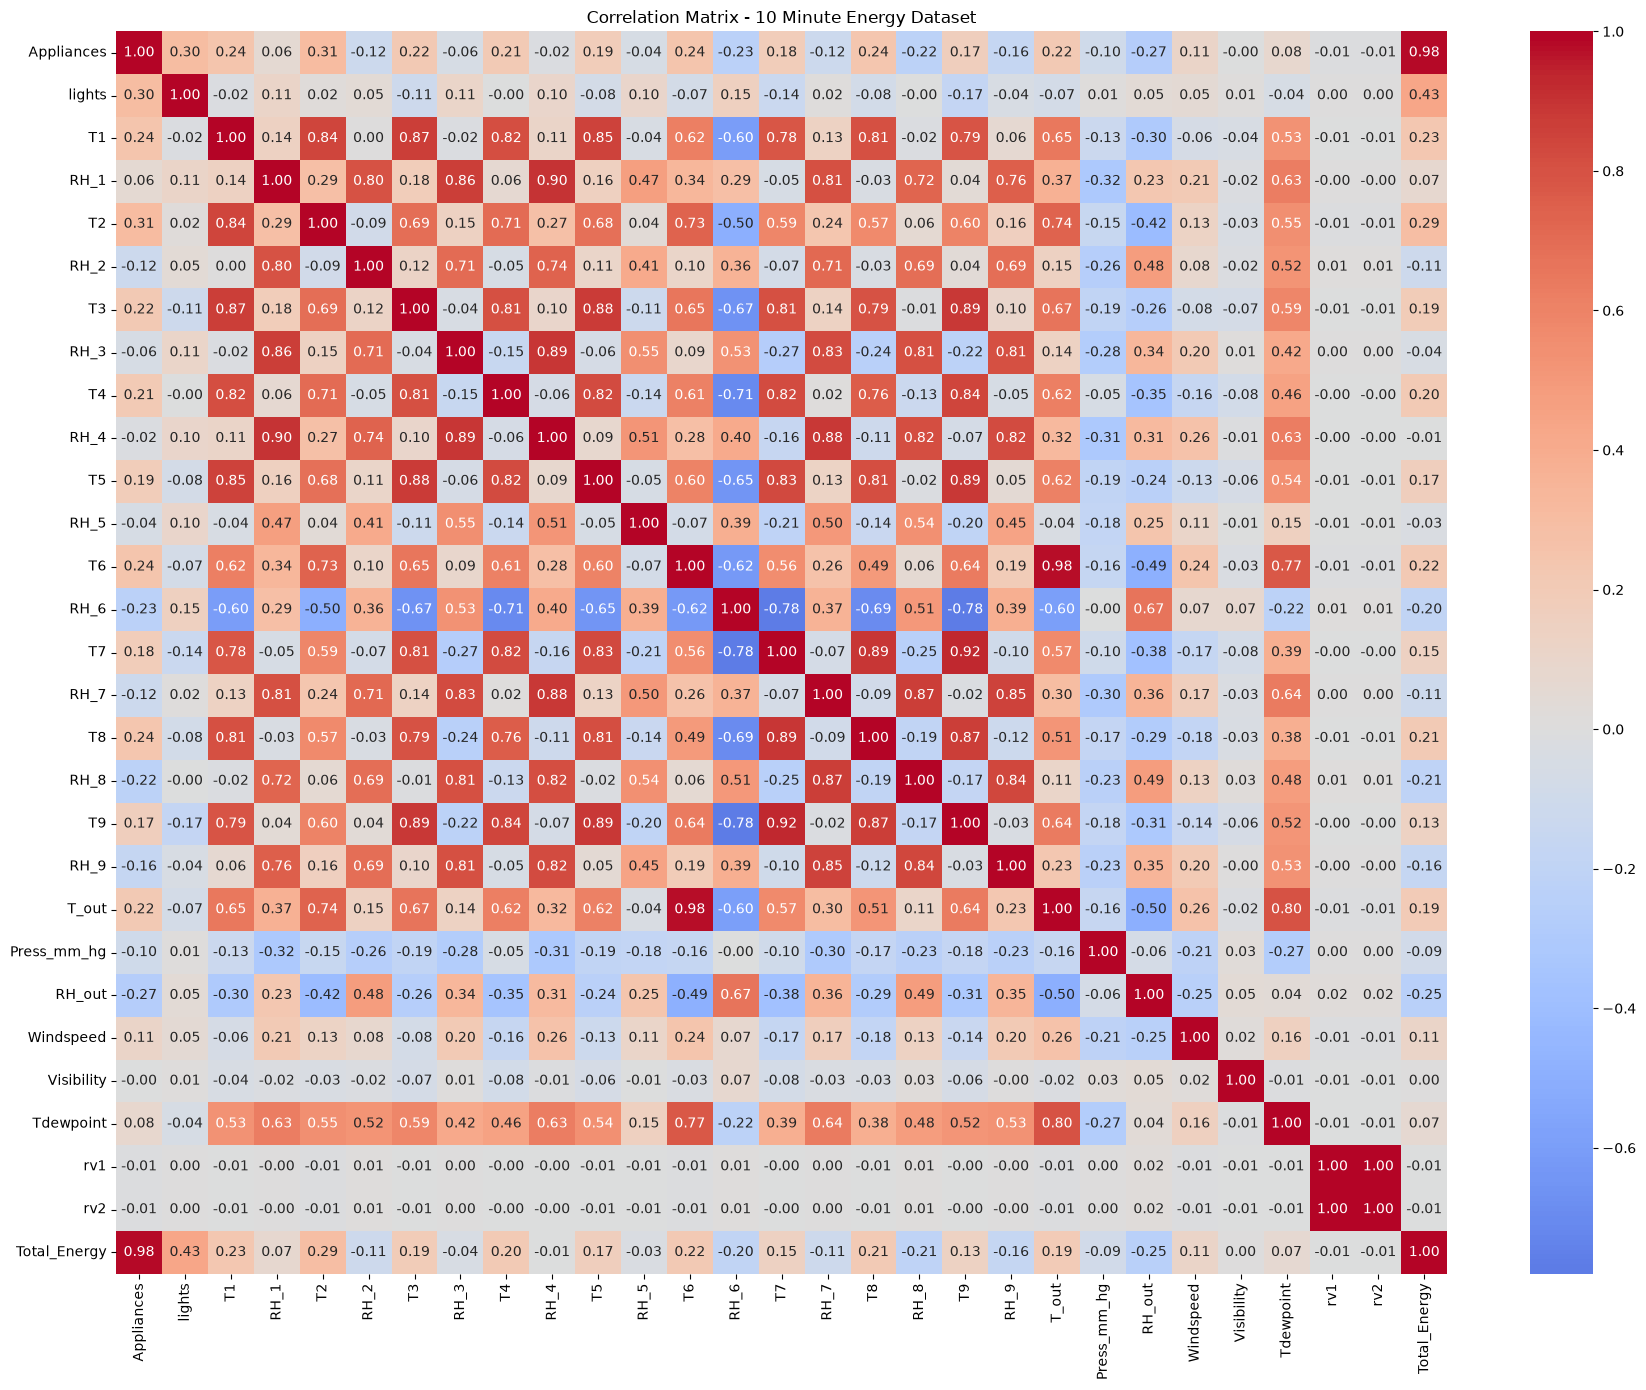

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 14))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix - 10 Minute Energy Dataset")
plt.tight_layout()
plt.show()

In [52]:
# Select all 9 indoor temperature columns
temp_cols = [f"T{i}" for i in range(1, 10)]

# Calculate average house temperature
df_10min["House_Temp"] = df_10min[temp_cols].mean(axis=1)

# Display results
display(df_10min[temp_cols + ["House_Temp"]].head(10))

,T1,T2,T3,T4,T5,T6,T7,T8,T9,House_Temp
date,,,,,,,,,,
2016-01-11 17:00:00,19.890000,19.20,19.79,19.000000,17.166667,7.026667,17.200000,18.2,17.033333,17.167407
2016-01-11 17:10:00,19.890000,19.20,19.79,19.000000,17.166667,6.833333,17.200000,18.2,17.066667,17.149630
2016-01-11 17:20:00,19.890000,19.20,19.79,18.926667,17.166667,6.560000,17.200000,18.2,17.000000,17.103704
2016-01-11 17:30:00,19.890000,19.20,19.79,18.890000,17.166667,6.433333,17.133333,18.1,17.000000,17.067037
2016-01-11 17:40:00,19.890000,19.20,19.79,18.890000,17.200000,6.366667,17.200000,18.1,17.000000,17.070741
2016-01-11 17:50:00,19.890000,19.20,19.79,18.890000,17.133333,6.300000,17.133333,18.1,17.000000,17.048519
2016-01-11 18:00:00,19.890000,19.20,19.79,18.890000,17.100000,6.263333,17.133333,18.1,17.000000,17.040741
2016-01-11 18:10:00,19.856667,19.20,19.73,18.890000,17.100000,6.190000,17.100000,18.1,17.000000,17.018519
2016-01-11 18:20:00,19.790000,19.20,19.73,18.890000,17.166667,6.123333,17.166667,18.1,17.000000,17.018519


In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display

# Load the two floor-plan images
floor1 = np.array(Image.open("../house_map/floor1.png").convert("RGB"))
floor2 = np.array(Image.open("../house_map/floor2.png").convert("RGB"))

# Sensor positions on each image (x, y)
# Based on the floor plans you supplied
sensors_floor1 = {
    "T1": (529, 569),
    "T2": (668, 143),
    "T3": (362, 350),
    "T4": (697, 663)
}

sensors_floor2 = {
    "T5": (298, 643),
    "T7": (588, 270),
    "T8": (525, 370),
    "T9": (391, 208)
}

# Prepare the original 10-minute data
data = df_10min.copy()

if "date" in data.columns:
    data["date"] = pd.to_datetime(data["date"])
    data = data.set_index("date")

data = data.sort_index()

# Create hourly energy and temperature records
temperature_cols = [
    "T1", "T2", "T3", "T4",
    "T5", "T7", "T8", "T9"
]

hourly = data.resample("1h").agg({
    **{col: "mean" for col in temperature_cols},
    "Total_Energy": "sum"
})

hourly["record_count"] = data["Total_Energy"].resample("1h").count()

# Create temperature overlay around sensor locations
def temperature_map(image, sensors, values, vmin, vmax):

    height, width = image.shape[:2]
    yy, xx = np.mgrid[0:height, 0:width]

    weighted_sum = np.zeros((height, width))
    weight_total = np.zeros((height, width))

    sigma = 125  # Heat spreading distance in pixels

    for sensor, (x, y) in sensors.items():

        temperature = values[sensor]

        weight = np.exp(
            -((xx - x)**2 + (yy - y)**2)
            / (2 * sigma**2)
        )

        weighted_sum += weight * temperature
        weight_total += weight

    heat = weighted_sum / np.maximum(weight_total, 1e-10)

    # Fade overlay away from known sensor locations
    alpha = 0.50 * np.clip(weight_total, 0, 1)

    return heat, alpha


# Main visualization function
def show_house_heatmap(selected_date, selected_hour):

    timestamp = pd.Timestamp(
        f"{selected_date} {selected_hour:02d}:00:00"
    )

    if timestamp not in hourly.index:
        print("No data available for this date and hour.")
        return

    row = hourly.loc[timestamp]

    if row["record_count"] == 0:
        print("No observations available.")
        return

    # Same temperature scale for both floors
    values = row[temperature_cols]
    vmin = values.min() - 1
    vmax = values.max() + 1

    fig, axes = plt.subplots(1, 2, figsize=(17, 8))

    for ax, image, sensors, name in zip(
        axes,
        [floor1, floor2],
        [sensors_floor1, sensors_floor2],
        ["First Floor", "Second Floor"]
    ):

        ax.imshow(image)

        heat, alpha = temperature_map(
            image, sensors, row, vmin, vmax
        )

        overlay = ax.imshow(
            heat,
            cmap="coolwarm",
            vmin=vmin,
            vmax=vmax,
            alpha=alpha
        )

        # Show sensor names and temperatures
        for sensor, (x, y) in sensors.items():

            ax.text(
                x, y,
                f"{sensor}\n{row[sensor]:.1f}°C",
                ha="center",
                va="center",
                fontsize=9,
                fontweight="bold",
                color="black",
                bbox=dict(
                    facecolor="white",
                    alpha=0.85,
                    boxstyle="round"
                )
            )

        ax.set_title(name, fontsize=15)
        ax.axis("off")

    fig.colorbar(
        overlay,
        ax=axes,
        shrink=0.65,
        label="Temperature (°C)"
    )

    fig.suptitle(
        f"House Temperature | {timestamp}",
        fontsize=17,
        fontweight="bold"
    )

    plt.show()

    # Total hourly energy
    print(f"Date and Time: {timestamp}")
    print(f"Total Energy: {row['Total_Energy']:.2f} Wh")
    print(f"Energy in kWh: {row['Total_Energy']/1000:.3f} kWh")
    print(f"10-minute records: {int(row['record_count'])}/6")

    if row["record_count"] != 6:
        print("Warning: This hour has incomplete measurements.")


# Interactive date and hour controls
dates = sorted(set(hourly.index.strftime("%Y-%m-%d")))

date_picker = widgets.Dropdown(
    options=dates,
    description="Date:"
)

hour_slider = widgets.IntSlider(
    value=12,
    min=0,
    max=23,
    step=1,
    description="Hour:"
)

widgets.interact(
    show_house_heatmap,
    selected_date=date_picker,
    selected_hour=hour_slider
)

interactive(children=(Dropdown(description='Date:', options=('2016-01-11', '2016-01-12', '2016-01-13', '2016-0…

<function __main__.show_house_heatmap(selected_date, selected_hour)>

## Feature Distribution and Correlation Analysis

In [54]:

# Five-number summary of Kitchen Temperature (T1)

feature = "T1"

five_number_summary = df[feature].describe()[
    ["min", "25%", "50%", "75%", "max"]
]

print(f"Five-Number Summary of {feature}")
print(five_number_summary)

# Calculate Interquartile Range
Q1 = five_number_summary["25%"]
Q3 = five_number_summary["75%"]

IQR = Q3 - Q1

print(f"\nIQR: {IQR:.2f}")


Five-Number Summary of T1
min    16.79
25%    20.76
50%    21.60
75%    22.60
max    26.26
Name: T1, dtype: float64

IQR: 1.84


Five-Number Summary:
min    16.79
25%    20.76
50%    21.60
75%    22.60
max    26.26
Name: T1, dtype: float64

Additional Statistics:
Mean              : 21.6866
Variance          : 2.5794
Standard Deviation: 1.6061
IQR               : 1.8400
Skewness          : 0.1209


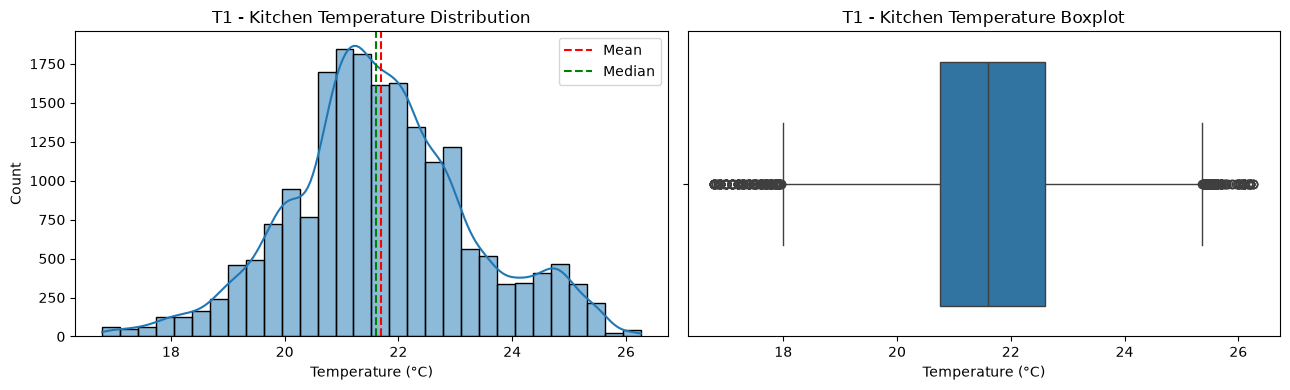

In [55]:



feature = "T1"

# Descriptive statistics
stats = df[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean              : {df[feature].mean():.4f}")
print(f"Variance          : {df[feature].var():.4f}")
print(f"Standard Deviation: {df[feature].std():.4f}")
print(f"IQR               : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness          : {df[feature].skew():.4f}")

# Distribution and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].axvline(df[feature].mean(),
                color="red", linestyle="--", label="Mean")
axes[0].axvline(df[feature].median(),
                color="green", linestyle="--", label="Median")
axes[0].set_title("T1 - Kitchen Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(x=df[feature], ax=axes[1])
axes[1].set_title("T1 - Kitchen Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [56]:

# Check negative temperatures in our dataset

temp_columns = [f"T{i}" for i in range(1, 10)] + ["T_out", "Tdewpoint"]

negative_summary = pd.DataFrame({
    "Minimum": df[temp_columns].min(),
    "Mean": df[temp_columns].mean(),
    "Negative_Count": (df[temp_columns] < 0).sum(),
    "Negative_Percentage": (df[temp_columns] < 0).mean() * 100
})

display(negative_summary.round(3))


,Minimum,Mean,Negative_Count,Negative_Percentage
T1,16.790,21.687,0,0.000
T2,16.100,20.341,0,0.000
T3,17.200,22.268,0,0.000
T4,15.100,20.855,0,0.000
T5,15.330,19.592,0,0.000
T6,-6.065,7.911,1360,6.891
T7,15.390,20.267,0,0.000
T8,16.307,22.029,0,0.000
T9,14.890,19.486,0,0.000
T_out,-5.000,7.412,1154,5.847


In [57]:

# T1 vs Total_Energy — Correlation methods

pearson = df["T1"].corr(df["Total_Energy"], method="pearson")
spearman = df["T1"].corr(df["Total_Energy"], method="spearman")
kendall = df["T1"].corr(df["Total_Energy"], method="kendall")

print(f"Pearson Correlation  : {pearson:.4f}")
print(f"Spearman Correlation : {spearman:.4f}")
print(f"Kendall Correlation  : {kendall:.4f}")


Pearson Correlation  : 0.0527
Spearman Correlation : 0.2281
Kendall Correlation  : 0.1615


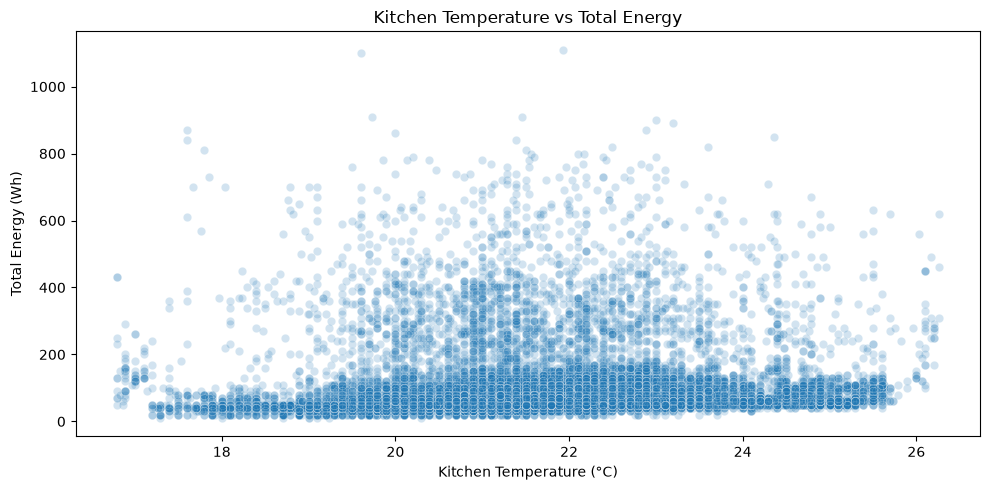

In [58]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="T1",
    y="Total_Energy",
    alpha=0.2
)

plt.title("Kitchen Temperature vs Total Energy")
plt.xlabel("Kitchen Temperature (°C)")
plt.ylabel("Total Energy (Wh)")

plt.tight_layout()
plt.show()

Observations: 19452
Median Energy: 60.00 Wh
Lower Bound: -25.00 Wh
Upper Bound: 175.00 Wh
Outliers: 1777


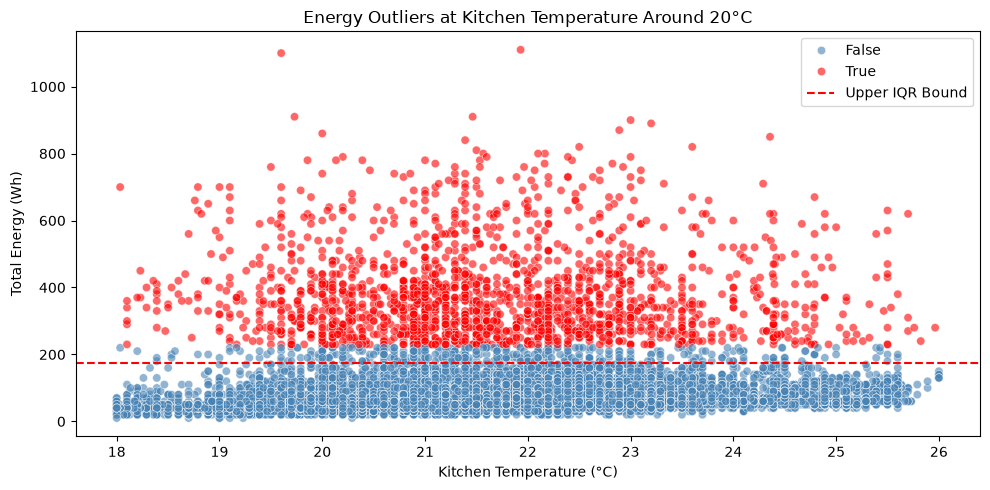

In [59]:

# Select observations around 20°C
t1_group = df[df["T1"].between(18, 26)].copy()

# Calculate conditional IQR bounds
Q1 = t1_group["Total_Energy"].quantile(0.25)
Q3 = t1_group["Total_Energy"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag unusual energy values
t1_group["Energy_Outlier"] = (
    (t1_group["Total_Energy"] < lower_bound) |
    (t1_group["Total_Energy"] > upper_bound + 50)
)

print(f"Observations: {len(t1_group)}")
print(f"Median Energy: {t1_group['Total_Energy'].median():.2f} Wh")
print(f"Lower Bound: {lower_bound:.2f} Wh")
print(f"Upper Bound: {upper_bound:.2f} Wh")
print(f"Outliers: {t1_group['Energy_Outlier'].sum()}")

# Visualize
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=t1_group,
    x="T1",
    y="Total_Energy",
    hue="Energy_Outlier",
    palette={False: "steelblue", True: "red"},
    alpha=0.6
)

plt.axhline(
    upper_bound,
    color="red",
    linestyle="--",
    label="Upper IQR Bound"
)

plt.title("Energy Outliers at Kitchen Temperature Around 20°C")
plt.xlabel("Kitchen Temperature (°C)")
plt.ylabel("Total Energy (Wh)")
plt.legend()
plt.tight_layout()
plt.show()


,mean,std,min,max
Hour,,,,
0,21.98,1.39,17.50,25.29
1,21.81,1.41,17.50,25.20
2,21.65,1.43,17.39,25.10
3,21.50,1.45,17.39,25.10
4,21.36,1.47,17.29,25.00
5,21.24,1.50,17.29,25.00
6,21.15,1.53,17.23,25.00
7,21.07,1.56,17.20,24.89
8,21.05,1.58,17.10,24.86


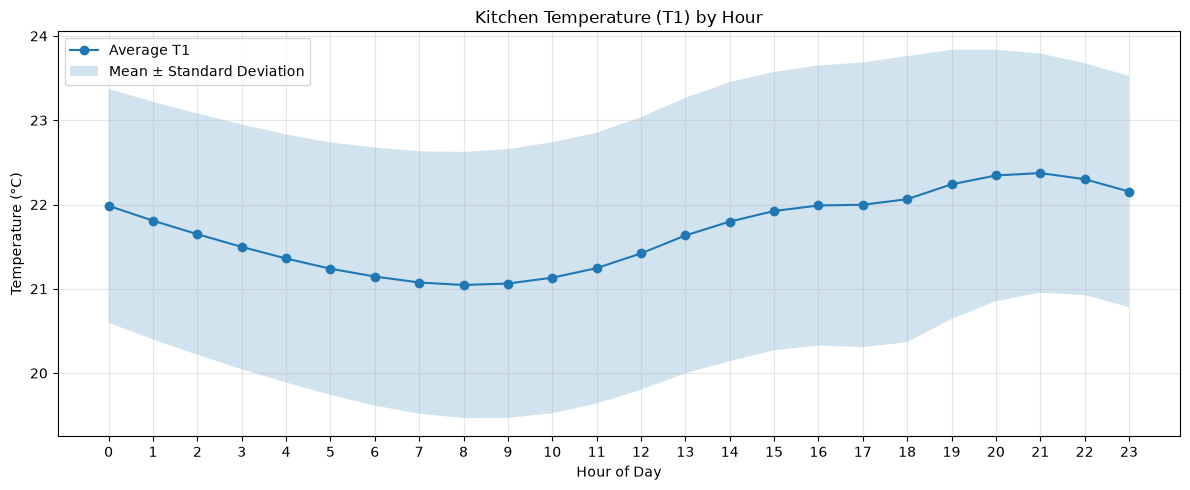

In [60]:

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Extract hour from date
df["Hour"] = df["date"].dt.hour

# Calculate hourly kitchen temperature statistics
t1_hourly = df.groupby("Hour")["T1"].agg(
    ["mean", "std", "min", "max"]
)

display(t1_hourly.round(2))


plt.figure(figsize=(12, 5))

plt.plot(
    t1_hourly.index,
    t1_hourly["mean"],
    marker="o",
    label="Average T1"
)

plt.fill_between(
    t1_hourly.index,
    t1_hourly["mean"] - t1_hourly["std"],
    t1_hourly["mean"] + t1_hourly["std"],
    alpha=0.2,
    label="Mean ± Standard Deviation"
)

plt.title("Kitchen Temperature (T1) by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Temperature (°C)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()





# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Extract hour
df["Hour"] = df["date"].dt.hour

# Hourly average across all days
hourly = df.groupby("Hour")[["T1", "Total_Energy"]].mean()

# Create graph
fig, ax1 = plt.subplots(figsize=(12, 5))

# T1 temperature
ax1.plot(
    hourly.index,
    hourly["T1"],
    color="red",
    marker="o",
    label="Average T1"
)

ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("Kitchen Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Second Y-axis for Total Energy
ax2 = ax1.twinx()

ax2.plot(
    hourly.index,
    hourly["Total_Energy"],
    color="blue",
    marker="s",
    label="Average Total Energy"
)

ax2.set_ylabel("Average Total Energy (Wh)", color="blue")
ax2.tick_params(axis="y", labelcolor="blue")

plt.title("Hourly Kitchen Temperature vs Total Energy")
ax1.set_xticks(range(24))
ax1.grid(alpha=0.3)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2)

plt.tight_layout()
plt.show()



## EDA Step 2.7.1 — T1 (Kitchen Temperature) Feature Analysis

### 1. Feature Description

- **Feature:** T1
- **Description:** Kitchen temperature
- **Unit:** Degrees Celsius (°C)
- **Target Variable:** Total_Energy (Wh)

### 2. Descriptive Statistics

We analyze the following statistical measures:

- **Mean:** Average kitchen temperature.
- **Median:** Central value of kitchen temperature.
- **Variance:** Variability of temperature observations.
- **Standard Deviation:** Spread of observations around the mean.
- **Five-Number Summary:** Minimum, Q1, Median, Q3, Maximum.
- **IQR:** Spread of the middle 50% of observations.
- **Skewness:** Asymmetry of the temperature distribution.

These statistics help us understand temperature variation before evaluating its relationship with energy consumption.

### 3. Correlation Analysis

We calculated three correlation coefficients between T1 and Total_Energy.

| Correlation Method | Value | Interpretation |
|---|---:|---|
| Pearson | 0.0527 | Very weak positive linear relationship |
| Spearman | 0.2281 | Weak positive monotonic relationship |
| Kendall Tau | 0.1615 | Weak positive rank association |

### 4. Statistical Interpretation

**Pearson Correlation (r = 0.0527)**

The Pearson coefficient is close to zero, indicating almost no linear relationship between kitchen temperature and total household energy consumption.

**Spearman Correlation (ρ = 0.2281)**

Spearman correlation is higher than Pearson correlation, suggesting a weak positive monotonic relationship.

This difference may occur because:

- The relationship is nonlinear but monotonic.
- Extreme energy observations influence Pearson correlation.
- The relationship contains substantial variability.

Further investigation using scatterplots is required.

**Kendall Correlation (τ = 0.1615)**

Kendall's Tau indicates weak positive agreement between the rankings of kitchen temperature and total energy consumption.

### 5. Key Findings

1. Kitchen temperature has a very weak linear association with Total_Energy.
2. Rank-based methods identify a weak positive association.
3. Temperature alone is unlikely to explain much of the variation in household energy consumption through a linear relationship.
4. Correlation does not establish causation.
5. Further analysis is required to investigate nonlinear relationships, outliers, and time-dependent patterns.

### 6. Conclusion

T1 shows a weak positive association with Total_Energy.

The difference between Pearson and Spearman suggests that a simple linear relationship may not fully describe the observed association.

Therefore, T1 should not be removed based only on its low Pearson correlation. Its usefulness for machine learning prediction must be evaluated alongside other features and temporal patterns.


##  Understanding RH_1 (Humidity in kitchen area, in %)

Five-Number Summary:
min    27.023333
25%    37.333333
50%    39.656667
75%    43.066667
max    63.360000
Name: RH_1, dtype: float64

Additional Statistics:
Mean               : 40.2597
Variance           : 15.8348
Standard Deviation : 3.9793
IQR                : 5.7333
Skewness           : 0.4658


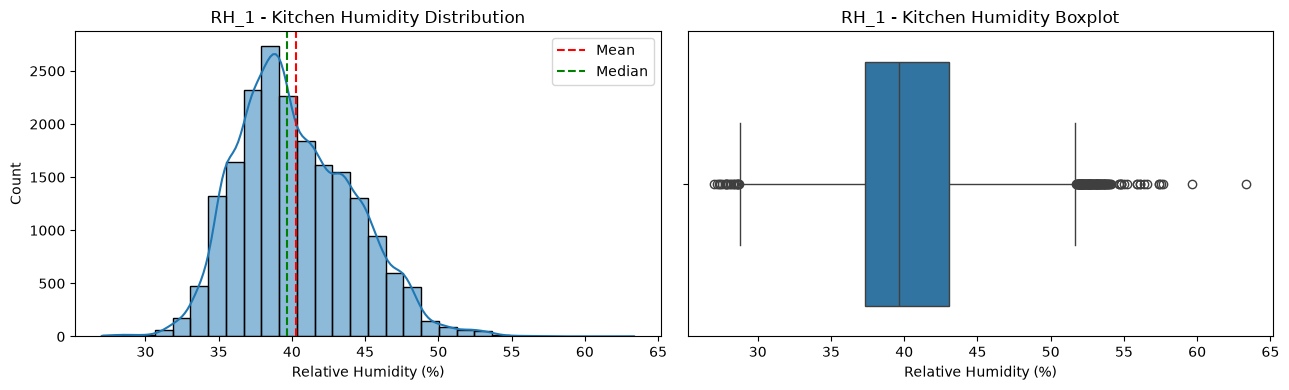

In [61]:

feature = "RH_1"

# Descriptive statistics
stats = df[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df[feature].mean():.4f}")
print(f"Variance           : {df[feature].var():.4f}")
print(f"Standard Deviation : {df[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df[feature].skew():.4f}")

# Distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)
axes[0].axvline(
    df[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)
axes[0].axvline(
    df[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)
axes[0].set_title("RH_1 - Kitchen Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

sns.boxplot(x=df[feature], ax=axes[1])
axes[1].set_title("RH_1 - Kitchen Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [62]:

# RH_1 correlation with Total_Energy

pearson = df["RH_1"].corr(
    df["Total_Energy"], method="pearson"
)

spearman = df["RH_1"].corr(
    df["Total_Energy"], method="spearman"
)

kendall = df["RH_1"].corr(
    df["Total_Energy"], method="kendall"
)

print(f"Pearson  : {pearson:.4f}")
print(f"Spearman : {spearman:.4f}")
print(f"Kendall  : {kendall:.4f}")


Pearson  : 0.0926
Spearman : 0.0724
Kendall  : 0.0496


In [63]:

# RH_1 correlation with Total_Energy

pearson = df["RH_1"].corr(
    df["T1"], method="pearson"
)

spearman = df["RH_1"].corr(
    df["T1"], method="spearman"
)

kendall = df["RH_1"].corr(
    df["T1"], method="kendall"
)

print(f"Pearson  : {pearson:.4f}")
print(f"Spearman : {spearman:.4f}")
print(f"Kendall  : {kendall:.4f}")


Pearson  : 0.1640
Spearman : 0.1394
Kendall  : 0.0942


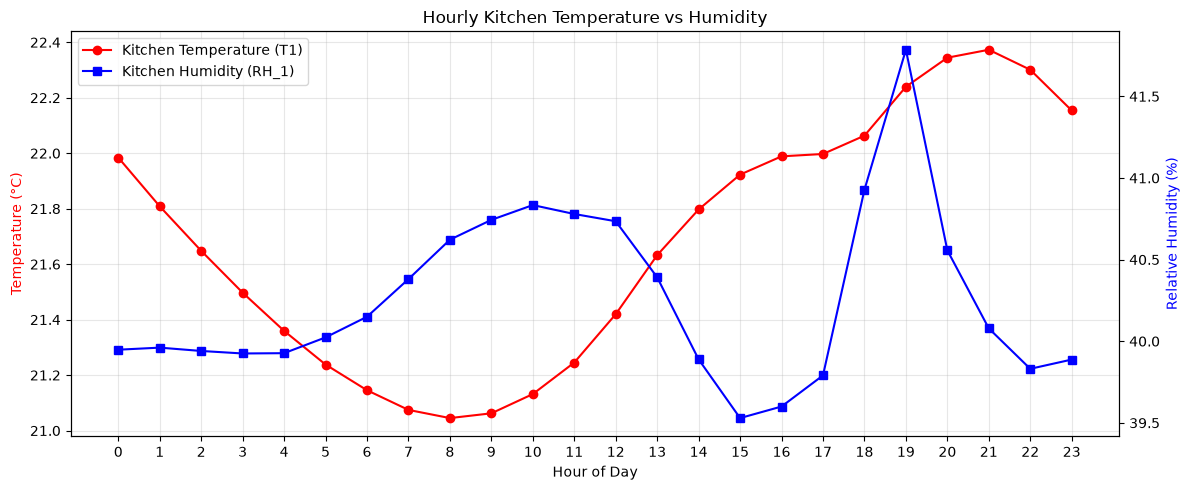

In [64]:

# Extract hour
df["Hour"] = pd.to_datetime(df["date"]).dt.hour

# Calculate hourly averages
hourly = df.groupby("Hour")[["T1", "RH_1"]].mean()

# Plot
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    hourly.index,
    hourly["T1"],
    color="red",
    marker="o",
    label="Kitchen Temperature (T1)"
)

ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("Temperature (°C)", color="red")

ax2 = ax1.twinx()

ax2.plot(
    hourly.index,
    hourly["RH_1"],
    color="blue",
    marker="s",
    label="Kitchen Humidity (RH_1)"
)

ax2.set_ylabel("Relative Humidity (%)", color="blue")

ax1.set_xticks(range(24))
ax1.grid(alpha=0.3)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Hourly Kitchen Temperature vs Humidity")
plt.tight_layout()
plt.show()


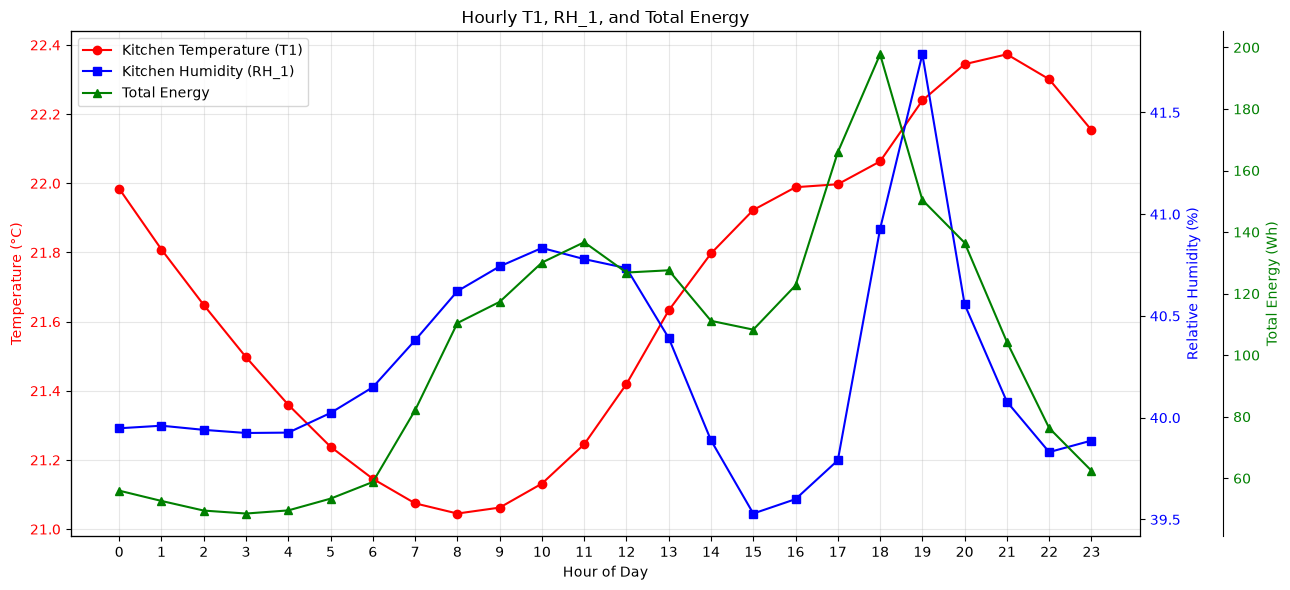

In [65]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Extract hour
df["Hour"] = df["date"].dt.hour

# Hourly mean values
hourly = df.groupby("Hour")[["T1", "RH_1", "Total_Energy"]].mean()

# Create figure
fig, ax1 = plt.subplots(figsize=(13, 6))

# First axis: T1
ax1.plot(
    hourly.index,
    hourly["T1"],
    color="red",
    marker="o",
    label="Kitchen Temperature (T1)"
)
ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")
ax1.set_xticks(range(24))
ax1.grid(alpha=0.3)

# Second axis: RH_1
ax2 = ax1.twinx()
ax2.plot(
    hourly.index,
    hourly["RH_1"],
    color="blue",
    marker="s",
    label="Kitchen Humidity (RH_1)"
)
ax2.set_ylabel("Relative Humidity (%)", color="blue")
ax2.tick_params(axis="y", labelcolor="blue")

# Third axis: Total_Energy
ax3 = ax1.twinx()
ax3.spines["right"].set_position(("outward", 60))   # move third axis outward
ax3.plot(
    hourly.index,
    hourly["Total_Energy"],
    color="green",
    marker="^",
    label="Total Energy"
)
ax3.set_ylabel("Total Energy (Wh)", color="green")
ax3.tick_params(axis="y", labelcolor="green")

# Combine legends
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
lines3, labels3 = ax3.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2 + lines3,
    labels1 + labels2 + labels3,
    loc="upper left"
)

plt.title("Hourly T1, RH_1, and Total Energy")
plt.tight_layout()
plt.show()

In [66]:

# Hourly average data
hourly = df.groupby("Hour")[
    ["T1", "RH_1", "Total_Energy"]
].mean()

# Calculate correlations
results = pd.DataFrame({
    "Pearson": [
        hourly["T1"].corr(hourly["Total_Energy"]),
        hourly["RH_1"].corr(hourly["Total_Energy"])
    ],
    "Spearman": [
        hourly["T1"].corr(hourly["Total_Energy"], method="spearman"),
        hourly["RH_1"].corr(hourly["Total_Energy"], method="spearman")
    ]
}, index=["T1", "RH_1"])

display(results.round(4))


,Pearson,Spearman
T1,0.2162,0.1913
RH_1,0.5445,0.4791


In [67]:

# Sort observations by timestamp
data = df.sort_values("date").copy()

# Global IQR threshold
Q1 = data["Total_Energy"].quantile(0.25)
Q3 = data["Total_Energy"].quantile(0.75)
IQR = Q3 - Q1

upper_bound = Q3 + 1.5 * IQR

# Previous and next energy observations
data["Previous_Energy"] = data["Total_Energy"].shift(1)
data["Next_Energy"] = data["Total_Energy"].shift(-1)

# Compare each observation with its neighbors
data["Neighbor_Mean"] = (
    data["Previous_Energy"] + data["Next_Energy"]
) / 2

# Flag isolated high-energy spikes
data["Suspicious_Spike"] = (
    (data["Total_Energy"] > upper_bound) &
    (data["Total_Energy"] > 3 * data["Neighbor_Mean"]) &
    (data["date"].diff().eq(pd.Timedelta(minutes=10))) &
    (data["date"].shift(-1).sub(data["date"]).eq(
        pd.Timedelta(minutes=10)
    ))
)

# Display detected observations
spikes = data.loc[
    data["Suspicious_Spike"],
    [
        "date", "T1", "RH_1",
        "Previous_Energy", "Total_Energy",
        "Next_Energy"
    ]
]

print("Upper IQR Bound:", round(upper_bound, 2))
print("Suspicious Spike Count:", len(spikes))

display(spikes.head(20))


Upper IQR Bound: 175.0
Suspicious Spike Count: 48


,date,T1,RH_1,Previous_Energy,Total_Energy,Next_Energy
121,2016-01-12 13:10:00,20.100000,46.430000,60.0,290,130.0
377,2016-01-14 07:50:00,18.390000,44.022500,70.0,390,100.0
443,2016-01-14 18:50:00,22.166667,40.500000,110.0,800,390.0
1234,2016-01-20 06:40:00,18.500000,39.790000,50.0,350,160.0
1536,2016-01-22 09:00:00,18.500000,38.560000,80.0,340,50.0
2105,2016-01-26 07:50:00,20.200000,44.433333,70.0,410,200.0
2248,2016-01-27 07:40:00,19.890000,45.863333,110.0,310,50.0
4415,2016-02-11 08:50:00,19.890000,43.060000,60.0,410,70.0
4475,2016-02-11 18:50:00,22.430000,43.000000,270.0,780,140.0
4617,2016-02-12 18:30:00,21.323333,39.796667,130.0,430,130.0


In [68]:

# Investigate one suspicious energy spike

data = df.copy()
data["date"] = pd.to_datetime(data["date"])

start = "2016-01-22 08:30:00"
end = "2016-01-22 09:30:00"

columns = [
    "date",
    "Appliances",
    "lights",
    "Total_Energy",
    "T1",
    "RH_1",
    "T_out",
    "RH_out"
]

spike_window = data.loc[
    data["date"].between(start, end),
    columns
].sort_values("date")

display(spike_window)


,date,Appliances,lights,Total_Energy,T1,RH_1,T_out,RH_out
1533,2016-01-22 08:30:00,50,20,70,18.533333,38.933333,-0.450000,79.500000
1534,2016-01-22 08:40:00,30,0,30,18.500000,38.760000,-0.333333,79.000000
1535,2016-01-22 08:50:00,80,0,80,18.500000,38.700000,-0.216667,78.500000
1536,2016-01-22 09:00:00,340,0,340,18.500000,38.560000,-0.100000,78.000000
1537,2016-01-22 09:10:00,50,0,50,18.500000,38.433333,-0.066667,78.166667
1538,2016-01-22 09:20:00,50,0,50,18.463333,38.466667,-0.033333,78.333333
1539,2016-01-22 09:30:00,60,0,60,18.390000,38.400000,0.000000,78.500000


In [69]:

import pandas as pd

# 1. Ensure datetime format
df["date"] = pd.to_datetime(df["date"])

# 2. Sort temporarily by time
temp = df.sort_values("date").copy()

# 3. Calculate IQR bounds
Q1 = temp["Total_Energy"].quantile(0.25)
Q3 = temp["Total_Energy"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# 4. Previous and next energy values
previous = temp["Total_Energy"].shift(1)
next_value = temp["Total_Energy"].shift(-1)

neighbor_mean = (previous + next_value) / 2

# 5. Flag isolated suspicious spikes
temp["spike_outlier"] = (
    (temp["Total_Energy"] > upper_bound) &
    (temp["Total_Energy"] > 3 * neighbor_mean) &
    (temp["date"].diff() == pd.Timedelta(minutes=10)) &
    (temp["date"].shift(-1) - temp["date"] ==
     pd.Timedelta(minutes=10))
).astype(int)

# 6. Add flags to original DataFrame by row index
df["spike_outlier"] = temp["spike_outlier"].reindex(df.index)

# 7. Verify results
print("Upper IQR Bound:", upper_bound)
print("Total Spike Outliers:", df["spike_outlier"].sum())

display(
    df.loc[
        df["spike_outlier"] == 1,
        ["date", "T1", "RH_1", "Total_Energy", "spike_outlier"]
    ]
)


Upper IQR Bound: 175.0
Total Spike Outliers: 48


,date,T1,RH_1,Total_Energy,spike_outlier
121,2016-01-12 13:10:00,20.100000,46.430000,290,1
377,2016-01-14 07:50:00,18.390000,44.022500,390,1
443,2016-01-14 18:50:00,22.166667,40.500000,800,1
1234,2016-01-20 06:40:00,18.500000,39.790000,350,1
1536,2016-01-22 09:00:00,18.500000,38.560000,340,1
2105,2016-01-26 07:50:00,20.200000,44.433333,410,1
2248,2016-01-27 07:40:00,19.890000,45.863333,310,1
4415,2016-02-11 08:50:00,19.890000,43.060000,410,1
4475,2016-02-11 18:50:00,22.430000,43.000000,780,1
4617,2016-02-12 18:30:00,21.323333,39.796667,430,1


## T2 (Living Room Temperature)

Five-Number Summary:
min    16.100000
25%    18.790000
50%    20.000000
75%    21.500000
max    29.856667
Name: T2, dtype: float64

Additional Statistics:
Mean               : 20.3412
Variance           : 4.8091
Standard Deviation : 2.1930
IQR                : 2.7100
Skewness           : 0.8897


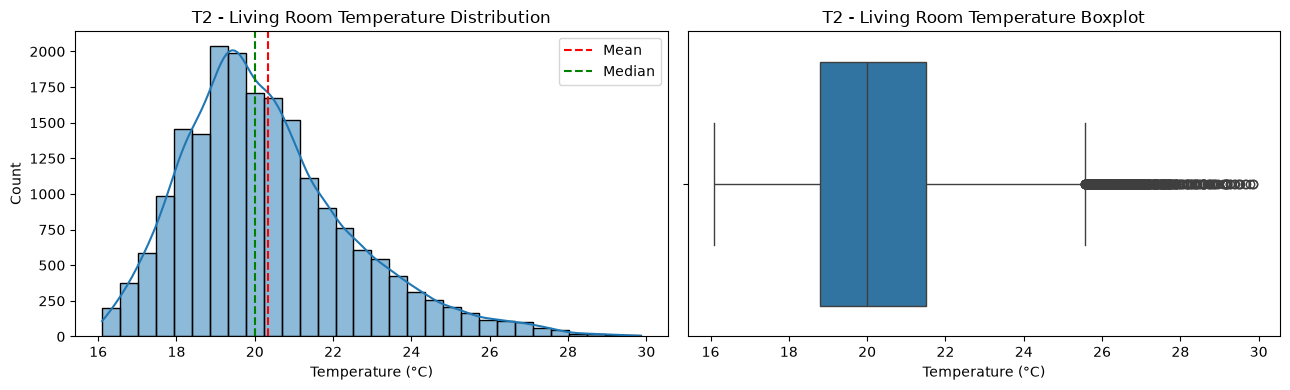

In [70]:
feature = "T2"

# Descriptive statistics
stats = df[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df[feature].mean():.4f}")
print(f"Variance           : {df[feature].var():.4f}")
print(f"Standard Deviation : {df[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df[feature].skew():.4f}")

# Distribution and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T2 - Living Room Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(x=df[feature], ax=axes[1])
axes[1].set_title("T2 - Living Room Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [71]:


# Calculate IQR for T2
Q1 = df["T2"].quantile(0.25)
Q3 = df["T2"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create outlier flag
df["T2_outlier"] = (
    (df["T2"] < lower_bound) |
    (df["T2"] > upper_bound)
).astype(int)

# Display results
print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total Outliers: {df['T2_outlier'].sum()}")
print(f"Outlier Percentage: {df['T2_outlier'].mean() * 100:.2f}%")

# Display all outlier observations
display(
    df.loc[
        df["T2_outlier"] == 1,
        ["date", "T2", "Total_Energy", "T2_outlier"]
    ]
)


Lower Bound: 14.72 °C
Upper Bound: 25.57 °C
Total Outliers: 546
Outlier Percentage: 2.77%


,date,T2,Total_Energy,T2_outlier
16229,2016-05-03 09:50:00,25.633333,60,1
16230,2016-05-03 10:00:00,25.730000,50,1
16231,2016-05-03 10:10:00,25.865000,60,1
16232,2016-05-03 10:20:00,25.890000,50,1
16233,2016-05-03 10:30:00,25.890000,40,1
16234,2016-05-03 10:40:00,25.890000,60,1
16235,2016-05-03 10:50:00,25.856667,50,1
16236,2016-05-03 11:00:00,25.790000,60,1
16237,2016-05-03 11:10:00,25.700000,60,1
16238,2016-05-03 11:20:00,25.700000,60,1


In [72]:

# T2 vs Total_Energy correlation
feature = "T2"
target = "Total_Energy"

pearson = df[feature].corr(df[target], method="pearson")
spearman = df[feature].corr(df[target], method="spearman")
kendall = df[feature].corr(df[target], method="kendall")

# Display results
results = pd.DataFrame({
    "Method": ["Pearson", "Spearman", "Kendall"],
    "Correlation": [pearson, spearman, kendall]
})

display(results.round(4))


,Method,Correlation
0,Pearson,0.1175
1,Spearman,0.2924
2,Kendall,0.2043


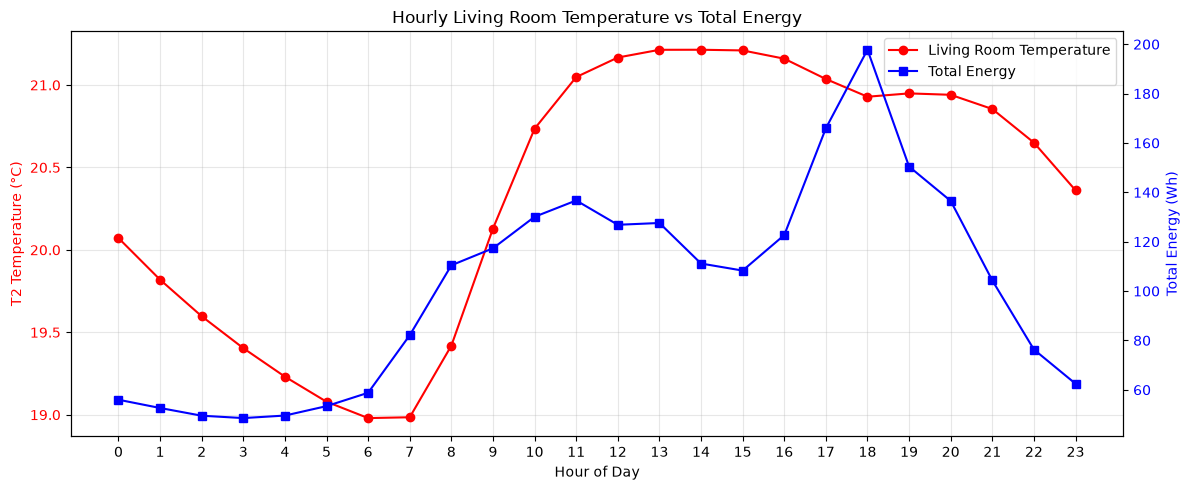

In [73]:
# Extract hour
df["Hour"] = pd.to_datetime(df["date"]).dt.hour

# Calculate hourly averages
hourly = df.groupby("Hour")[["T2", "Total_Energy"]].mean()

# Plot
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(
    hourly.index,
    hourly["T2"],
    color="red",
    marker="o",
    label="Living Room Temperature"
)

ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("T2 Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

ax2 = ax1.twinx()

ax2.plot(
    hourly.index,
    hourly["Total_Energy"],
    color="blue",
    marker="s",
    label="Total Energy"
)

ax2.set_ylabel("Total Energy (Wh)", color="blue")
ax2.tick_params(axis="y", labelcolor="blue")

ax1.set_xticks(range(24))
ax1.grid(alpha=0.3)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Hourly Living Room Temperature vs Total Energy")
plt.tight_layout()
plt.show()


### T2 — Living Room Temperature: Relationship with Total_Energy

The Pearson correlation coefficient (0.1175) indicates a very weak positive linear relationship between living room temperature and total household energy consumption.

The Spearman correlation coefficient (0.2924) suggests a weak positive monotonic association.

Hourly analysis shows that living room temperature and energy consumption increase together during certain periods, particularly in the morning. However, during the afternoon and evening, energy consumption changes considerably while living room temperature remains relatively stable.

These findings suggest that living room temperature alone cannot adequately explain household energy consumption. Other factors, including appliance usage, occupancy patterns, and environmental conditions, may contribute to energy variability.

**Conclusion:** T2 exhibits a weak positive association with Total_Energy. Despite its low correlation, the feature should be retained for further multivariate and time-series analysis before making any feature-selection decisions.

## RH_2, Humidity in living room area, in %

Five-Number Summary:
min    20.463333
25%    37.900000
50%    40.500000
75%    43.260000
max    56.026667
Name: RH_2, dtype: float64

Additional Statistics:
Mean               : 40.4204
Variance           : 16.5634
Standard Deviation : 4.0698
IQR                : 5.3600
Skewness           : -0.2682


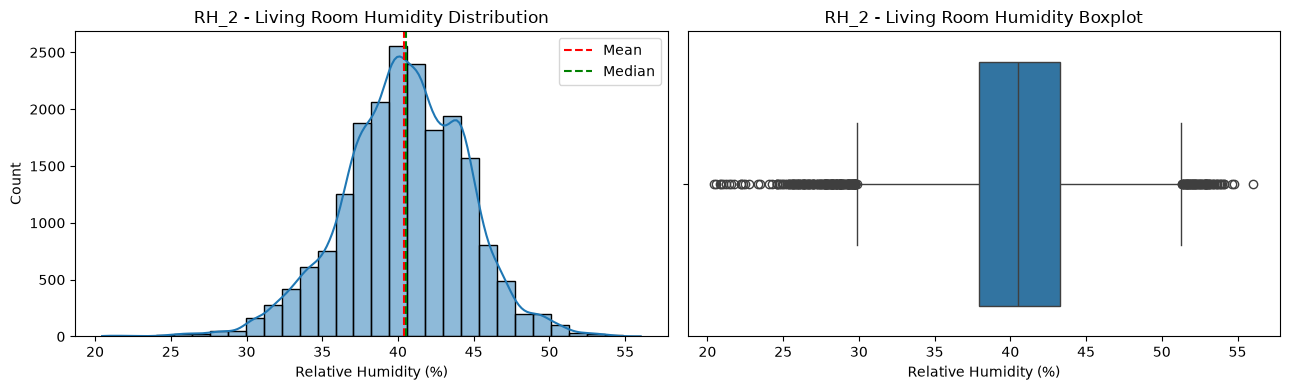

In [74]:


feature = "RH_2"

# Five-number summary
stats = df[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional descriptive statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df[feature].mean():.4f}")
print(f"Variance           : {df[feature].var():.4f}")
print(f"Standard Deviation : {df[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df[feature].skew():.4f}")

# Distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
sns.histplot(
    df[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_2 - Living Room Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

# Boxplot
sns.boxplot(x=df[feature], ax=axes[1])
axes[1].set_title("RH_2 - Living Room Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [75]:
feature = "RH_2"
target = "Total_Energy"

# Calculate three correlation methods
pearson = df[feature].corr(df[target], method="pearson")
spearman = df[feature].corr(df[target], method="spearman")
kendall = df[feature].corr(df[target], method="kendall")

# Display results
results = pd.DataFrame({
    "Method": ["Pearson", "Spearman", "Kendall"],
    "Correlation": [pearson, spearman, kendall]
})

display(results.round(4))


,Method,Correlation
0,Pearson,-0.0555
1,Spearman,-0.1063
2,Kendall,-0.0732


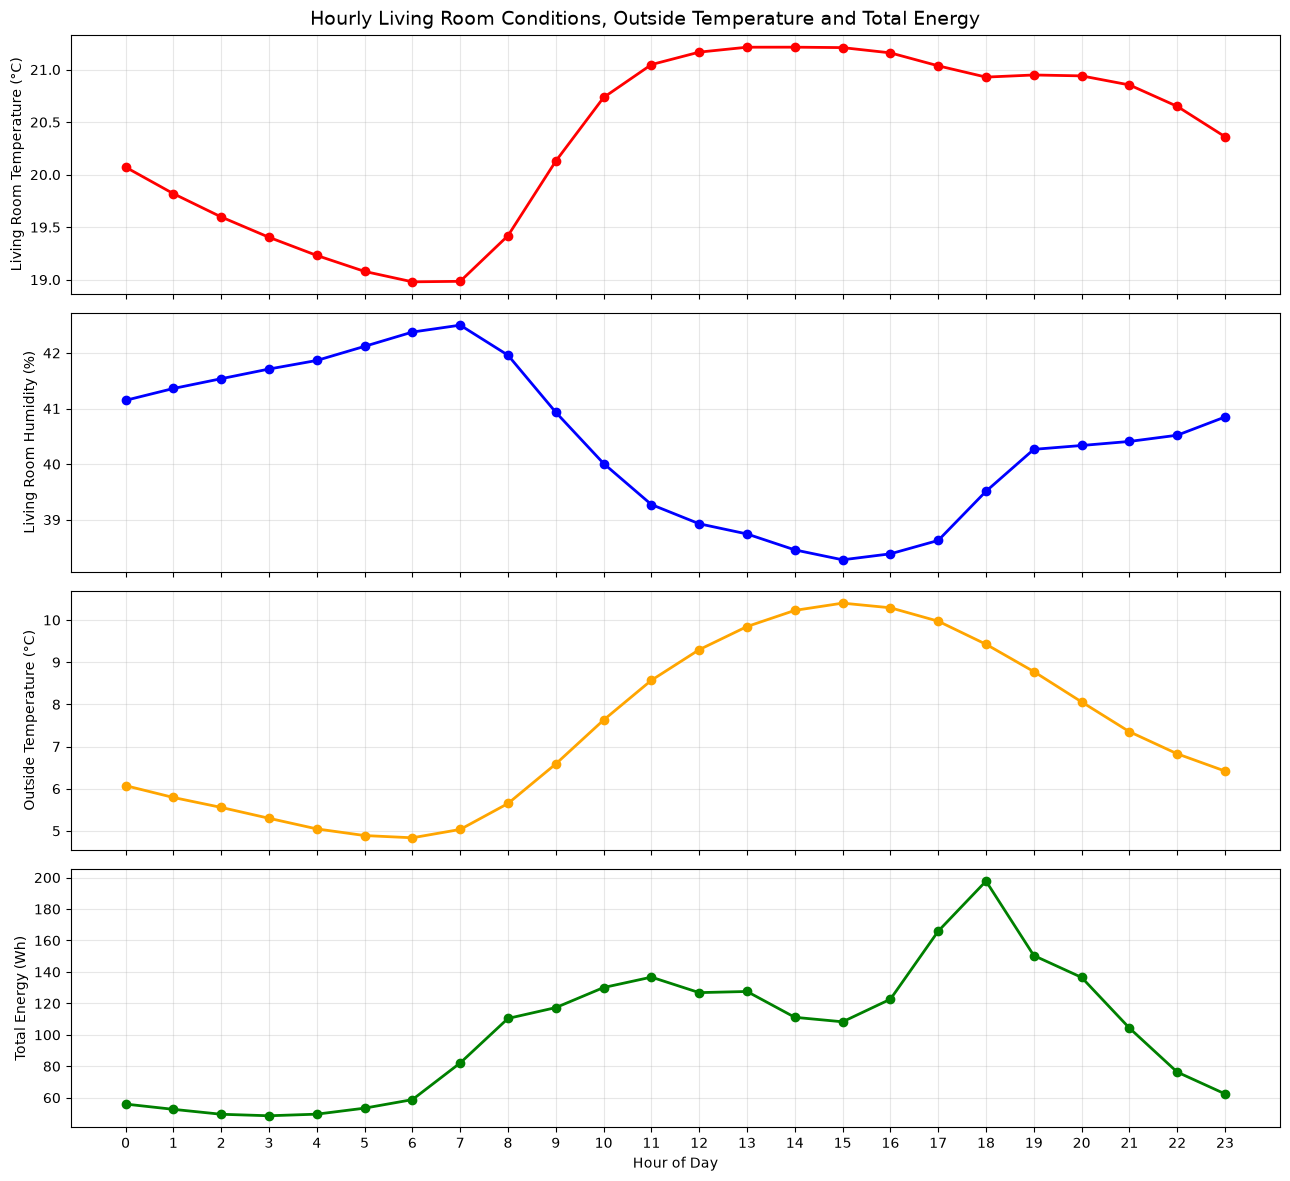

In [76]:

import pandas as pd
import matplotlib.pyplot as plt

# Extract hour from timestamp
df["date"] = pd.to_datetime(df["date"])
df["Hour"] = df["date"].dt.hour

# Calculate hourly averages across all days
hourly = df.groupby("Hour")[
    ["T2", "RH_2", "T_out", "Total_Energy"]
].mean()

fig, axes = plt.subplots(
    4, 1, figsize=(13, 12), sharex=True
)

features = ["T2", "RH_2", "T_out", "Total_Energy"]
labels = [
    "Living Room Temperature (°C)",
    "Living Room Humidity (%)",
    "Outside Temperature (°C)",
    "Total Energy (Wh)"
]

colors = ["red", "blue", "orange", "green"]

for ax, feature, label, color in zip(
    axes, features, labels, colors
):
    ax.plot(
        hourly.index,
        hourly[feature],
        marker="o",
        color=color,
        linewidth=2
    )
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Hour of Day")
axes[-1].set_xticks(range(24))

fig.suptitle(
    "Hourly Living Room Conditions, Outside Temperature and Total Energy",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [77]:

# Correlation using original 10-minute observations
original_pearson = df["T2"].corr(df["RH_2"])
original_spearman = df["T2"].corr(
    df["RH_2"], method="spearman"
)

# Correlation using hourly averages
df["Hour"] = pd.to_datetime(df["date"]).dt.hour
hourly = df.groupby("Hour")[["T2", "RH_2"]].mean()

hourly_pearson = hourly["T2"].corr(hourly["RH_2"])
hourly_spearman = hourly["T2"].corr(
    hourly["RH_2"], method="spearman"
)

results = pd.DataFrame({
    "Pearson": [original_pearson, hourly_pearson],
    "Spearman": [original_spearman, hourly_spearman]
}, index=["Original 10-minute", "Hourly averages"])

display(results.round(4))


,Pearson,Spearman
Original 10-minute,-0.1656,-0.0878
Hourly averages,-0.9391,-0.9696


In [78]:
df_10min = df.copy()

In [79]:



# Copy original 10-minute dataset
df_hourly_source = df_10min.copy()

# Convert date to datetime and set index
if "date" in df_hourly_source.columns:
    df_hourly_source["date"] = pd.to_datetime(
        df_hourly_source["date"]
    )
    df_hourly_source = df_hourly_source.set_index("date")
else:
    df_hourly_source.index = pd.to_datetime(
        df_hourly_source.index
    )

df_hourly_source = df_hourly_source.sort_index()

# Recalculate target if needed
df_hourly_source["Total_Energy"] = (
    df_hourly_source["Appliances"] + df_hourly_source["lights"]
)

# Define aggregation methods
aggregation = {}

for col in df_hourly_source.select_dtypes(include="number").columns:
    if col in ["Appliances", "lights", "Total_Energy"]:
        aggregation[col] = "sum"

    elif col.endswith("_outlier"):
        aggregation[col] = "max"

    elif col == "Hour":
        continue

    else:
        aggregation[col] = "mean"

# Resample 10-minute data to hourly data
df_1hour = df_hourly_source.resample("1h").agg(aggregation)

# Count measurements per hour
df_1hour["record_count"] = (
    df_hourly_source["Total_Energy"]
    .resample("1h")
    .count()
)

# Keep only complete hours (6 readings)
df_1hour = df_1hour[
    df_1hour["record_count"] == 6
].copy()

df_1hour = df_1hour.drop(columns="record_count")

# Display results
print("10-Minute Shape:", df_10min.shape)
print("Hourly Shape:", df_1hour.shape)

display(
    df_1hour[["Appliances", "lights", "Total_Energy", "T1", "RH_1", "T2", "RH_2"]].head(10)
)


10-Minute Shape: (19735, 43)
Hourly Shape: (3289, 35)


,Appliances,lights,Total_Energy,T1,RH_1,T2,RH_2
date,,,,,,,
2016-01-11 17:00:00,330,210,540,19.890000,46.502778,19.200000,44.626528
2016-01-11 18:00:00,1060,310,1370,19.897778,45.879028,19.268889,44.438889
2016-01-11 19:00:00,1040,150,1190,20.495556,52.805556,19.925556,46.061667
2016-01-11 20:00:00,750,210,960,20.961111,48.453333,20.251111,45.632639
2016-01-11 21:00:00,620,140,760,21.311667,45.768333,20.587778,44.961111
2016-01-11 22:00:00,1600,130,1730,21.572222,44.663333,20.905556,44.118889
2016-01-11 23:00:00,340,110,450,21.531667,44.271111,20.934444,43.712500
2016-01-12 00:00:00,850,100,950,21.266111,44.960556,20.637222,44.018333
2016-01-12 01:00:00,1010,50,1060,20.963611,45.613194,20.333333,44.273333


In [80]:
feature = "RH_2"
target = "T2"

# Calculate three correlation methods
pearson = df_hourly_source[feature].corr(df_hourly_source[target], method="pearson")
spearman = df_hourly_source[feature].corr(df_hourly_source[target], method="spearman")
kendall = df_hourly_source[feature].corr(df_hourly_source[target], method="kendall")

# Display results
results = pd.DataFrame({
    "Method": ["Pearson", "Spearman", "Kendall"],
    "Correlation": [pearson, spearman, kendall]
})

display(results.round(4))


,Method,Correlation
0,Pearson,-0.1656
1,Spearman,-0.0878
2,Kendall,-0.0585


## T3 descriptive statistics and distribution

Five-Number Summary:
min    17.200
25%    20.790
50%    22.100
75%    23.290
max    29.236
Name: T3, dtype: float64

Additional Statistics:
Mean               : 22.2676
Variance           : 4.0245
Standard Deviation : 2.0061
IQR                : 2.5000
Skewness           : 0.4508


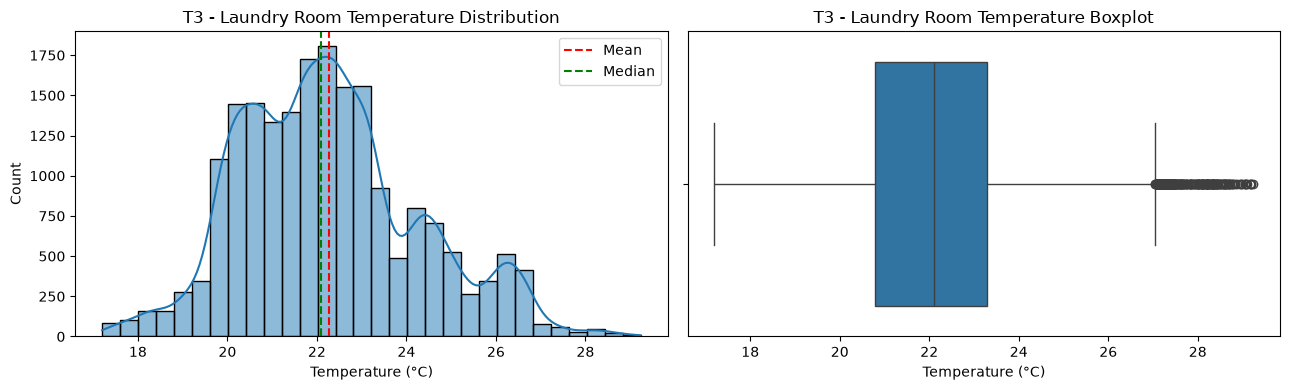

In [81]:

feature = "T3"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T3 - Laundry Room Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("T3 - Laundry Room Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [82]:
    
# T3 outlier detection using IQR

Q1 = df_10min["T3"].quantile(0.25)
Q3 = df_10min["T3"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create flag without changing temperature values
df_10min["T3_outlier"] = (
    (df_10min["T3"] < lower_bound) |
    (df_10min["T3"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total Outliers: {df_10min['T3_outlier'].sum()}")
print(f"Percentage: {df_10min['T3_outlier'].mean() * 100:.2f}%")

# Show outlier observations
display(
    df_10min.loc[
        df_10min["T3_outlier"] == 1,
        ["T3", "Total_Energy", "T3_outlier"]
    ].head(20)
)


Lower Bound: 17.04 °C
Upper Bound: 27.04 °C
Total Outliers: 217
Percentage: 1.10%


,T3,Total_Energy,T3_outlier
14669,27.166667,240,1
14670,27.200000,110,1
14671,27.200000,80,1
14672,27.133333,90,1
14684,27.133333,270,1
14685,27.290000,270,1
14686,27.356667,150,1
14687,27.463333,120,1
14688,27.323333,130,1
14689,27.166667,170,1


In [83]:

feature = "T3"
target = "Total_Energy"

pearson = df_10min[feature].corr(
    df_10min[target], method="pearson"
)

spearman = df_10min[feature].corr(
    df_10min[target], method="spearman"
)

kendall = df_10min[feature].corr(
    df_10min[target], method="kendall"
)

results = pd.DataFrame({
    "Method": ["Pearson", "Spearman", "Kendall"],
    "Correlation": [pearson, spearman, kendall]
})

display(results.round(4))


,Method,Correlation
0,Pearson,0.0761
1,Spearman,0.1894
2,Kendall,0.1327


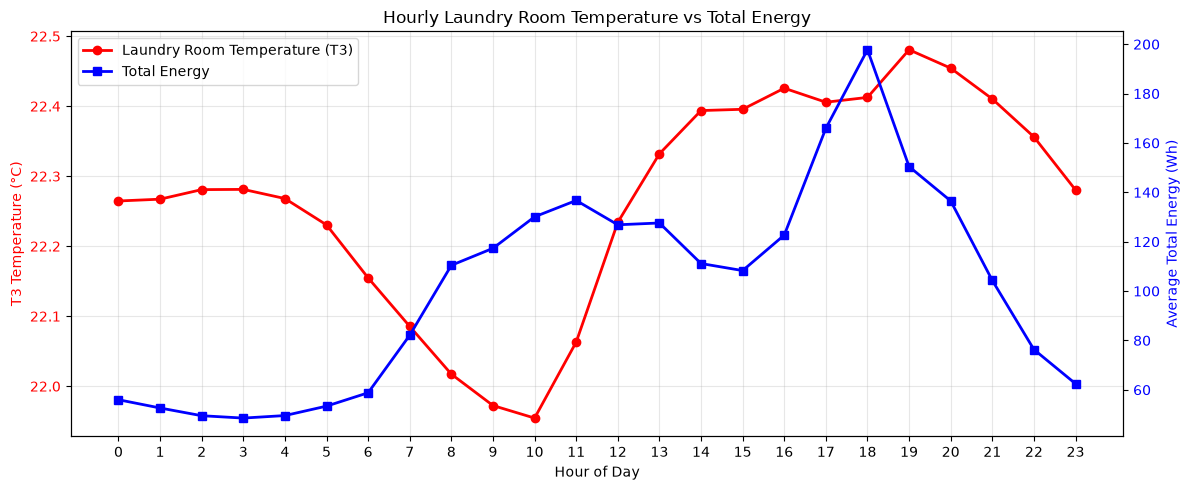

In [84]:

# Create copy for EDA
data = df_10min.copy()

# Extract hour from datetime
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Hour-of-day averages
hourly = data.groupby("Hour")[["T3", "Total_Energy"]].mean()

# Plot
fig, ax1 = plt.subplots(figsize=(12, 5))

# T3 - Laundry room temperature
ax1.plot(
    hourly.index,
    hourly["T3"],
    color="red",
    marker="o",
    linewidth=2,
    label="Laundry Room Temperature (T3)"
)

ax1.set_xlabel("Hour of Day")
ax1.set_ylabel("T3 Temperature (°C)", color="red")
ax1.tick_params(axis="y", labelcolor="red")

# Total Energy
ax2 = ax1.twinx()

ax2.plot(
    hourly.index,
    hourly["Total_Energy"],
    color="blue",
    marker="s",
    linewidth=2,
    label="Total Energy"
)

ax2.set_ylabel("Average Total Energy (Wh)", color="blue")
ax2.tick_params(axis="y", labelcolor="blue")

ax1.set_xticks(range(24))
ax1.grid(alpha=0.3)

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.title("Hourly Laundry Room Temperature vs Total Energy")
plt.tight_layout()
plt.show()


RH_3, Humidity in laundry room area, in %

Five-Number Summary:
min    28.766667
25%    36.900000
50%    38.530000
75%    41.760000
max    50.163333
Name: RH_3, dtype: float64

Additional Statistics:
Mean               : 39.2425
Variance           : 10.5923
Standard Deviation : 3.2546
IQR                : 4.8600
Skewness           : 0.4676


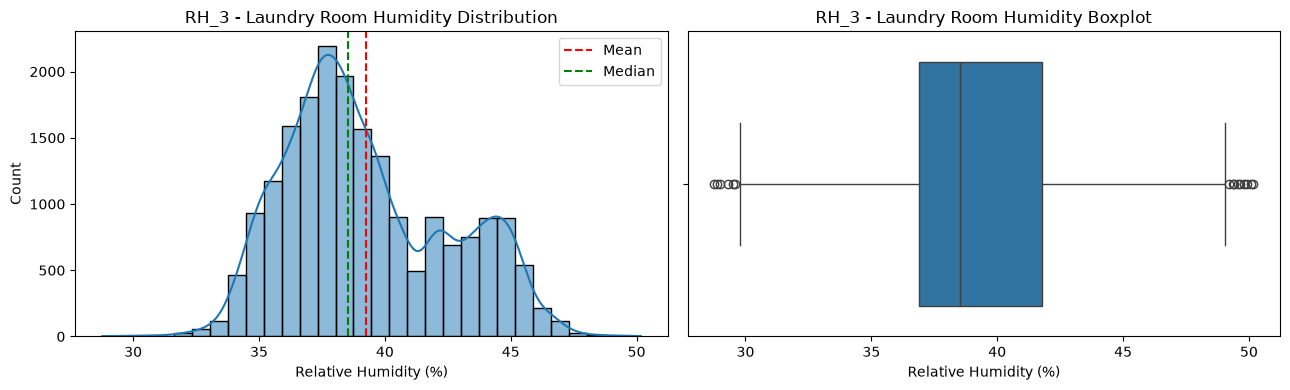

In [85]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

feature = "RH_3"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_3 - Laundry Room Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

# Boxplot
sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("RH_3 - Laundry Room Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


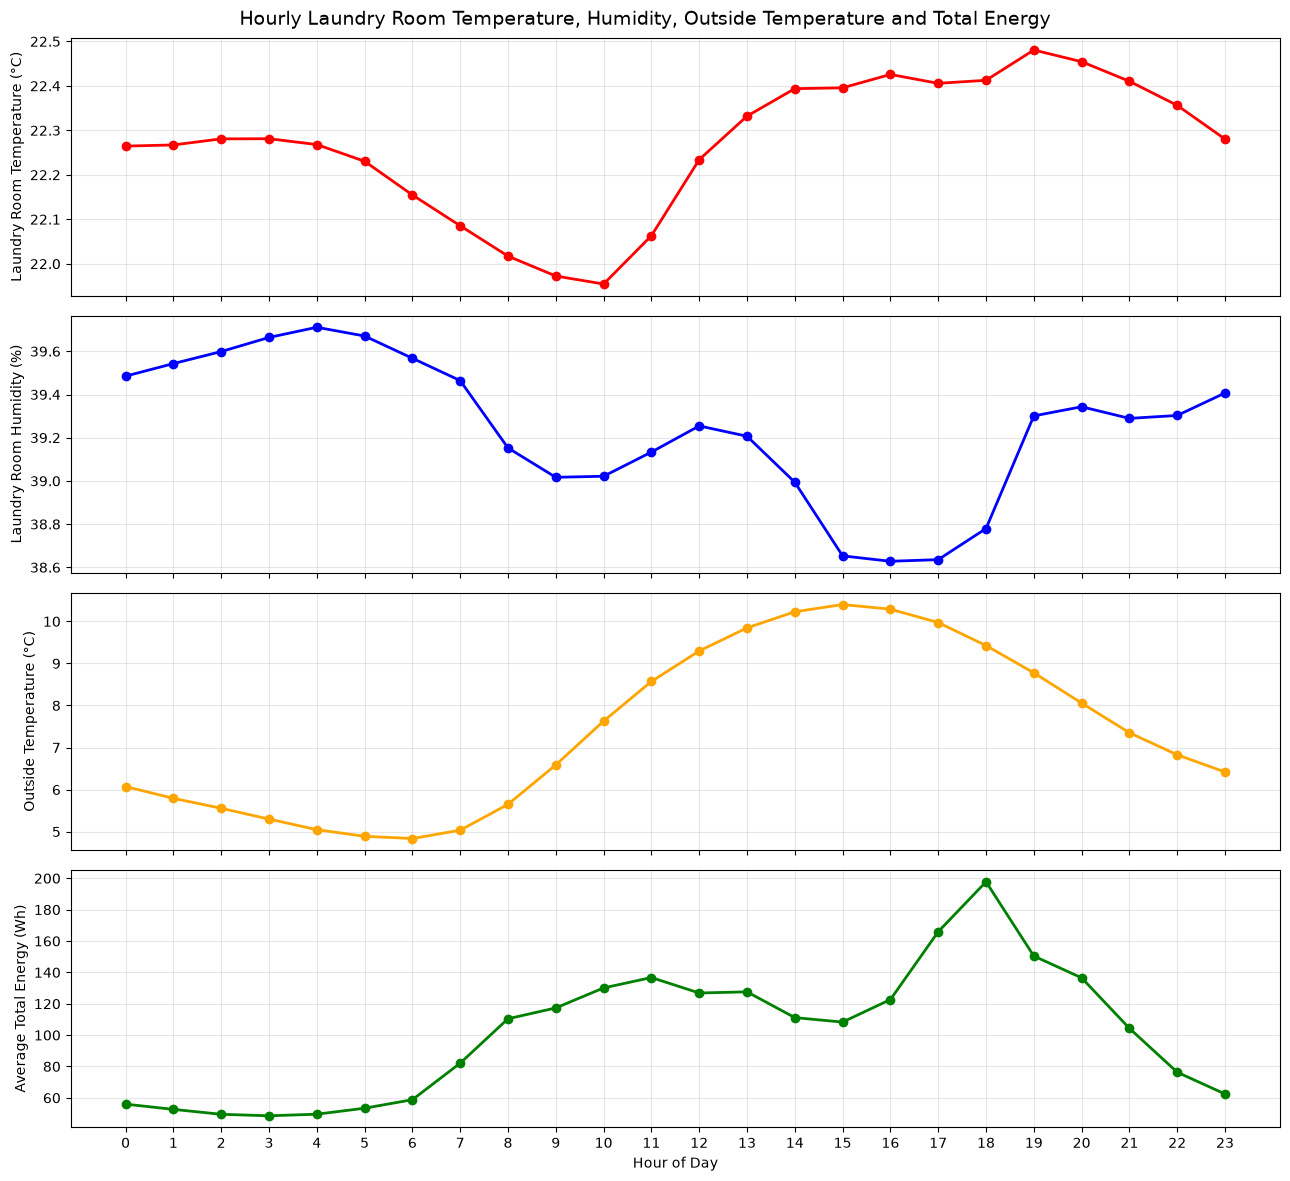

In [86]:

# Copy original 10-minute dataset
data = df_10min.copy()

# Extract hour from date
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Calculate hourly averages across all days
hourly = data.groupby("Hour")[
    ["T3", "RH_3", "T_out", "Total_Energy"]
].mean()

# Create four graphs
fig, axes = plt.subplots(
    4, 1, figsize=(13, 12), sharex=True
)

features = ["T3", "RH_3", "T_out", "Total_Energy"]

labels = [
    "Laundry Room Temperature (°C)",
    "Laundry Room Humidity (%)",
    "Outside Temperature (°C)",
    "Average Total Energy (Wh)"
]

colors = ["red", "blue", "orange", "green"]

for ax, feature, label, color in zip(
    axes, features, labels, colors
):
    ax.plot(
        hourly.index,
        hourly[feature],
        marker="o",
        color=color,
        linewidth=2
    )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Hour of Day")
axes[-1].set_xticks(range(24))

fig.suptitle(
    "Hourly Laundry Room Temperature, Humidity, "
    "Outside Temperature and Total Energy",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [87]:


# Select features
features = ["T3", "RH_3", "Total_Energy"]

# Calculate correlations
pearson = df_10min[features].corr(method="pearson")
spearman = df_10min[features].corr(method="spearman")
kendall = df_10min[features].corr(method="kendall")

# Create comparison table
results = pd.DataFrame({
    "Relationship": [
        "T3 vs Total_Energy",
        "RH_3 vs Total_Energy",
        "T3 vs RH_3"
    ],
    "Pearson": [
        pearson.loc["T3", "Total_Energy"],
        pearson.loc["RH_3", "Total_Energy"],
        pearson.loc["T3", "RH_3"]
    ],
    "Spearman": [
        spearman.loc["T3", "Total_Energy"],
        spearman.loc["RH_3", "Total_Energy"],
        spearman.loc["T3", "RH_3"]
    ],
    "Kendall": [
        kendall.loc["T3", "Total_Energy"],
        kendall.loc["RH_3", "Total_Energy"],
        kendall.loc["T3", "RH_3"]
    ]
})

display(results.round(4))


,Relationship,Pearson,Spearman,Kendall
0,T3 vs Total_Energy,0.0761,0.1894,0.1327
1,RH_3 vs Total_Energy,0.0456,-0.0393,-0.0285
2,T3 vs RH_3,-0.0112,-0.0417,-0.0185


### RH_3 — Laundry Room Humidity: Correlation Analysis

The relationship between laundry room relative humidity (RH_3) and total household energy consumption is extremely weak, with Pearson correlation of 0.0456, Spearman correlation of -0.0393, and Kendall correlation of -0.0285.

Laundry room temperature (T3) also has almost no overall linear association with relative humidity (RH_3), as indicated by Pearson correlation of -0.0112.

These findings suggest that RH_3 alone provides limited information about total household energy consumption through simple linear or monotonic relationships.

However, low correlation does not necessarily imply that RH_3 is irrelevant for machine learning. Nonlinear relationships, temporal dependencies and interactions with other environmental features may still contain useful predictive information.

**Conclusion:** Retain RH_3 for further multivariate analysis and evaluate its predictive contribution during hourly model development.

## T4 (Office Room Temperature)

Five-Number Summary:
min    15.100000
25%    19.530000
50%    20.666667
75%    22.100000
max    26.200000
Name: T4, dtype: float64

Additional Statistics:
Mean               : 20.8553
Variance           : 4.1734
Standard Deviation : 2.0429
IQR                : 2.5700
Skewness           : 0.1704


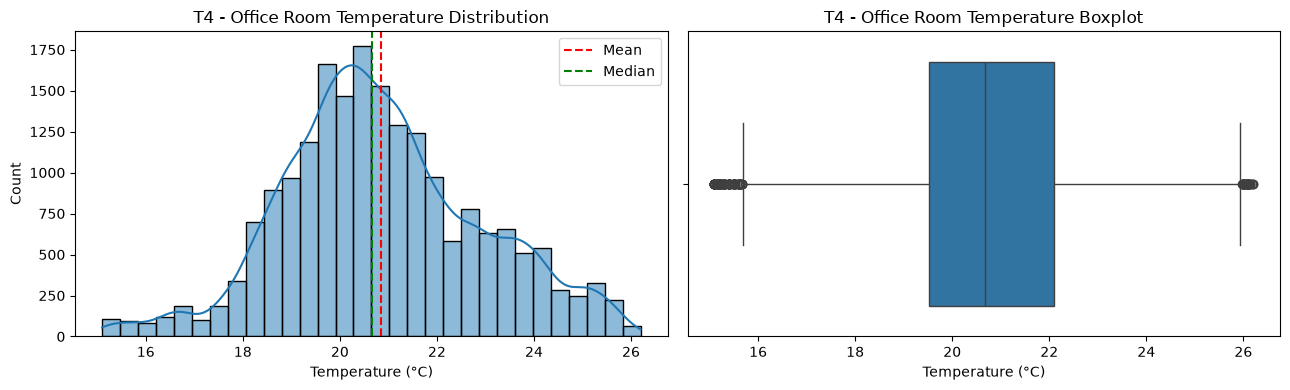

In [88]:

feature = "T4"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional descriptive statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T4 - Office Room Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("T4 - Office Room Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


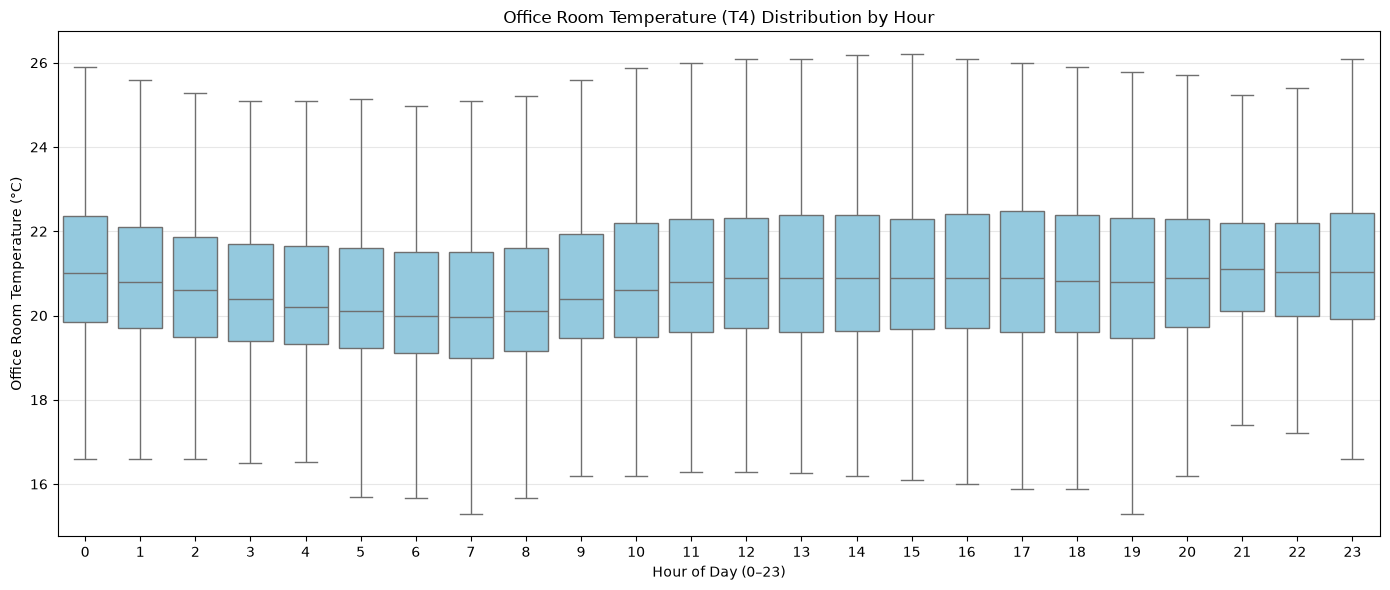

,mean,min,max
Hour,,,
0,21.06,15.50,25.89
1,20.91,15.50,25.70
2,20.76,15.46,25.60
3,20.62,15.39,25.50
4,20.50,15.39,25.39
5,20.40,15.30,25.39
6,20.31,15.30,25.29
7,20.27,15.30,25.10
8,20.39,15.26,25.20


In [89]:

# Create a temporary copy
data = df_10min.copy()

# Extract hour
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Plot T4 temperature distribution by hour
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="T4",
    color="skyblue",
    showfliers=False
)

plt.title("Office Room Temperature (T4) Distribution by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Office Room Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

# Show average T4 temperature by hour
display(
    data.groupby("Hour")["T4"]
    .agg(["mean", "min", "max"])
    .round(2)
)


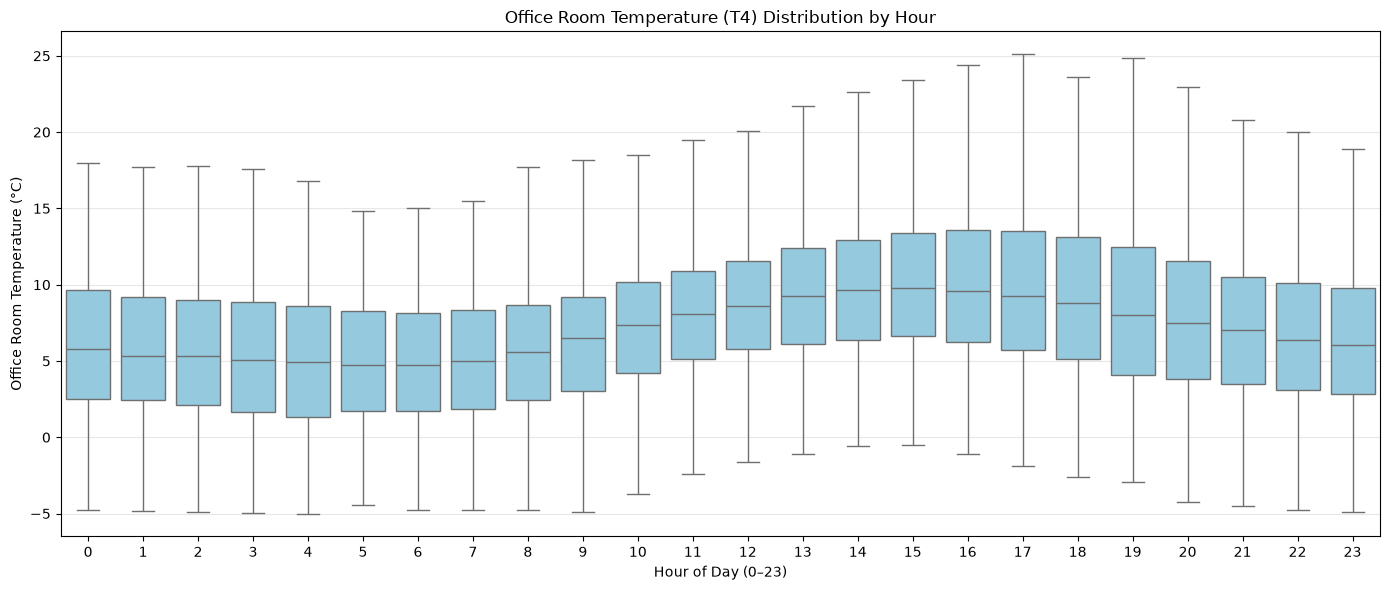

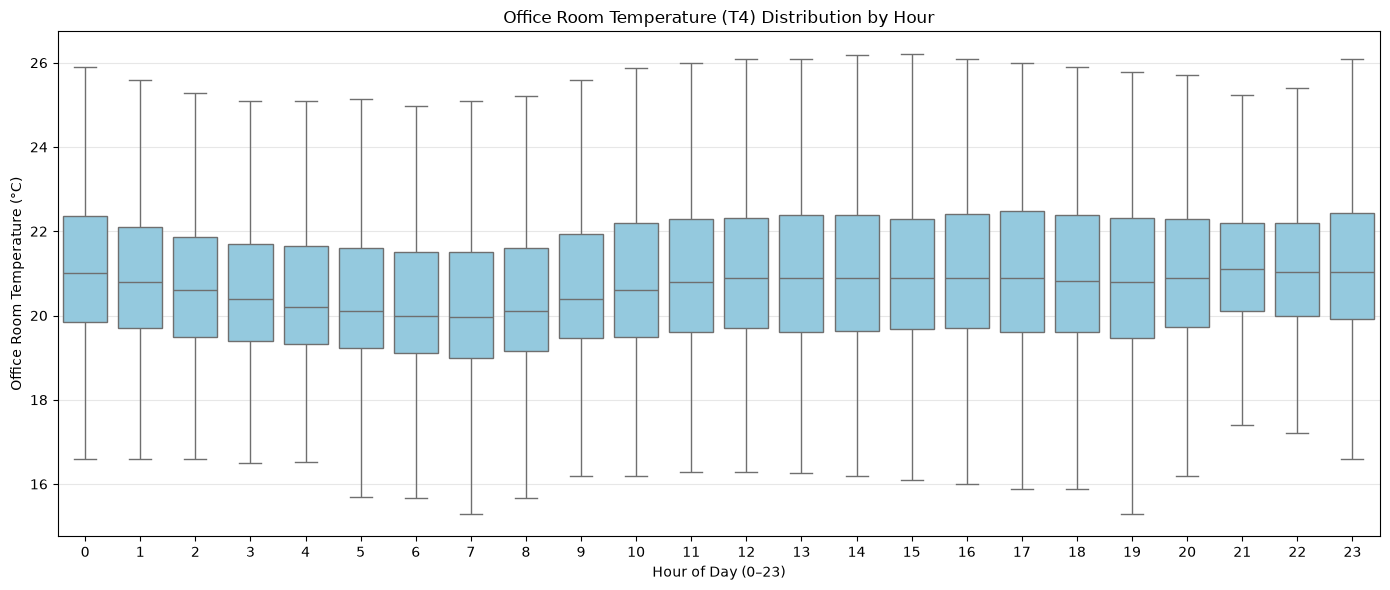

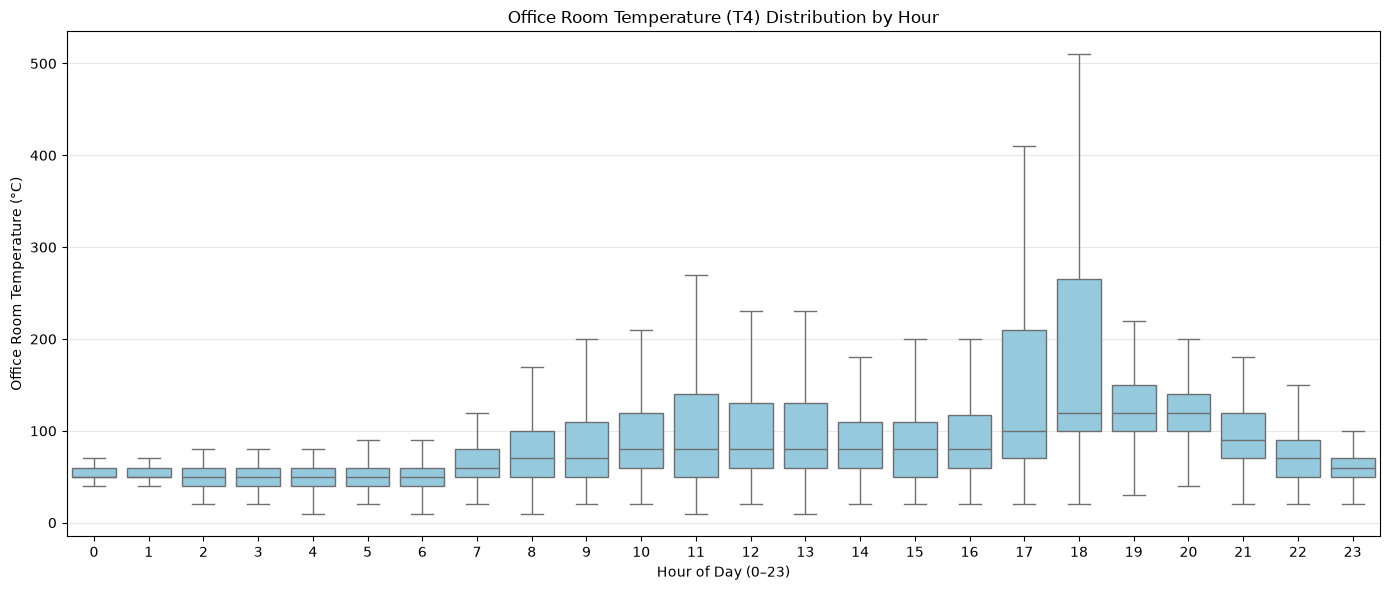

In [90]:

# Create a temporary copy
data = df_10min.copy()

# Extract hour
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Plot T4 temperature distribution by hour
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="T_out",
    color="skyblue",
    showfliers=False
)

plt.title("Office Room Temperature (T4) Distribution by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Office Room Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="T4",
    color="skyblue",
    showfliers=False
)

plt.title("Office Room Temperature (T4) Distribution by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Office Room Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="Total_Energy",
    color="skyblue",
    showfliers=False
)

plt.title("Office Room Temperature (T4) Distribution by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Office Room Temperature (°C)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [91]:

feature = "T4"
target = "Total_Energy"

pearson = df_10min[feature].corr(
    df_10min[target], method="pearson"
)

spearman = df_10min[feature].corr(
    df_10min[target], method="spearman"
)

kendall = df_10min[feature].corr(
    df_10min[target], method="kendall"
)

results = pd.DataFrame({
    "Method": ["Pearson", "Spearman", "Kendall"],
    "Correlation": [pearson, spearman, kendall]
})

display(results.round(4))


,Method,Correlation
0,Pearson,0.0389
1,Spearman,0.2005
2,Kendall,0.1398


RuntimeError: `lowess=True` requires statsmodels, an optional dependency, to be installed.

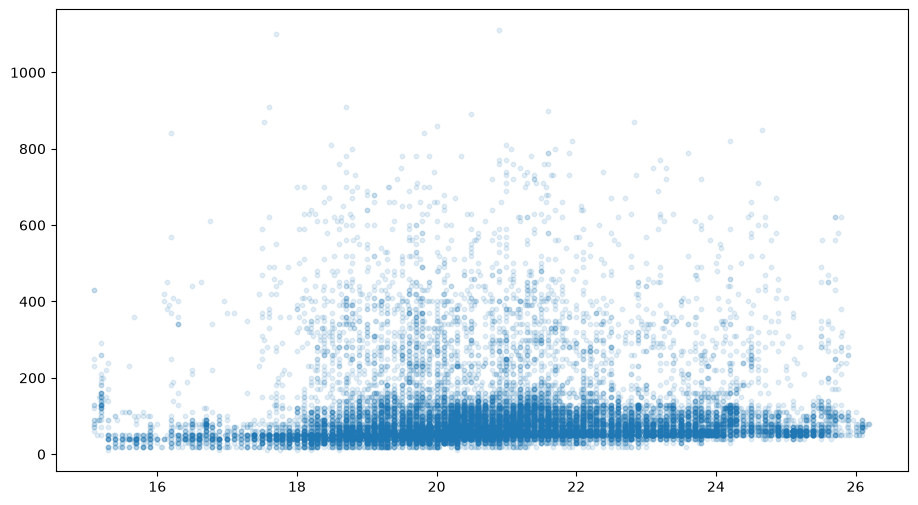

In [92]:


import seaborn as sns

plt.figure(figsize=(11, 6))

sns.regplot(
    data=df_10min,
    x="T4",
    y="Total_Energy",
    lowess=True,
    scatter_kws={"alpha": 0.12, "s": 10},
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("T4 vs Total Energy — Nonlinear Relationship Analysis")
plt.xlabel("Office Room Temperature (°C)")
plt.ylabel("Total Energy (Wh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## RH_4 (Office Room Humidity)

In [ ]:

feature = "RH_4"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_4 - Office Room Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

# Boxplot
sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("RH_4 - Office Room Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

# Copy original 10-minute dataset
data = df_10min.copy()

# Extract hour from date
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Calculate hourly averages across all days
hourly = data.groupby("Hour")[
    ["T4", "RH_4", "T_out", "Total_Energy"]
].mean()

# Create four graphs
fig, axes = plt.subplots(
    4, 1, figsize=(13, 12), sharex=True
)

features = ["T4", "RH_4", "T_out", "Total_Energy"]

labels = [
    "Office Room Temperature (°C)",
    "Office Room Humidity (%)",
    "Outside Temperature (°C)",
    "Average Total Energy (Wh)"
]

colors = ["red", "blue", "orange", "green"]

for ax, feature, label, color in zip(
    axes, features, labels, colors
):
    ax.plot(
        hourly.index,
        hourly[feature],
        marker="o",
        color=color,
        linewidth=2
    )

    ax.set_ylabel(label)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Hour of Day")
axes[-1].set_xticks(range(24))

fig.suptitle(
    "office Room Temperature, Humidity, "
    "Outside Temperature and Total Energy",
    fontsize=14
)

plt.tight_layout()
plt.show()


In [ ]:


# Select features
features = ["T4", "RH_4", "Total_Energy"]

# Calculate correlations
pearson = df_10min[features].corr(method="pearson")
spearman = df_10min[features].corr(method="spearman")
kendall = df_10min[features].corr(method="kendall")

# Create comparison table
results = pd.DataFrame({
    "Relationship": [
        "T4 vs Total_Energy",
        "RH_4 vs Total_Energy",
        "T4 vs RH_4"
    ],
    "Pearson": [
        pearson.loc["T4", "Total_Energy"],
        pearson.loc["RH_4", "Total_Energy"],
        pearson.loc["T4", "RH_4"]
    ],
    "Spearman": [
        spearman.loc["T4", "Total_Energy"],
        spearman.loc["RH_4", "Total_Energy"],
        spearman.loc["T4", "RH_4"]
    ],
    "Kendall": [
        kendall.loc["T4", "Total_Energy"],
        kendall.loc["RH_4", "Total_Energy"],
        kendall.loc["T4", "RH_4"]
    ]
})

display(results.round(4))


In [ ]:

# RH_4 vs Total_Energy with nonlinear trend
plt.figure(figsize=(11, 6))

sns.regplot(
    data=df_10min,
    x="RH_4",
    y="Total_Energy",
    lowess=True,
    scatter_kws={
        "alpha": 0.12,
        "s": 10
    },
    line_kws={
        "color": "red",
        "linewidth": 2
    }
)

plt.title("RH_4 vs Total Energy — Nonlinear Pattern Analysis")
plt.xlabel("Office Room Relative Humidity (%)")
plt.ylabel("Total Energy (Wh)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## T5, Temperature in bathroom, in Celsius

In [ ]:

feature = "T5"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T4 - Temperature in bathroom, in Celsius Distribution")
axes[0].set_xlabel("Celsisus")
axes[0].legend()

# Boxplot
sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("T4 Temperature in bathroom Boxplot")
axes[1].set_xlabel("Celsisus")

plt.tight_layout()
plt.show()


In [ ]:

# T5 - Bathroom Temperature Outlier Detection

Q1 = df_10min["T5"].quantile(0.25)
Q3 = df_10min["T5"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers
df_10min["T5_outlier"] = (
    (df_10min["T5"] < lower_bound) |
    (df_10min["T5"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total Outliers: {df_10min['T5_outlier'].sum()}")
print(f"Outlier Percentage: {df_10min['T5_outlier'].mean()*100:.2f}%")

display(
    df_10min.loc[
        df_10min["T5_outlier"] == 1,
        ["date", "T5", "Total_Energy", "T5_outlier"]
    ].head(20)
)


In [ ]:

# Investigate May 8, 2016
data = df_10min.copy()
data["date"] = pd.to_datetime(data["date"])

day_data = data.loc[
    data["date"].dt.date == pd.Timestamp("2016-05-08").date()
].sort_values("date")

# Plot bathroom and outside temperatures
plt.figure(figsize=(12, 5))

plt.plot(
    day_data["date"],
    day_data["T5"],
    label="Bathroom Temperature (T5)",
    color="red"
)

plt.plot(
    day_data["date"],
    day_data["T_out"],
    label="Outside Temperature",
    color="blue"
)

plt.axhline(
    y=24.13,
    color="orange",
    linestyle="--",
    label="T5 Upper IQR Bound"
)

plt.title("Bathroom vs Outside Temperature — May 8, 2016")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

features = ["T5", "T_out", "Total_Energy"]

pearson = df_10min[features].corr(method="pearson")
spearman = df_10min[features].corr(method="spearman")
kendall = df_10min[features].corr(method="kendall")

pairs = [
    ("T5", "Total_Energy"),
    ("T5", "T_out"),
    ("T_out", "Total_Energy")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": pearson.loc[x, y],
        "Spearman": spearman.loc[x, y],
        "Kendall": kendall.loc[x, y]
    }
    for x, y in pairs
])

display(results.round(4))


## RH_5, Humidity in bathroom, in %

In [ ]:

feature = "RH_5"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_5 - Bathroom Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

sns.boxplot(x=df_10min[feature], ax=axes[1])
axes[1].set_title("RH_5 - Bathroom Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

data = df_10min.copy()
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# RH_5 upper IQR boundary
Q1 = data["RH_5"].quantile(0.25)
Q3 = data["RH_5"].quantile(0.75)
upper_bound = Q3 + 1.5 * (Q3 - Q1)

# Flag high humidity
data["High_RH5"] = data["RH_5"] > upper_bound

# Percentage of high-humidity readings by hour
hourly_high = (
    data.groupby("Hour")["High_RH5"].mean() * 100
)

plt.figure(figsize=(12, 5))

plt.bar(
    hourly_high.index,
    hourly_high.values,
    color="steelblue"
)

plt.title("High Bathroom Humidity Events by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("High RH_5 Observations (%)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Upper RH_5 Bound: {upper_bound:.2f}%")
print(f"Total High Humidity Readings: {data['High_RH5'].sum()}")

display(hourly_high.round(2))


In [ ]:

# Calculate RH_5 IQR threshold
Q1 = df_10min["RH_5"].quantile(0.25)
Q3 = df_10min["RH_5"].quantile(0.75)

upper_bound = Q3 + 1.5 * (Q3 - Q1)

# Classify high and normal humidity
df_10min["RH5_High"] = (
    df_10min["RH_5"] > upper_bound
).astype(int)

# Compare energy consumption between groups
energy_comparison = (
    df_10min.groupby("RH5_High")["Total_Energy"]
    .agg(["count", "mean", "median", "std"])
)

energy_comparison.index = [
    "Normal Humidity",
    "High Humidity"
]

display(energy_comparison.round(2))


In [ ]:


# Prepare data
data = df_10min.copy()
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Hourly descriptive statistics
hourly_stats = data.groupby("Hour")["RH_5"].agg(
    ["mean", "median", "std", "min", "max"]
)

display(hourly_stats.round(2))

# Hourly distribution boxplot
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="RH_5",
    color="skyblue",
    showfliers=True,
    fliersize=2
)

plt.axhline(
    y=66.06,
    color="red",
    linestyle="--",
    label="Global RH_5 Upper IQR Bound (66.06%)"
)

plt.title("Bathroom Humidity (RH_5) Distribution by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Relative Humidity (%)")
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


In [ ]:

features = ["RH_5", "T5", "Total_Energy"]

methods = ["pearson", "spearman", "kendall"]

pairs = [
    ("RH_5", "Total_Energy"),
    ("RH_5", "T5")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        **{
            method.capitalize():
            df_10min[x].corr(df_10min[y], method=method)
            for method in methods
        }
    }
    for x, y in pairs
])

display(results.round(4))


## T6, Temperature outside the building (north side), in Celsius

In [ ]:

feature = "T6"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T6 - North Side Outside Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(x=df_10min[feature], ax=axes[1])
axes[1].set_title("T6 - North Side Outside Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [ ]:
# Select features
features = ["T6", "T_out", "Total_Energy"]

# Correlation methods
methods = ["pearson", "spearman", "kendall"]

# Relationships to investigate
pairs = [
    ("T6", "T_out"),
    ("T6", "Total_Energy"),
    ("T_out", "Total_Energy")
]

# Calculate correlation comparison
results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        **{
            method.capitalize():
            df_10min[x].corr(
                df_10min[y], method=method
            )
            for method in methods
        }
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

# T6 Outlier Detection using IQR

Q1 = df_10min["T6"].quantile(0.25)
Q3 = df_10min["T6"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers
df_10min["T6_outlier"] = (
    (df_10min["T6"] < lower_bound) |
    (df_10min["T6"] > upper_bound)
).astype(int)

# Count outliers
print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total Outliers: {df_10min['T6_outlier'].sum()}")
print(f"Outlier Percentage: {df_10min['T6_outlier'].mean() * 100:.2f}%")

# Display flagged observations
display(
    df_10min.loc[
        df_10min["T6_outlier"] == 1,
        ["date", "T6", "T_out", "Total_Energy", "T6_outlier"]
    ].head(20)
)


In [ ]:



# Energy upper IQR bound
Q1_energy = df_10min["Total_Energy"].quantile(0.25)
Q3_energy = df_10min["Total_Energy"].quantile(0.75)

energy_upper = Q3_energy + 1.5 * (Q3_energy - Q1_energy)

# Flag high energy consumption
df_10min["High_Energy"] = (
    df_10min["Total_Energy"] > energy_upper
).astype(int)

# Find observations where both conditions occur
T6_high_energy = df_10min[
    (df_10min["T6_outlier"] == 1) &
    (df_10min["High_Energy"] == 1)
]

# Summary
print("Energy Upper Bound:", energy_upper)
print("Total T6 Outliers:", df_10min["T6_outlier"].sum())
print("Total High Energy Observations:", df_10min["High_Energy"].sum())
print("T6 Outliers with High Energy:", len(T6_high_energy))

# Percentage of T6 outliers with high energy
t6_count = df_10min["T6_outlier"].sum()

if t6_count > 0:
    print(
        "Percentage:",
        round(len(T6_high_energy) / t6_count * 100, 2),
        "%"
    )

# Display matching observations
display(
    T6_high_energy[
        ["date", "T6", "T_out", "Total_Energy"]
    ].head(20)
)


In [ ]:

# Prepare datetime
df_10min["date"] = pd.to_datetime(df_10min["date"])

# Select T6 outlier observations
t6_outliers = df_10min.loc[
    df_10min["T6_outlier"] == 1,
    ["date", "T6", "T_out", "Total_Energy"]
].copy()

# Extract date and hour
t6_outliers["Day"] = t6_outliers["date"].dt.date
t6_outliers["Hour"] = t6_outliers["date"].dt.hour

# Sort by timestamp
t6_outliers = t6_outliers.sort_values("date")

print("Total T6 Outliers:", len(t6_outliers))

# Display dates and timestamps
display(t6_outliers.head(30))

# Count outliers by hour of day
hourly_count = (
    t6_outliers.groupby("Hour")
    .size()
    .reindex(range(24), fill_value=0)
)

print("\nT6 Outlier Count by Hour:")
display(hourly_count.to_frame("Outlier_Count"))


## RH_6, Humidity outside the building (north side), in %

In [ ]:

feature = "RH_6"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_6 - North Side Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("RH_6 - North Side Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

data = df_10min.copy()
data["date"] = pd.to_datetime(data["date"])
data["Hour"] = data["date"].dt.hour

# Hourly distribution of RH_6
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="RH_6",
    color="skyblue",
    showfliers=False
)

plt.title("RH_6 - North Side Humidity Distribution by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Relative Humidity (%)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Hourly summary
display(
    data.groupby("Hour")["RH_6"]
    .agg(["mean", "median", "std", "min", "max"])
    .round(2)
)


In [ ]:

# Define relationships
pairs = [
    ("RH_6", "T6"),
    ("RH_6", "T_out"),
    ("RH_6", "Total_Energy"),
    ("RH_6", "RH_out")
]

# Calculate correlations
results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

plt.figure(figsize=(11, 6))

sns.regplot(
    data=df_10min,
    x="RH_6",
    y="Total_Energy",
    lowess=True,
    scatter_kws={"alpha": 0.1, "s": 8},
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("RH_6 vs Total Energy — Nonlinear Relationship Analysis")
plt.xlabel("North-Side Relative Humidity (%)")
plt.ylabel("Total Energy (Wh)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## T7, Temperature in ironing room , in Celsius

In [ ]:

feature = "T7"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T7 - Ironing Room Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("T7 - Ironing Room Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [ ]:

# T7 outlier detection using IQR

Q1 = df_10min["T7"].quantile(0.25)
Q3 = df_10min["T7"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create binary outlier flag
df_10min["T7_outlier"] = (
    (df_10min["T7"] < lower_bound) |
    (df_10min["T7"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total T7 Outliers: {df_10min['T7_outlier'].sum()}")
print(f"Outlier Percentage: {df_10min['T7_outlier'].mean() * 100:.4f}%")

display(
    df_10min.loc[
        df_10min["T7_outlier"] == 1,
        ["date", "T7", "Total_Energy", "T7_outlier"]
    ]
)


In [ ]:

pairs = [
    ("T7", "Total_Energy"),
    ("T7", "T_out"),
    ("T7", "T6")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


## RH_7, Humidity in ironing room, in %

In [ ]:

feature = "RH_7"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional descriptive statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_7 - Ironing Room Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

# Boxplot
sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("RH_7 - Ironing Room Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

pairs = [
    ("RH_7", "T_out"),
    ("RH_7", "T7"),
    ("RH_7", "RH_out"),
    ("RH_7", "Total_Energy")
]

methods = ["pearson", "spearman", "kendall"]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        **{
            method.capitalize(): df_10min[x].corr(
                df_10min[y], method=method
            )
            for method in methods
        }
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

# Calculate RH_7 outlier threshold
Q1 = df_10min["RH_7"].quantile(0.25)
Q3 = df_10min["RH_7"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Flag RH_7 outliers
df_10min["RH7_outlier"] = (
    (df_10min["RH_7"] < lower) |
    (df_10min["RH_7"] > upper)
).astype(int)

# Summary
print(f"Lower Bound: {lower:.2f}%")
print(f"Upper Bound: {upper:.2f}%")
print(f"Total RH_7 Outliers: {df_10min['RH7_outlier'].sum()}")

# Compare normal vs outlier conditions
comparison = df_10min.groupby("RH7_outlier")[
    ["RH_7", "T7", "T_out", "RH_out", "Total_Energy"]
].mean()

display(comparison.round(2))


## T8, Temperature in teenager room 2, in Celsius

In [ ]:

feature = "T8"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Plot histogram and boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T8 - Teenager Room Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("T8 - Teenager Room Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [ ]:

# Calculate T8 IQR boundaries
Q1 = df_10min["T8"].quantile(0.25)
Q3 = df_10min["T8"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag T8 outliers
df_10min["T8_outlier"] = (
    (df_10min["T8"] < lower_bound) |
    (df_10min["T8"] > upper_bound)
).astype(int)

# Compare normal and outlier observations
comparison = df_10min.groupby("T8_outlier")[
    ["T8", "T_out", "T6", "Total_Energy"]
].agg(["mean", "median"])

print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total T8 Outliers: {df_10min['T8_outlier'].sum()}")

display(comparison.round(2))


In [ ]:

# T8 outlier flag using IQR

Q1 = df_10min["T8"].quantile(0.25)
Q3 = df_10min["T8"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create binary flag
df_10min["T8_outlier_low"] = (
    (df_10min["T8"] < lower_bound) |
    (df_10min["T8"] > upper_bound)
).astype(int)

# Verify
print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")
print(f"Total T8 Outliers: {df_10min['T8_outlier_low'].sum()}")
print(f"Outlier Percentage: {df_10min['T8_outlier_low'].mean() * 100:.2f}%")

# Display flagged rows
display(
    df_10min.loc[
        df_10min["T8_outlier_low"] == 1,
        ["date", "T8", "T_out", "Total_Energy", "T8_outlier_low"]
    ]
)


In [ ]:

# Calculate Total_Energy IQR boundaries

Q1 = df_10min["Total_Energy"].quantile(0.25)
Q3 = df_10min["Total_Energy"].quantile(0.75)

IQR = Q3 - Q1

energy_lower = Q1 - 1.5 * IQR
energy_upper = Q3 + 1.5 * IQR

# Flag energy outliers
df_10min["Energy_IQR_Outlier"] = (
    (df_10min["Total_Energy"] < energy_lower) |
    (df_10min["Total_Energy"] > energy_upper)
).astype(int)

# Compare T8 and energy flags
comparison = pd.crosstab(
    df_10min["T8_outlier_low"],
    df_10min["Energy_IQR_Outlier"]
)

print(f"Energy Lower Bound: {energy_lower:.2f} Wh")
print(f"Energy Upper Bound: {energy_upper:.2f} Wh")

display(comparison)


In [ ]:

# Investigate T8 temperature and energy outliers together

both_outliers = df_10min.loc[
    (df_10min["T8_outlier_low"] == 1) &
    (df_10min["Energy_IQR_Outlier"] == 1),
    [
        "date",
        "T8",
        "T_out",
        "Appliances",
        "lights",
        "Total_Energy"
    ]
].sort_values("date")

print("T8 and Energy Overlapping Outliers:", len(both_outliers))

display(both_outliers)


In [ ]:


pairs = [
    ("T8", "Total_Energy"),
    ("T8", "T_out"),
    ("T_out", "Total_Energy")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


## RH_8, Humidity in teenager room 2, in %

In [ ]:

feature = "RH_8"

stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("RH_8 - Teenager Room Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

sns.boxplot(x=df_10min[feature], ax=axes[1])

axes[1].set_title("RH_8 - Teenager Room Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

# T8 lower outlier boundary
T8_Q1 = df_10min["T8"].quantile(0.25)
T8_Q3 = df_10min["T8"].quantile(0.75)

T8_lower = T8_Q1 - 1.5 * (T8_Q3 - T8_Q1)

# RH_8 upper outlier boundary
RH8_Q1 = df_10min["RH_8"].quantile(0.25)
RH8_Q3 = df_10min["RH_8"].quantile(0.75)

RH8_upper = RH8_Q3 + 1.5 * (RH8_Q3 - RH8_Q1)

# Create flags
df_10min["T8_outlier_low"] = (
    df_10min["T8"] < T8_lower
).astype(int)

df_10min["RH8_outlier_high"] = (
    df_10min["RH_8"] > RH8_upper
).astype(int)

# Compare outlier flags
comparison = pd.crosstab(
    df_10min["T8_outlier_low"],
    df_10min["RH8_outlier_high"]
)

print(f"T8 Lower Bound: {T8_lower:.2f} °C")
print(f"RH_8 Upper Bound: {RH8_upper:.2f}%")

print("Low T8 Outliers:", df_10min["T8_outlier_low"].sum())
print("High RH_8 Outliers:", df_10min["RH8_outlier_high"].sum())

display(comparison)


In [ ]:

# Copy data
data = df_10min.copy()

# Make sure date is datetime
data["date"] = pd.to_datetime(data["date"])

# Extract hour
data["Hour"] = data["date"].dt.hour

# Hourly summary table
hourly_rh8 = data.groupby("Hour")["RH_8"].agg(
    ["mean", "median", "std", "min", "max"]
)

display(hourly_rh8.round(2))

# Boxplot of RH_8 by hour
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=data,
    x="Hour",
    y="RH_8",
    color="skyblue",
    showfliers=True,
    fliersize=2
)

plt.title("Teenager Room Humidity (RH_8) Distribution by Hour")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Relative Humidity (%)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## T9, Temperature in parents room, in Celsius

In [ ]:

feature = "T9"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

# Additional descriptive statistics
print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("T9 - Parents' Room Temperature Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

# Boxplot
sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("T9 - Parents' Room Temperature Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [ ]:

pairs = [
    ("T9", "Total_Energy"),
    ("T9", "T_out"),
    ("T9", "T8")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_10min,
    x="T8",
    y="T9",
    scatter_kws={"alpha": 0.15, "s": 10},
    line_kws={"color": "red"}
)

plt.title("T8 vs T9 — Teenager and Parents' Room Temperatures")
plt.xlabel("T8 - Teenager Room Temperature (°C)")
plt.ylabel("T9 - Parents' Room Temperature (°C)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## RH_9, Humidity in parents room, in %

In [ ]:

feature = "RH_9"

stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(df_10min[feature].mean(),
                color="red", linestyle="--", label="Mean")
axes[0].axvline(df_10min[feature].median(),
                color="green", linestyle="--", label="Median")

axes[0].set_title("RH_9 - Parents' Room Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

sns.boxplot(x=df_10min[feature], ax=axes[1])
axes[1].set_title("RH_9 - Parents' Room Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# RH_9 outlier detection
Q1 = df_10min["RH_9"].quantile(0.25)
Q3 = df_10min["RH_9"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create separate flags
df_10min["RH9_outlier_low"] = (
    df_10min["RH_9"] < lower_bound
).astype(int)

df_10min["RH9_outlier_high"] = (
    df_10min["RH_9"] > upper_bound
).astype(int)

# Summary
print(f"Lower Bound: {lower_bound:.2f}%")
print(f"Upper Bound: {upper_bound:.2f}%")
print("Low Outliers:", df_10min["RH9_outlier_low"].sum())
print("High Outliers:", df_10min["RH9_outlier_high"].sum())

# Display flagged observations
outliers = df_10min[
    (df_10min["RH9_outlier_low"] == 1) |
    (df_10min["RH9_outlier_high"] == 1)
]

display(
    outliers[
        ["date", "RH_9", "T9", "T_out", "Total_Energy"]
    ].head(20)
)


In [ ]:

# RH_9 Outlier Detection using IQR

Q1 = df_10min["RH_9"].quantile(0.25)
Q3 = df_10min["RH_9"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create outlier flag
df_10min["RH9_outlier"] = (
    (df_10min["RH_9"] < lower_bound) |
    (df_10min["RH_9"] > upper_bound)
).astype(int)

# Verify
print(f"Lower Bound: {lower_bound:.2f}%")
print(f"Upper Bound: {upper_bound:.2f}%")
print(f"Total RH_9 Outliers: {df_10min['RH9_outlier'].sum()}")
print(f"Outlier Percentage: {df_10min['RH9_outlier'].mean() * 100:.2f}%")

# Display flagged observations
display(
    df_10min.loc[
        df_10min["RH9_outlier"] == 1,
        ["date", "RH_9", "T9", "T_out", "Total_Energy", "RH9_outlier"]
    ]
)


In [ ]:

import pandas as pd

pairs = [
    ("RH_9", "T9"),
    ("RH_9", "RH_out"),
    ("RH_9", "T_out"),
    ("RH_9", "Total_Energy")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

import pandas as pd

# Calculate IQR bounds for RH_9
Q1 = df_10min["RH_9"].quantile(0.25)
Q3 = df_10min["RH_9"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Classify humidity observations
df_10min["RH9_Status"] = "Normal"

df_10min.loc[
    df_10min["RH_9"] < lower_bound,
    "RH9_Status"
] = "Low Outlier"

df_10min.loc[
    df_10min["RH_9"] > upper_bound,
    "RH9_Status"
] = "High Outlier"

# Compare energy consumption by humidity status
comparison = (
    df_10min.groupby("RH9_Status")["Total_Energy"]
    .agg(["count", "mean", "median", "std", "min", "max"])
)

display(comparison.round(2))

# Compare high energy observations (>175 Wh)
df_10min["High_Energy"] = (
    df_10min["Total_Energy"] > 175
).astype(int)

energy_overlap = (
    df_10min.groupby("RH9_Status")["High_Energy"]
    .agg(["sum", "mean"])
)

energy_overlap.columns = [
    "High_Energy_Count",
    "High_Energy_Rate"
]

energy_overlap["High_Energy_Rate"] *= 100

display(energy_overlap.round(2))


In [ ]:

# Investigate low RH_9 outliers

low_rh9 = df_10min.loc[
    df_10min["RH9_Status"] == "Low Outlier",
    [
        "date", "RH_9", "T9",
        "T_out", "RH_out",
        "Total_Energy"
    ]
].copy()

low_rh9["date"] = pd.to_datetime(low_rh9["date"])
low_rh9["Hour"] = low_rh9["date"].dt.hour

print("Total Low RH_9 Outliers:", len(low_rh9))

display(
    low_rh9.sort_values("date")
)


## To, Temperature outside (from Chievres weather station), in Celsius

# T_out (Outside Temperature)

In [ ]:

feature = "T_out"

# Five-number summary
stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

# Distribution graphs
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Outside Temperature (T_out) Distribution")
axes[0].set_xlabel("Temperature (°C)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("Outside Temperature (T_out) Boxplot")
axes[1].set_xlabel("Temperature (°C)")

plt.tight_layout()
plt.show()


In [ ]:

# IQR outlier flags for outside temperature

Q1 = df_10min["T_out"].quantile(0.25)
Q3 = df_10min["T_out"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_10min["T_out_outlier"] = (
    (df_10min["T_out"] < lower_bound) |
    (df_10min["T_out"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f} °C")
print(f"Upper Bound: {upper_bound:.2f} °C")

print("Low Outliers:",
      (df_10min["T_out"] < lower_bound).sum())

print("High Outliers:",
      (df_10min["T_out"] > upper_bound).sum())

print("Total Outliers:",
      df_10min["T_out_outlier"].sum())

display(
    df_10min.loc[
        df_10min["T_out_outlier"] == 1,
        ["date", "T_out", "T6", "Total_Energy", "T_out_outlier"]
    ].head(20)
)


In [ ]:

# Calculate T_out upper IQR boundary
Q1 = df_10min["T_out"].quantile(0.25)
Q3 = df_10min["T_out"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# Flag high outside temperature
df_10min["High_T_out"] = (
    df_10min["T_out"] > upper_bound
).astype(int)

# Flag high total energy consumption
df_10min["High_Energy"] = (
    df_10min["Total_Energy"] > 175
).astype(int)

# Compare the two flags
overlap = pd.crosstab(
    df_10min["High_T_out"],
    df_10min["High_Energy"]
)

display(overlap)

# Calculate percentage of high energy within each group
comparison = (
    df_10min.groupby("High_T_out")["High_Energy"]
    .agg(["count", "sum", "mean"])
)

comparison.columns = [
    "Total_Observations",
    "High_Energy_Count",
    "High_Energy_Rate"
]

comparison["High_Energy_Rate"] *= 100

display(comparison.round(2))

# Show observations where both are high
both_high = df_10min[
    (df_10min["High_T_out"] == 1) &
    (df_10min["High_Energy"] == 1)
]

print("Both High Outliers:", len(both_high))

display(
    both_high[
        ["date", "T_out", "T6", "Total_Energy"]
    ].head(20)
)


## RH_out (Outside Relative Humidity)

In [ ]:

feature = "RH_out"

stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Outside Relative Humidity Distribution")
axes[0].set_xlabel("Relative Humidity (%)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("Outside Relative Humidity Boxplot")
axes[1].set_xlabel("Relative Humidity (%)")

plt.tight_layout()
plt.show()


In [ ]:

# RH_out IQR outlier detection

Q1 = df_10min["RH_out"].quantile(0.25)
Q3 = df_10min["RH_out"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag outliers
df_10min["RH_out_outlier"] = (
    (df_10min["RH_out"] < lower_bound) |
    (df_10min["RH_out"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f}%")
print(f"Upper Bound: {upper_bound:.2f}%")

print("Low Outliers:",
      (df_10min["RH_out"] < lower_bound).sum())

print("High Outliers:",
      (df_10min["RH_out"] > upper_bound).sum())

print("Total Outliers:",
      df_10min["RH_out_outlier"].sum())

display(
    df_10min.loc[
        df_10min["RH_out_outlier"] == 1,
        ["date", "RH_out", "T_out", "Total_Energy", "RH_out_outlier"]
    ].head(20)
)


In [ ]:

# Flag high energy observations
df_10min["High_Energy"] = (
    df_10min["Total_Energy"] > 175
).astype(int)

# Compare low RH_out outliers with high energy
comparison = (
    df_10min.groupby("RH_out_outlier")["High_Energy"]
    .agg(["count", "sum", "mean"])
)

comparison.columns = [
    "Total_Observations",
    "High_Energy_Count",
    "High_Energy_Rate"
]

comparison["High_Energy_Rate"] *= 100

display(comparison.round(2))

# Cross-tabulation
display(
    pd.crosstab(
        df_10min["RH_out_outlier"],
        df_10min["High_Energy"]
    )
)


In [ ]:

import pandas as pd

pairs = [
    ("RH_out", "T_out"),
    ("RH_out", "Total_Energy"),
    ("T_out", "Total_Energy")
]

results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

plt.figure(figsize=(9, 6))

sns.regplot(
    data=df_10min,
    x="T_out",
    y="RH_out",
    scatter_kws={"alpha": 0.12, "s": 10},
    line_kws={"color": "red"}
)

plt.title("Outdoor Temperature vs Relative Humidity")
plt.xlabel("Outside Temperature (°C)")
plt.ylabel("Outside Relative Humidity (%)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Press_mm_hg (Atmospheric Pressure)

In [ ]:

feature = "Press_mm_hg"

stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Atmospheric Pressure Distribution")
axes[0].set_xlabel("Pressure (mmHg)")
axes[0].legend()

sns.boxplot(x=df_10min[feature], ax=axes[1])

axes[1].set_title("Atmospheric Pressure Boxplot")
axes[1].set_xlabel("Pressure (mmHg)")

plt.tight_layout()
plt.show()


In [ ]:

# Atmospheric pressure IQR outlier detection

Q1 = df_10min["Press_mm_hg"].quantile(0.25)
Q3 = df_10min["Press_mm_hg"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create outlier flag
df_10min["Press_outlier"] = (
    (df_10min["Press_mm_hg"] < lower_bound) |
    (df_10min["Press_mm_hg"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f} mmHg")
print(f"Upper Bound: {upper_bound:.2f} mmHg")

print("Low Outliers:",
      (df_10min["Press_mm_hg"] < lower_bound).sum())

print("High Outliers:",
      (df_10min["Press_mm_hg"] > upper_bound).sum())

print("Total Outliers:",
      df_10min["Press_outlier"].sum())

display(
    df_10min.loc[
        df_10min["Press_outlier"] == 1,
        ["date", "Press_mm_hg", "T_out", "RH_out", "Total_Energy"]
    ].head(20)
)


In [ ]:

# Select weather variables and target
columns = [
    "Press_mm_hg",
    "T_out",
    "RH_out",
    "Windspeed",
    "Visibility",
    "Tdewpoint",
    "Total_Energy"
]

data = df_10min[columns]

# Calculate correlations
methods = ["pearson", "spearman", "kendall"]

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for ax, method in zip(axes, methods):

    corr = data.corr(method=method)

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        ax=ax
    )

    ax.set_title(f"{method.capitalize()} Correlation Matrix")

plt.tight_layout()
plt.show()

# Numerical correlation values with atmospheric pressure
pressure_corr = pd.DataFrame({
    method.capitalize():
        data.corr(method=method)["Press_mm_hg"]
    for method in methods
})

display(pressure_corr.round(4))


## Wind speed (from Chievres weather station), in m/s

In [ ]:

feature = "Windspeed"

stats = df_10min[feature].describe()

print("Five-Number Summary:")
print(stats[["min", "25%", "50%", "75%", "max"]])

print("\nAdditional Statistics:")
print(f"Mean               : {df_10min[feature].mean():.4f}")
print(f"Variance           : {df_10min[feature].var():.4f}")
print(f"Standard Deviation : {df_10min[feature].std():.4f}")
print(f"IQR                : {stats['75%'] - stats['25%']:.4f}")
print(f"Skewness           : {df_10min[feature].skew():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(
    df_10min[feature],
    bins=30,
    kde=True,
    ax=axes[0]
)

axes[0].axvline(
    df_10min[feature].mean(),
    color="red",
    linestyle="--",
    label="Mean"
)

axes[0].axvline(
    df_10min[feature].median(),
    color="green",
    linestyle="--",
    label="Median"
)

axes[0].set_title("Windspeed Distribution")
axes[0].set_xlabel("Wind Speed (m/s)")
axes[0].legend()

sns.boxplot(
    x=df_10min[feature],
    ax=axes[1]
)

axes[1].set_title("Windspeed Boxplot")
axes[1].set_xlabel("Wind Speed (m/s)")

plt.tight_layout()
plt.show()


In [ ]:

# Wind speed IQR outlier detection

Q1 = df_10min["Windspeed"].quantile(0.25)
Q3 = df_10min["Windspeed"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Create outlier flag
df_10min["Windspeed_outlier"] = (
    (df_10min["Windspeed"] < lower_bound) |
    (df_10min["Windspeed"] > upper_bound)
).astype(int)

print(f"Lower Bound: {lower_bound:.2f} m/s")
print(f"Upper Bound: {upper_bound:.2f} m/s")

print("Low Outliers:",
      (df_10min["Windspeed"] < lower_bound).sum())

print("High Outliers:",
      (df_10min["Windspeed"] > upper_bound).sum())

print("Total Outliers:",
      df_10min["Windspeed_outlier"].sum())

display(
    df_10min.loc[
        df_10min["Windspeed_outlier"] == 1,
        [
            "date", "Windspeed", "Press_mm_hg",
            "T_out", "Total_Energy"
        ]
    ].head(20)
)


In [ ]:

# 1. Calculate Windspeed IQR boundary
Q1 = df_10min["Windspeed"].quantile(0.25)
Q3 = df_10min["Windspeed"].quantile(0.75)

IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

# 2. Create high windspeed flag
df_10min["High_Windspeed"] = (
    df_10min["Windspeed"] > upper_bound
).astype(int)

# 3. Create high energy flag
df_10min["High_Energy"] = (
    df_10min["Total_Energy"] > 175
).astype(int)

# 4. Cross-tabulation
overlap = pd.crosstab(
    df_10min["High_Windspeed"],
    df_10min["High_Energy"]
)

print("Windspeed vs High Energy Overlap:")
display(overlap)

# 5. Compare high-energy rates
comparison = (
    df_10min.groupby("High_Windspeed")["High_Energy"]
    .agg(["count", "sum", "mean"])
)

comparison.columns = [
    "Total_Observations",
    "High_Energy_Count",
    "High_Energy_Rate"
]

comparison["High_Energy_Rate"] *= 100

display(comparison.round(2))

# 6. Display observations where both are high
both_high = df_10min.loc[
    (df_10min["High_Windspeed"] == 1) &
    (df_10min["High_Energy"] == 1),
    [
        "date", "Windspeed", "Press_mm_hg",
        "T_out", "Total_Energy"
    ]
]

print("Both High Outliers:", len(both_high))
display(both_high.head(20))


In [ ]:

import pandas as pd

# Select Windspeed and related features
pairs = [
    ("Windspeed", "Total_Energy"),
    ("Windspeed", "Press_mm_hg"),
    ("Windspeed", "T_out"),
    ("Windspeed", "RH_out"),
    ("Windspeed", "Tdewpoint")
]

# Calculate correlations
results = pd.DataFrame([
    {
        "Relationship": f"{x} vs {y}",
        "Pearson": df_10min[x].corr(
            df_10min[y], method="pearson"
        ),
        "Spearman": df_10min[x].corr(
            df_10min[y], method="spearman"
        ),
        "Kendall": df_10min[x].corr(
            df_10min[y], method="kendall"
        )
    }
    for x, y in pairs
])

display(results.round(4))


In [ ]:

import pandas as pd

features = [
    "Visibility",
    "Tdewpoint",
    "rv1",
    "rv2"
]

results = pd.DataFrame([
    {
        "Feature": feature,
        "Pearson": df_10min[feature].corr(
            df_10min["Total_Energy"], method="pearson"
        ),
        "Spearman": df_10min[feature].corr(
            df_10min["Total_Energy"], method="spearman"
        ),
        "Kendall": df_10min[feature].corr(
            df_10min["Total_Energy"], method="kendall"
        )
    }
    for feature in features
])

display(results.round(4))

# Check whether the random variables are identical
print(
    "rv1 and rv2 identical:",
    df_10min["rv1"].equals(df_10min["rv2"])
)


In [ ]:
df_10min.info()


data = df_10min.copy()
data["date"] = pd.to_datetime(data["date"])
data = data.sort_values("date").set_index("date")

# 1. Energy columns: SUM
energy_cols = [
    "Appliances",
    "lights",
    "Total_Energy"
]

# 2. Indoor sensor columns: MEAN
temp_cols = [f"T{i}" for i in range(1, 10)]
humidity_cols = [f"RH_{i}" for i in range(1, 10)]

# 3. Weather columns: MEAN
weather_cols = [
    "T_out",
    "Press_mm_hg",
    "RH_out",
    "Windspeed",
    "Visibility",
    "Tdewpoint"
]

# 4. Random variables: MEAN (retain for comparison)
random_cols = ["rv1", "rv2"]

sensor_cols = (
    temp_cols
    + humidity_cols
    + weather_cols
    + random_cols
)

# 5. Generate a consistent outlier flag
# for every sensor feature at the 10-minute level
for feature in sensor_cols:
    q1 = data[feature].quantile(0.25)
    q3 = data[feature].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flag_name = f"{feature}_IQR_flag"

    data[flag_name] = (
        (data[feature] < lower) |
        (data[feature] > upper)
    ).astype(int)

# 6. Collect all flags, including your old EDA flags
existing_flag_cols = [
    "High_Appliances",
    "High_Energy",
    "Weekend_High_Energy",
    "Outlier_Flag",
    "Total_Energy_Outlier",
    "spike_outlier",
    "RH5_High",
    "RH9_outlier_low",
    "RH9_outlier_high",
    "RH9_outlier",
    "T_out_outlier",
    "High_T_out",
    "RH_out_outlier",
    "Press_outlier",
    "Windspeed_outlier",
    "High_Windspeed",
    "Energy_IQR_Outlier",
    "RH8_outlier_high",
    "T8_outlier_low"
]

# Include earlier T/RH flags automatically
existing_flag_cols += [
    c for c in data.columns
    if c.endswith("_outlier")
    or c.endswith("_outlier_low")
    or c.endswith("_outlier_high")
]

existing_flag_cols = [
    c for c in set(existing_flag_cols)
    if c in data.columns
]

feature_flag_cols = [
    f"{feature}_IQR_flag"
    for feature in sensor_cols
]

flag_cols = sorted(
    set(existing_flag_cols + feature_flag_cols)
)

# 7. Define hourly aggregation rules
agg_rules = {}

agg_rules.update({c: "sum" for c in energy_cols})
agg_rules.update({c: "mean" for c in sensor_cols})
agg_rules.update({c: "max" for c in flag_cols})

# 8. Resample to 1-hour intervals
hourly = data.resample("1h").agg(agg_rules)

# Count original 10-minute observations per hour
hourly["records_per_hour"] = (
    data["Total_Energy"]
    .resample("1h")
    .count()
)

# Keep complete hours only (6 observations)
hourly = hourly[
    hourly["records_per_hour"] == 6
].copy()

# 9. Recalculate time features
hourly["hour"] = hourly.index.hour
hourly["day_of_week"] = hourly.index.dayofweek
hourly["day_name"] = hourly.index.day_name()
hourly["is_weekend"] = hourly["day_of_week"] >= 5
hourly["day"] = hourly.index.date

# 10. Recalculate target to verify consistency
assert np.allclose(
    hourly["Total_Energy"],
    hourly["Appliances"] + hourly["lights"]
)

# 11. Save final hourly DataFrame
df_1hour = hourly.reset_index()

print("10-minute dataset:", df_10min.shape)
print("1-hour dataset:", df_1hour.shape)
print("Outlier flag columns:", len(flag_cols))

print("\nRecords per hour:")
print(df_1hour["records_per_hour"].value_counts())

print("\nFirst 5 hourly observations:")
display(df_1hour.head())

print("\nHourly feature flag summary:")
display(
    df_1hour[feature_flag_cols]
    .sum()
    .sort_values(ascending=False)
    .to_frame("Flagged_Hours")
)


In [ ]:
df_1hour.info()


# Save in project data folder
output_path = Path("../data/energy_1hour.csv")

# Create folder if necessary
output_path.parent.mkdir(parents=True, exist_ok=True)

# Export hourly dataset with all outlier flags
df_1hour.to_csv(output_path, index=False)

print("CSV saved successfully!")
print("Location:", output_path.resolve())
print("Shape:", df_1hour.shape)

# Verify
df_check = pd.read_csv(output_path)
display(df_check.head())


In [93]:

# Save in project data folder
output_path = Path("../data/energy_10min.csv")

# Create folder if necessary
output_path.parent.mkdir(parents=True, exist_ok=True)

# Export hourly dataset with all outlier flags
df_10min.to_csv(output_path, index=False)

print("CSV saved successfully!")
print("Location:", output_path.resolve())
print("Shape:", df_1hour.shape)

# Verify
df_check = pd.read_csv(output_path)
display(df_check.head())


CSV saved successfully!
Location: C:\Users\Admin\Documents\GitHub\Machine-Learning-Project-DS-605\data\energy_10min.csv
Shape: (3289, 35)


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2,Total_Energy,High_Appliances,hour,High_Energy,day_name,day_of_week,is_weekend,Weekend_High_Energy,day,Outlier_Flag,Total_Energy_Outlier,Hour,spike_outlier,T2_outlier,T3_outlier
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,45.566667,17.166667,55.20,7.026667,84.256667,17.200000,41.626667,18.2,48.900000,17.033333,45.53,6.600000,733.5,92.0,7.000000,63.000000,5.3,13.275433,13.275433,90,False,17,False,Monday,0,False,False,2016-01-11,0,0,17,0,0,0
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,45.992500,17.166667,55.20,6.833333,84.063333,17.200000,41.560000,18.2,48.863333,17.066667,45.56,6.483333,733.6,92.0,6.666667,59.166667,5.2,18.606195,18.606195,90,False,17,False,Monday,0,False,False,2016-01-11,0,0,17,0,0,0
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,45.890000,17.166667,55.09,6.560000,83.156667,17.200000,41.433333,18.2,48.730000,17.000000,45.50,6.366667,733.7,92.0,6.333333,55.333333,5.1,28.642668,28.642668,80,False,17,False,Monday,0,False,False,2016-01-11,0,0,17,0,0,0
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,45.723333,17.166667,55.09,6.433333,83.423333,17.133333,41.290000,18.1,48.590000,17.000000,45.40,6.250000,733.8,92.0,6.000000,51.500000,5.0,45.410389,45.410389,90,False,17,False,Monday,0,False,False,2016-01-11,0,0,17,0,0,0
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,45.530000,17.200000,55.09,6.366667,84.893333,17.200000,41.230000,18.1,48.590000,17.000000,45.40,6.133333,733.9,92.0,5.666667,47.666667,4.9,10.084097,10.084097,100,False,17,False,Monday,0,False,False,2016-01-11,0,0,17,0,0,0
